# LLM Polysemy Benchmark — Combined Results

**How do image-generation and text models resolve ambiguous words?**

Each experiment sends a single polysemous word (e.g. *bank*, *trunk*, *bolt*) as a bare prompt — no context, no hint — to every model. An LLM judge then classifies the model's output into one of the word's listed senses. Repeating this 30 times per word reveals each model's *sense distribution*: which meaning it defaults to, and how confidently.

This notebook combines results from **two modalities**:
- **Image**: a text-to-image model renders the word → the judge classifies the depicted sense
- **Text**: an LLM writes one sentence using the word → the judge classifies the sense used

Both modalities use the same two judges (GPT and Gemini) so their distributions are directly comparable.

---

**Notebook sections**
1. Data loading & dataset overview
2. Per-word sense distributions (interactive)
3. Model similarity matrices
4. Family cohesion analysis
5. Alignment with text-frequency priors
6. Per-word inter-model disagreement
7. Cross-modality comparison (image vs text)
8. Model geometry (PCA)


## Setup

Run this cell first — it sets the working directory, imports libraries, and defines the shared helper functions used throughout the notebook.

In [17]:
import os, json, sys, warnings
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch
from itertools import combinations
from pathlib import Path
from scipy.spatial.distance import jensenshannon
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.stats import pearsonr
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import ipywidgets as widgets
from IPython.display import display, HTML
import pandas as pd

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110

# ── Working directory: notebook lives at the project root ─────────
PROJECT_ROOT = Path('/Users/jasincekinmez/Desktop/llm-polysemy')
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

from llm_polysemy import registry
from llm_polysemy.registry import (
    FAMILY_ORDER, FAMILY_DISPLAY, FAMILY_COLOR,
    SENSE_PALETTE, EXTRA_LABELS, EXTRA_COLORS,
)

# ── Core analysis helpers ──────────────────────────────────────────
def get_senses(word):
    return [s['sense'] for s in meanings.get(word, [])]

def get_vocab(word, word_data, judge='gpt'):
    seen = set()
    judges = ('gpt', 'gemini') if judge == 'consensus' else (judge,)
    for m_data in word_data.values():
        for j in judges:
            node = m_data.get(j)
            if node:
                seen.update(node.get('_counts', {}).keys())
    vocab = get_senses(word)[:]
    for lbl in EXTRA_LABELS + sorted(seen):
        if lbl not in vocab:
            vocab.append(lbl)
    return vocab

def model_dist(counts, vocab):
    vec = np.array([counts.get(s, 0) for s in vocab], dtype=float)
    total = vec.sum()
    return vec / total if total > 0 else None

def dist_for(m_data, vocab, judge='gpt'):
    if judge == 'consensus':
        ds = []
        for j in ('gpt', 'gemini'):
            node = m_data.get(j)
            if node:
                d = model_dist(node.get('_counts', {}), vocab)
                if d is not None:
                    ds.append(d)
        if not ds: return None
        m = np.mean(ds, axis=0); s = m.sum()
        return m / s if s > 0 else None
    node = m_data.get(judge)
    if not node: return None
    return model_dist(node.get('_counts', {}), vocab)

def text_dist(word, vocab, freq):
    tf = freq.get(word, {})
    vec = np.array([tf.get(s, 0.0) for s in vocab], dtype=float)
    s = vec.sum()
    return vec / s if s > 0 else None

def js(p, q):
    return float(jensenshannon(p, q, base=2))

def mean_pairwise_js(dists):
    pairs = list(combinations(dists, 2))
    if not pairs: return np.nan
    return float(np.mean([js(a, b) for a, b in pairs]))

def sense_colors(senses):
    colors = {s: SENSE_PALETTE[i % len(SENSE_PALETTE)] for i, s in enumerate(senses)}
    colors.update(EXTRA_COLORS)
    return colors

def family_of(key):  return registry.MODELS[key].family
def dlabel(key):     return registry.MODELS[key].label
def fcolor(fam):     return FAMILY_COLOR[fam]
def flabel(fam):     return FAMILY_DISPLAY[fam]

print('Setup complete.')

Setup complete.


## 1. Dataset Overview

We load four JSON files produced by the benchmark pipeline:
- `data/histograms_image.json` — aggregated sense distributions for the image modality
- `data/histograms_text.json` — same for the text modality
- `data/meanings.json` — canonical sense definitions for each word
- `data/freq_manual.json` / `freq_wiki.json` — human-estimated and Wikipedia-derived text-frequency priors (used as a baseline for how often each sense appears in ordinary English)

Both pipelines are complete:

- **Image** (`histograms_image.json`): 100 words × 17 models, fully classified and aggregated.
- **Text** (`histograms_text.json`): 100 words × 15 models, fully classified and aggregated.

All 100 words are available in both modalities, enabling a full cross-modality comparison.


In [18]:
# ── Load all data ─────────────────────────────────────────────
hist_image  = json.loads(Path('data/histograms_image.json').read_text())
hist_text   = json.loads(Path('data/histograms_text.json').read_text())
meanings    = json.loads(Path('data/meanings.json').read_text())
freq_manual = json.loads(Path('data/freq_manual.json').read_text())
freq_wiki   = json.loads(Path('data/freq_wiki.json').read_text())

IMAGE_MODELS = registry.models_for('image')
TEXT_MODELS  = registry.models_for('text')
IMAGE_WORDS  = sorted(hist_image.keys())
TEXT_WORDS   = sorted(hist_text.keys())
BOTH_WORDS   = sorted(set(IMAGE_WORDS) & set(TEXT_WORDS))

print(f'Image histogram:  {len(IMAGE_WORDS)} words  ×  {len(IMAGE_MODELS)} models')
print(f'Text histogram:   {len(TEXT_WORDS)} words  ×  {len(TEXT_MODELS)} models')
print(f'Words in both:    {len(BOTH_WORDS)}')
print(f'\nWords with both modalities: {BOTH_WORDS}')

Image histogram:  100 words  ×  17 models
Text histogram:   100 words  ×  15 models
Words in both:    100

Words with both modalities: ['amazon', 'anchor', 'apple', 'ash', 'ball', 'band', 'bank', 'bar', 'bark', 'barrel', 'basket', 'bass', 'bat', 'batter', 'beam', 'bench', 'block', 'bolt', 'bow', 'bowl', 'box', 'bridge', 'brush', 'buck', 'bug', 'button', 'cane', 'cape', 'capital', 'cardinal', 'case', 'cast', 'cell', 'charge', 'chest', 'chip', 'club', 'coach', 'cobbler', 'cobra', 'crane', 'crown', 'drill', 'fan', 'file', 'fire', 'fly', 'fox', 'grave', 'hide', 'iron', 'jack', 'jaguar', 'jordan', 'key', 'lodge', 'mars', 'match', 'mercury', 'mine', 'mole', 'mortar', 'mustang', 'nail', 'paddle', 'pen', 'pitch', 'pitcher', 'plane', 'pool', 'port', 'post', 'press', 'pump', 'python', 'ram', 'ring', 'rock', 'scale', 'seal', 'shot', 'shuttle', 'socket', 'spring', 'staple', 'stock', 'strike', 'switch', 'tank', 'tap', 'tie', 'tip', 'toast', 'track', 'train', 'trunk', 'turkey', 'watch', 'wave', 'wil

In [19]:
# ── Coverage tables ───────────────────────────────────────────
def coverage_table(hist, models, label):
    rows = []
    for m in models:
        n = sum(1 for w in hist if m in hist[w])
        rows.append({'Model': dlabel(m), 'Family': flabel(family_of(m)), 'Words covered': n})
    df = pd.DataFrame(rows)
    print(f'\n{label} model coverage:')
    display(df.style.bar(subset=['Words covered'], color='#4C72B0', vmin=0))

coverage_table(hist_image, IMAGE_MODELS, 'Image')
coverage_table(hist_text,  TEXT_MODELS,  'Text')


Image model coverage:


,Model,Family,Words covered
0,gpt-image-1,OpenAI,100
1,gpt-image-1-mini,OpenAI,100
2,gpt-image-1.5,OpenAI,100
3,gpt-image-2,OpenAI,100
4,grok-base,Grok,100
5,grok-pro,Grok,100
6,grok-quality,Grok,100
7,gemini-2.5-flash,Gemini,100
8,gemini-3.1-flash,Gemini,100
9,gemini-3-pro,Gemini,100



Text model coverage:


,Model,Family,Words covered
0,gpt-3.5-turbo,OpenAI,100
1,gpt-4o,OpenAI,100
2,gpt-5,OpenAI,100
3,gpt-5.4-nano,OpenAI,100
4,gpt-5.4-mini,OpenAI,100
5,gpt-5.5,OpenAI,100
6,grok-4.20,Grok,100
7,grok-4.20-nr,Grok,100
8,grok-4.3,Grok,100
9,gemini-2.5-flash,Gemini,100


In [20]:
# ── Sense inventory summary ───────────────────────────────────
rows = []
for word in IMAGE_WORDS:
    senses = get_senses(word)
    rows.append({'Word': word, 'N senses': len(senses), 'Senses': ', '.join(senses)})
df_words = pd.DataFrame(rows).set_index('Word')
print('Sense inventory (image words):')
display(df_words)

Sense inventory (image words):


,N senses,Senses
Word,,
amazon,4,"river, rainforest, company, warrior"
anchor,3,"ship, news, secure"
apple,2,"fruit, company"
ash,2,"residue, tree"
ball,3,"sphere, dance, fun"
...,...,...
trunk,5,"tree, car, elephant, body, luggage"
turkey,5,"bird, country, food, bowling, failure"
watch,3,"timepiece, observe, guard"


## 2. Per-Word Sense Distributions (Interactive)

Each bar in the chart below shows the proportion of the 30 samples where a given model chose each sense. Use the widgets to switch between words, modalities, and judges.

- **Stacked bars** represent the mix of senses a model chose across all 30 samples.
- **`multiple`** means the judge found evidence of more than one sense in a single output.
- **`unclear`** means the judge could not determine a sense from the output.

> **Tip:** try `bank` (finance vs river) or `trunk` (elephant vs tree vs car) to see dramatic differences between model families.

In [21]:
def plot_word_hist(word, modality, judge):
    hist = hist_image if modality == 'image' else hist_text
    models = IMAGE_MODELS if modality == 'image' else TEXT_MODELS
    if word not in hist:
        print(f'No {modality} data for "{word}"'); return
    word_data = hist[word]
    senses = get_senses(word)
    vocab = get_vocab(word, word_data, judge)
    all_labels = senses + [l for l in ['multiple', 'unclear', 'other'] if l in vocab]
    color_map = sense_colors(senses)
    present = [m for m in models if m in word_data]
    if not present:
        print(f'No classified models for "{word}" ({modality})'); return

    x = np.arange(len(present))
    fig, ax = plt.subplots(figsize=(max(10, len(present) * 0.8), 4.5))
    bottoms = np.zeros(len(present))
    for lbl in all_labels:
        idx = vocab.index(lbl) if lbl in vocab else -1
        vals = []
        for m in present:
            d = dist_for(word_data[m], vocab, judge)
            vals.append(float(d[idx]) if d is not None and idx >= 0 else 0.0)
        vals = np.array(vals)
        if vals.sum() == 0: continue
        ax.bar(x, vals, 0.65, bottom=bottoms,
               color=color_map.get(lbl, '#999999'), label=lbl, zorder=3)
        for xi, (v, b) in enumerate(zip(vals, bottoms)):
            if v > 0.06:
                ax.text(xi, b + v / 2, f'{v:.0%}', ha='center', va='center',
                        fontsize=7, color='white', fontweight='bold')
        bottoms += vals

    ax.set_xticks(x)
    ax.set_xticklabels([dlabel(m) for m in present], rotation=40, ha='right', fontsize=9)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Proportion of samples', fontsize=10)
    ax.set_title(f'"{word}" — sense distributions ({modality} models, {judge} judge)', fontsize=12)
    ax.legend(loc='upper right', fontsize=9, framealpha=0.8)
    ax.grid(axis='y', alpha=0.3, zorder=0)
    plt.tight_layout(); plt.show()

    print(f'Sense definitions for "{word}":')
    for s in meanings.get(word, []):
        print(f'  {s["sense"]:12s} — {s["meaning"]}')


# ── Widgets ────────────────────────────────────────────────────
_out = widgets.Output()
_mod_w = widgets.ToggleButtons(options=['image', 'text'], description='Modality:',
                                style={'description_width': '80px'})
_word_w = widgets.Dropdown(options=IMAGE_WORDS, description='Word:',
                            style={'description_width': '80px'})
_judge_w = widgets.RadioButtons(options=['gpt', 'gemini', 'consensus'],
                                 description='Judge:', style={'description_width': '80px'})

def _update_words(change):
    _word_w.options = IMAGE_WORDS if _mod_w.value == 'image' else TEXT_WORDS

def _redraw(*_):
    _out.clear_output(wait=True)
    with _out:
        plot_word_hist(_word_w.value, _mod_w.value, _judge_w.value)

_mod_w.observe(_update_words, names='value')
for w in (_mod_w, _word_w, _judge_w):
    w.observe(_redraw, names='value')

display(widgets.VBox([
    widgets.HBox([_mod_w, _judge_w]),
    _word_w,
    _out,
]))
_redraw()

### 2b. Model Distributions vs Text-Frequency Prior

To understand whether a model's sense preference reflects word usage in natural language, we compare it against a **text-frequency prior**: the estimated probability of each sense in everyday written English. Two priors are available:
- **manual** — researcher-estimated from dictionary frequencies and common usage
- **wiki** — derived from Wikipedia article proportions for each sense

The leftmost bar `[text freq]` is the prior. A model that closely matches the prior uses the word the way an average English sentence would. A model that diverges has its own systematic bias toward certain senses.

In [22]:
def plot_word_vs_freq(word, modality, judge, prior_name):
    hist = hist_image if modality == 'image' else hist_text
    models = IMAGE_MODELS if modality == 'image' else TEXT_MODELS
    freq = freq_manual if prior_name == 'manual' else freq_wiki
    if word not in hist:
        print(f'No {modality} data for "{word}"'); return
    word_data = hist[word]
    senses = get_senses(word)
    vocab = get_vocab(word, word_data, judge)
    all_labels = senses + [l for l in ['multiple', 'unclear', 'other'] if l in vocab]
    color_map = sense_colors(senses)
    present = [m for m in models if m in word_data]
    if not present:
        print(f'No classified models for "{word}" ({modality})'); return
    tf_vec = text_dist(word, vocab, freq)

    cols = ['[text freq]'] + present
    x = np.arange(len(cols))
    fig, ax = plt.subplots(figsize=(max(10, len(cols) * 0.8), 4.5))
    bottoms = np.zeros(len(cols))
    for lbl in all_labels:
        idx = vocab.index(lbl) if lbl in vocab else -1
        vals = []
        for col in cols:
            if col == '[text freq]':
                vals.append(float(tf_vec[idx]) if tf_vec is not None and idx >= 0 else 0.0)
            else:
                d = dist_for(word_data[col], vocab, judge)
                vals.append(float(d[idx]) if d is not None and idx >= 0 else 0.0)
        vals = np.array(vals)
        if vals.sum() == 0: continue
        ax.bar(x, vals, 0.65, bottom=bottoms,
               color=color_map.get(lbl, '#999999'), label=lbl, zorder=3)
        bottoms += vals

    ax.axvline(0.5, color='gray', linewidth=1.2, linestyle='--', alpha=0.7)
    tick_labels = ['text\nfreq'] + [dlabel(m) for m in present]
    ax.set_xticks(x)
    ax.set_xticklabels(tick_labels, rotation=40, ha='right', fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel('Proportion', fontsize=10)
    ax.set_title(f'"{word}" — models vs {prior_name} text-frequency prior ({judge} judge)', fontsize=11)
    ax.legend(loc='upper right', fontsize=9, framealpha=0.8)
    ax.grid(axis='y', alpha=0.3, zorder=0)
    plt.tight_layout(); plt.show()

    if tf_vec is not None:
        print('JS divergence from prior:')
        js_vals = []
        for m in present:
            d = dist_for(word_data[m], vocab, judge)
            if d is not None:
                v = js(tf_vec, d)
                js_vals.append((dlabel(m), v))
        for lbl, v in sorted(js_vals, key=lambda x: x[1]):
            bar = '█' * int(v / 0.02)
            print(f'  {lbl:22s}  {v:.4f}  {bar}')


_out2 = widgets.Output()
_mod2_w = widgets.ToggleButtons(options=['image', 'text'], description='Modality:',
                                 style={'description_width': '80px'})
_word2_w = widgets.Dropdown(options=IMAGE_WORDS, description='Word:',
                             style={'description_width': '80px'})
_judge2_w = widgets.RadioButtons(options=['gpt', 'gemini', 'consensus'],
                                  description='Judge:', style={'description_width': '80px'})
_prior_w = widgets.RadioButtons(options=['manual', 'wiki'],
                                 description='Prior:', style={'description_width': '80px'})

def _update2_words(change):
    _word2_w.options = IMAGE_WORDS if _mod2_w.value == 'image' else TEXT_WORDS

def _redraw2(*_):
    _out2.clear_output(wait=True)
    with _out2:
        plot_word_vs_freq(_word2_w.value, _mod2_w.value, _judge2_w.value, _prior_w.value)

_mod2_w.observe(_update2_words, names='value')
for w in (_mod2_w, _word2_w, _judge2_w, _prior_w):
    w.observe(_redraw2, names='value')

display(widgets.VBox([
    widgets.HBox([_mod2_w, _judge2_w, _prior_w]),
    _word2_w,
    _out2,
]))
_redraw2()

## 3. Model Similarity Matrix

For every pair of models, we compute the **mean Jensen–Shannon (JS) divergence** between their sense distributions, averaged over all words where both have data. JS divergence is 0 when two distributions are identical and 1 when they share no mass.

We then convert to **similarity = 1 − JS** and cluster the matrix hierarchically (average linkage) so models with similar behaviour are placed adjacent.

**What to look for:**
- A bright-green diagonal cluster = models that agree on which sense to pick.
- Cross-family similarity = two providers whose models implicitly learned the same biases.

=== IMAGE models ===


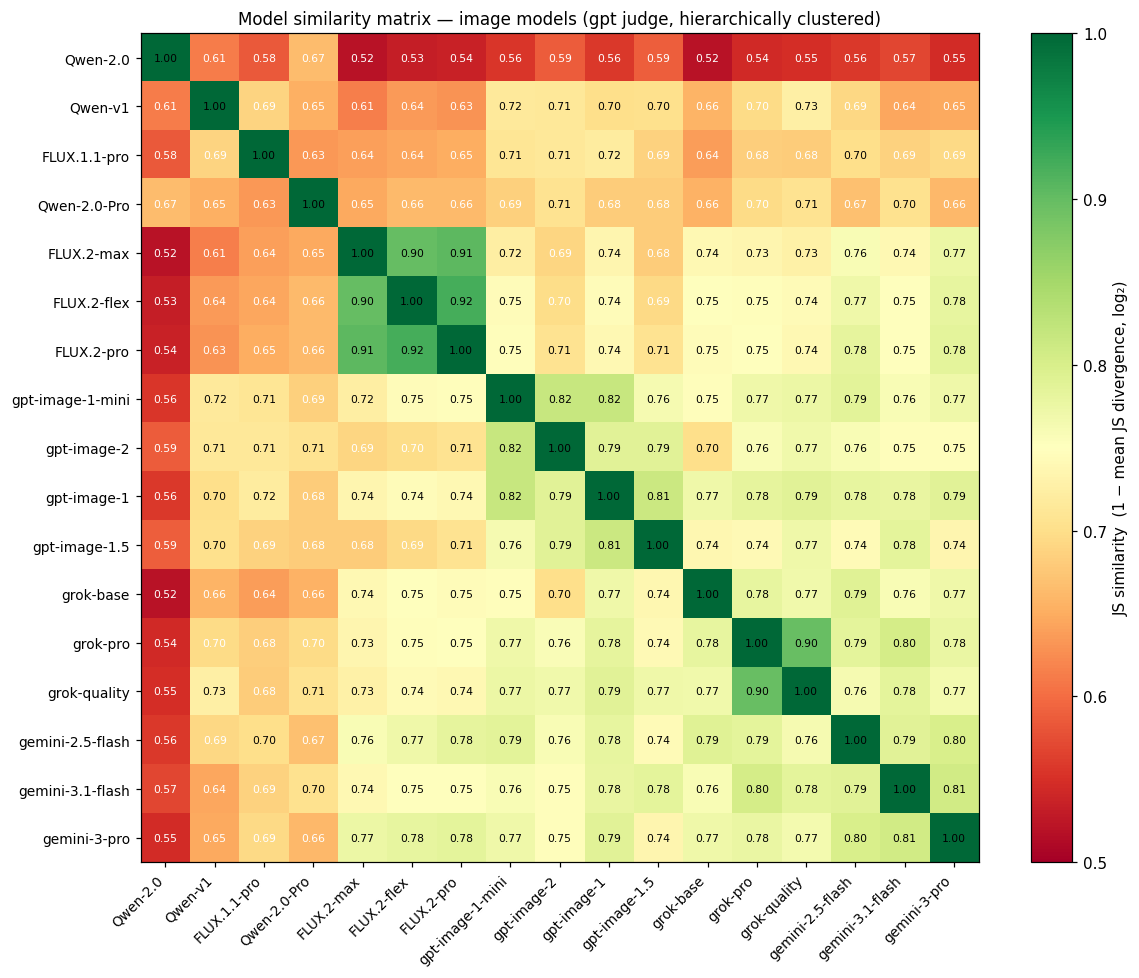

In [23]:
def plot_similarity(modality, judge='gpt', title_suffix=''):
    hist = hist_image if modality == 'image' else hist_text
    models = IMAGE_MODELS if modality == 'image' else TEXT_MODELS
    n = len(models)

    sum_js = np.zeros((n, n))
    cnt    = np.zeros((n, n))
    for word, word_data in hist.items():
        vocab = get_vocab(word, word_data, judge)
        dists = {i: d for i, m in enumerate(models)
                 if m in word_data
                 and (d := dist_for(word_data[m], vocab, judge)) is not None}
        for i in dists:
            for j in dists:
                if i >= j: continue
                v = js(dists[i], dists[j])
                sum_js[i,j] += v; sum_js[j,i] += v
                cnt[i,j] += 1;   cnt[j,i] += 1

    with np.errstate(invalid='ignore'):
        avg_js = np.where(cnt > 0, sum_js / cnt, np.nan)
    np.fill_diagonal(avg_js, 0.0)
    sim = 1 - avg_js

    filled = np.where(np.isnan(avg_js), np.nanmean(avg_js), avg_js)
    np.fill_diagonal(filled, 0.0)
    Z = linkage(filled[np.triu_indices(n, k=1)], method='average')
    order = leaves_list(Z)
    sim_ord = sim[np.ix_(order, order)]
    tick_labels = [dlabel(models[i]) for i in order]

    fig, ax = plt.subplots(figsize=(11, 9))
    im = ax.imshow(sim_ord, vmin=0.5, vmax=1.0, cmap='RdYlGn', aspect='auto')
    plt.colorbar(im, ax=ax, label='JS similarity  (1 − mean JS divergence, log₂)')
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(tick_labels, rotation=45, ha='right', fontsize=9)
    ax.set_yticklabels(tick_labels, fontsize=9)
    for i in range(n):
        for j in range(n):
            v = sim_ord[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.2f}', ha='center', va='center',
                        fontsize=7, color='black' if v > 0.7 else 'white')
    ax.set_title(f'Model similarity matrix — {modality} models ({judge} judge, hierarchically clustered){title_suffix}',
                 fontsize=11)
    plt.tight_layout(); plt.show()
    return avg_js, models

print('=== IMAGE models ===')
avg_js_img, img_models = plot_similarity('image')

=== TEXT models ===


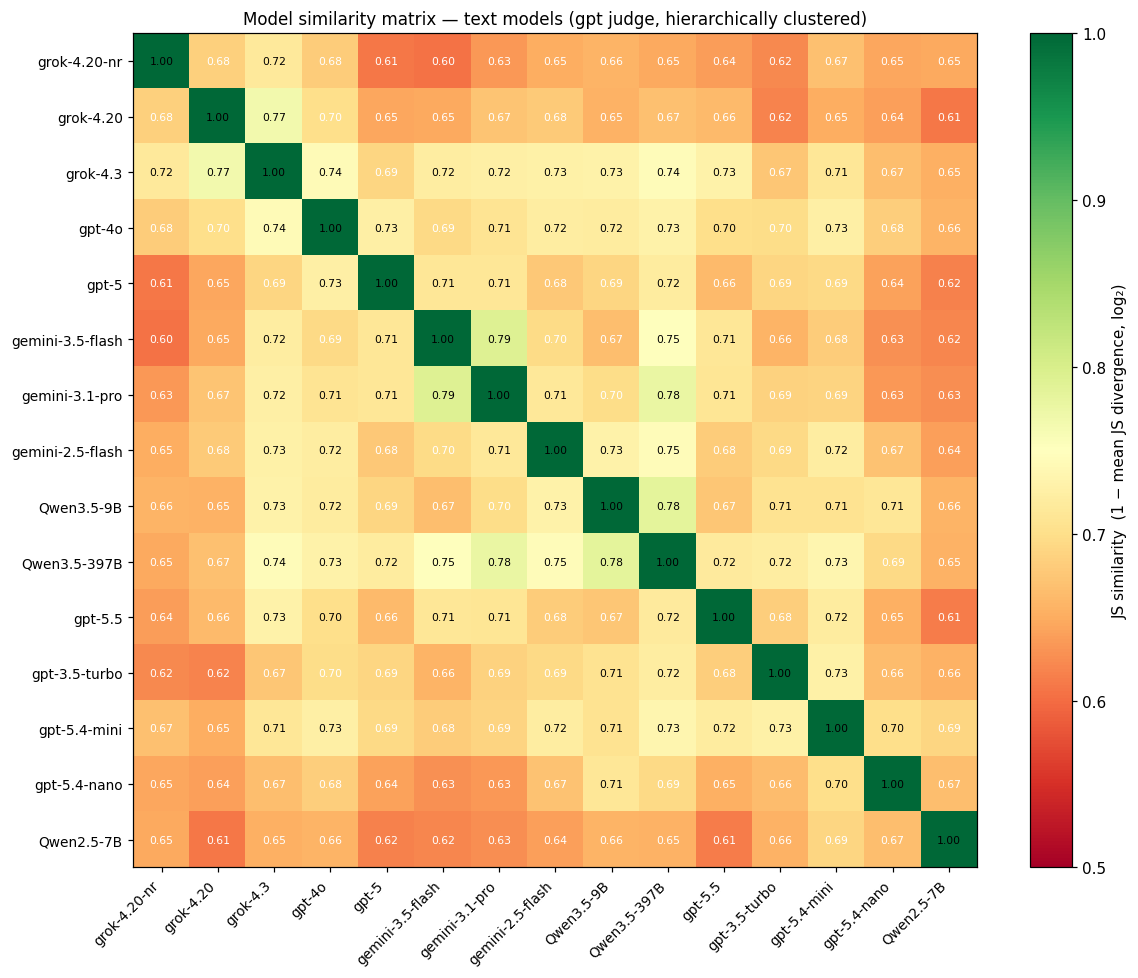

In [24]:
print('=== TEXT models ===')
avg_js_txt, txt_models = plot_similarity('text')

## 4. Family Cohesion

Do models from the same provider cluster together? We measure **within-family JS** (mean pairwise distance among siblings) vs **between-family JS** (mean distance to all other families' models). A high ratio means models within a family are more similar to each other than to outsiders — i.e., the provider has a consistent 'house style' for resolving ambiguity.

=== IMAGE family cohesion ===


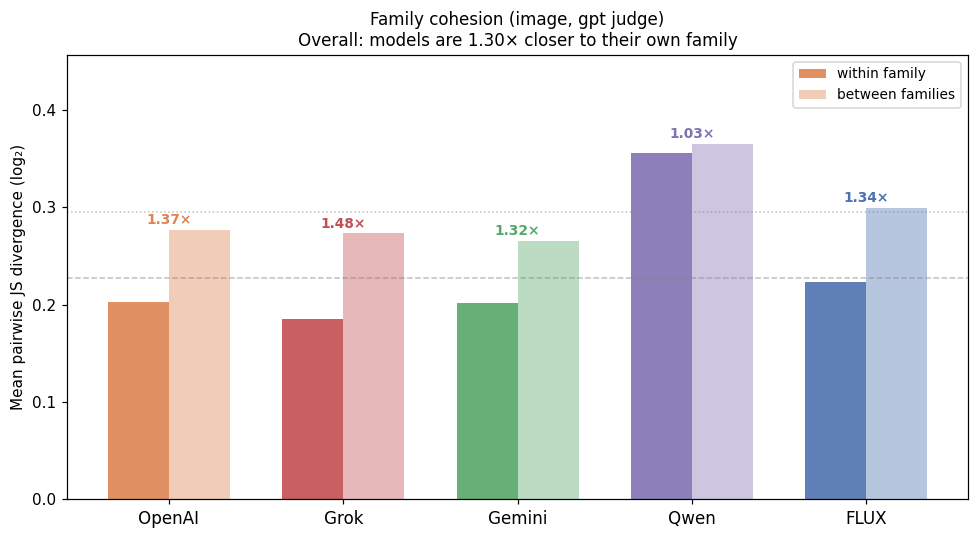

,Family,Within-family JS,Between-family JS,Ratio
0,OpenAI,0.2023,0.2770,1.37×
1,Grok,0.1850,0.2731,1.48×
2,Gemini,0.2012,0.2658,1.32×
3,Qwen,0.3561,0.3652,1.03×
4,FLUX,0.2229,0.2993,1.34×


In [25]:
def plot_family_cohesion(modality, judge='gpt'):
    hist = hist_image if modality == 'image' else hist_text
    models = IMAGE_MODELS if modality == 'image' else TEXT_MODELS
    n = len(models)

    # Build avg_js matrix
    sum_js = np.zeros((n, n)); cnt = np.zeros((n, n))
    for word, word_data in hist.items():
        vocab = get_vocab(word, word_data, judge)
        dists = {i: d for i, m in enumerate(models)
                 if m in word_data and (d := dist_for(word_data[m], vocab, judge)) is not None}
        for i in dists:
            for j in dists:
                if i >= j: continue
                v = js(dists[i], dists[j])
                sum_js[i,j] += v; sum_js[j,i] += v
                cnt[i,j] += 1;   cnt[j,i] += 1
    with np.errstate(invalid='ignore'):
        avg_js = np.where(cnt > 0, sum_js / cnt, np.nan)
    np.fill_diagonal(avg_js, 0.0)

    fams = registry.families(modality)
    rows, within_all, between_all = [], [], []
    for fam in fams:
        fi   = [i for i, m in enumerate(models) if family_of(m) == fam]
        oi   = [i for i, m in enumerate(models) if family_of(m) != fam]
        wi   = [avg_js[i,j] for i,j in combinations(fi, 2) if not np.isnan(avg_js[i,j])]
        bi   = [avg_js[i,j] for i in fi for j in oi if not np.isnan(avg_js[i,j])]
        w = np.mean(wi) if wi else np.nan
        b = np.mean(bi) if bi else np.nan
        rows.append((fam, w, b, b/w if w and w > 0 else np.nan))
        within_all.extend(wi); between_all.extend(bi)

    w_all = np.mean(within_all); b_all = np.mean(between_all)
    ratio_all = b_all / w_all

    fig, ax = plt.subplots(figsize=(9, 5))
    x = np.arange(len(fams))
    colors = [fcolor(f) for f in fams]
    ax.bar(x - 0.175, [r[1] for r in rows], 0.35, color=colors, alpha=0.9, label='within family')
    ax.bar(x + 0.175, [r[2] for r in rows], 0.35, color=colors, alpha=0.4, label='between families')
    ax.axhline(w_all, color='gray', lw=1, ls='--', alpha=0.5)
    ax.axhline(b_all, color='gray', lw=1, ls=':', alpha=0.5)
    for i, (fam, w, b, r) in enumerate(rows):
        if not np.isnan(r):
            ax.text(i, max(w, b) + 0.006, f'{r:.2f}×', ha='center',
                    fontsize=9, fontweight='bold', color=fcolor(fam))
    ax.set_xticks(x); ax.set_xticklabels([flabel(f) for f in fams], fontsize=11)
    ax.set_ylabel('Mean pairwise JS divergence (log₂)')
    ax.set_title(f'Family cohesion ({modality}, {judge} judge)\n'
                 f'Overall: models are {ratio_all:.2f}× closer to their own family', fontsize=11)
    ax.legend(fontsize=9)
    valid_b = [r[2] for r in rows if not np.isnan(r[2])]
    if valid_b: ax.set_ylim(0, max(valid_b) * 1.25)
    plt.tight_layout(); plt.show()

    df = pd.DataFrame([{'Family': flabel(f), 'Within-family JS': f'{w:.4f}',
                         'Between-family JS': f'{b:.4f}', 'Ratio': f'{r:.2f}×'}
                        for f, w, b, r in rows])
    display(df)

print('=== IMAGE family cohesion ===')
plot_family_cohesion('image')

=== TEXT family cohesion ===


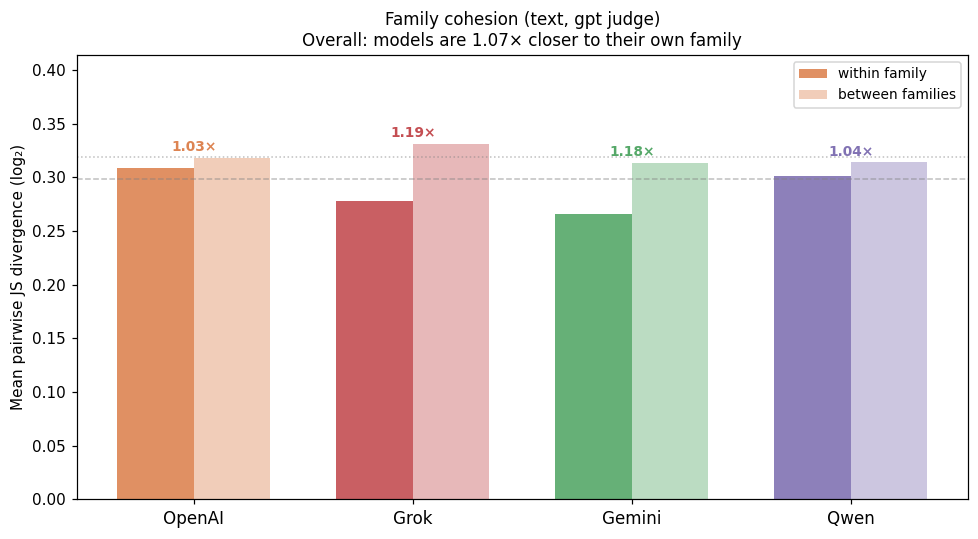

,Family,Within-family JS,Between-family JS,Ratio
0,OpenAI,0.3086,0.3183,1.03×
1,Grok,0.2780,0.3312,1.19×
2,Gemini,0.2657,0.3137,1.18×
3,Qwen,0.3014,0.3142,1.04×


In [26]:
print('=== TEXT family cohesion ===')
plot_family_cohesion('text')

## 5. Alignment with Text-Frequency Priors

We measure how much each model's sense distribution diverges from the text-frequency prior using **JS(prior ‖ model)**. A low score means the model picks senses roughly as often as they occur in ordinary English. A high score means it has developed its own bias — e.g. always drawing `bank` as a financial institution even though the river sense is more common in natural text.

### 5a. Per-model mean JS from prior (ranked bar chart)


=== IMAGE: text-frequency divergence ===


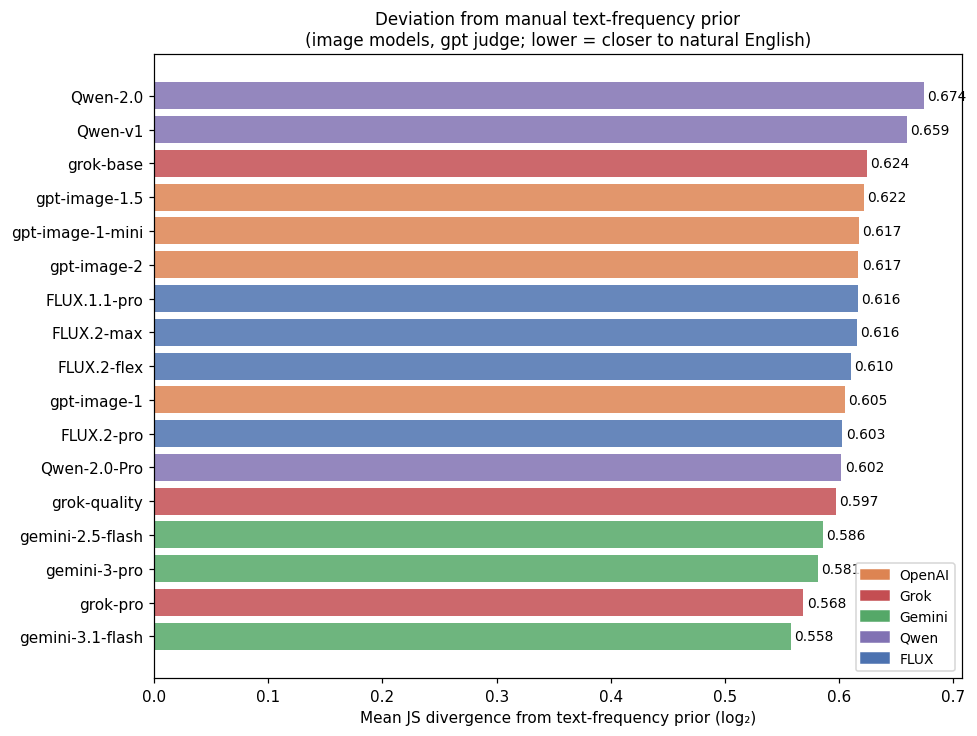

In [27]:
def plot_text_divergence(modality, judge='gpt', prior_name='manual'):
    hist = hist_image if modality == 'image' else hist_text
    models = IMAGE_MODELS if modality == 'image' else TEXT_MODELS
    freq = freq_manual if prior_name == 'manual' else freq_wiki

    model_js = {}
    for word, word_data in hist.items():
        vocab = get_vocab(word, word_data, judge)
        tf = text_dist(word, vocab, freq)
        if tf is None: continue
        for m in models:
            if m not in word_data: continue
            d = dist_for(word_data[m], vocab, judge)
            if d is None: continue
            v = js(tf, d)
            if not np.isnan(v):
                model_js.setdefault(m, []).append(v)

    ranked = sorted(((m, float(np.mean(v))) for m, v in model_js.items()), key=lambda x: x[1])
    labels  = [dlabel(m) for m, _ in ranked]
    values  = [v for _, v in ranked]
    colors  = [fcolor(family_of(m)) for m, _ in ranked]

    fig, ax = plt.subplots(figsize=(9, max(5, len(ranked) * 0.4)))
    y = np.arange(len(ranked))
    ax.barh(y, values, color=colors, alpha=0.85)
    ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=10)
    ax.set_xlabel('Mean JS divergence from text-frequency prior (log₂)')
    ax.set_title(f'Deviation from {prior_name} text-frequency prior\n'
                 f'({modality} models, {judge} judge; lower = closer to natural English)', fontsize=11)
    for i, (m, v) in enumerate(ranked):
        ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
    fams = registry.families(modality)
    ax.legend(handles=[Patch(color=fcolor(f), label=flabel(f)) for f in fams],
              loc='lower right', fontsize=9)
    plt.tight_layout(); plt.show()

print('=== IMAGE: text-frequency divergence ===')
plot_text_divergence('image')

=== TEXT: text-frequency divergence ===


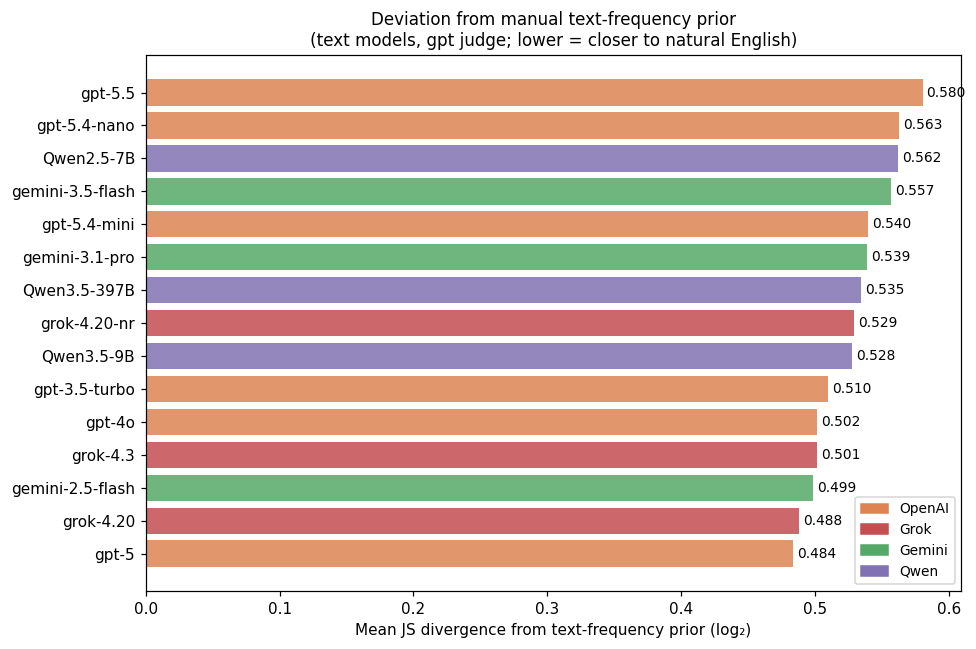

In [28]:
print('=== TEXT: text-frequency divergence ===')
plot_text_divergence('text')

### 5b. Generation Trend — Does newer = closer to natural English?

We plot each family's models on the x-axis by generation index (oldest=1, newest=N) and their mean JS from the text-frequency prior on the y-axis. A downward slope would mean newer models increasingly match natural English usage. An upward slope would mean newer models develop *more* idiosyncratic biases.

=== IMAGE: generation trend ===


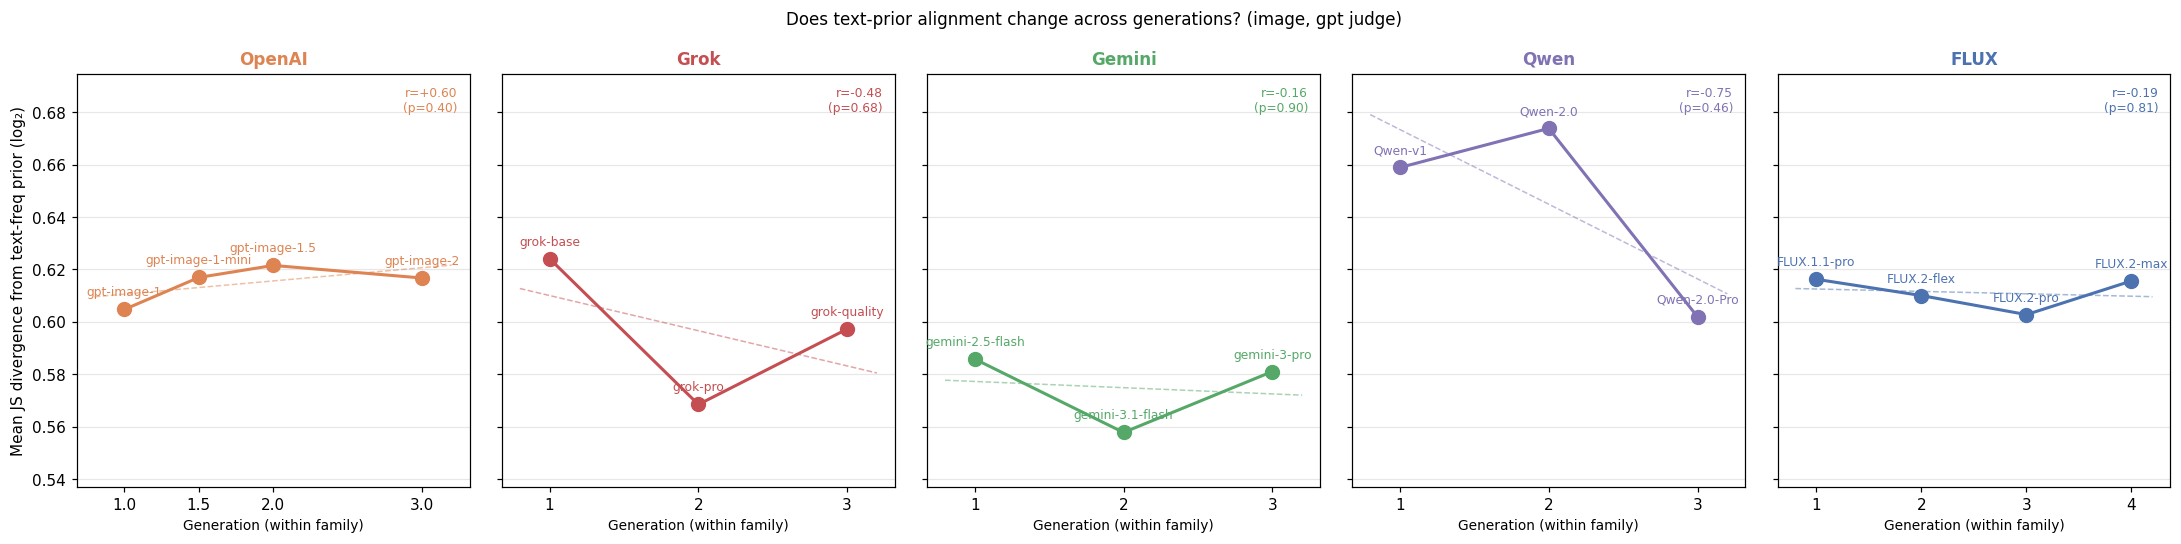

In [29]:
def plot_generation_trend(modality, judge='gpt', prior_name='manual'):
    hist = hist_image if modality == 'image' else hist_text
    freq = freq_manual if prior_name == 'manual' else freq_wiki
    gen_order = registry.generation_order(modality)

    model_js = {}
    for fam, triples in gen_order.items():
        for key, gen, lbl in triples:
            vals = []
            for word, word_data in hist.items():
                if key not in word_data: continue
                vocab = get_vocab(word, word_data, judge)
                tf = text_dist(word, vocab, freq)
                d  = dist_for(word_data[key], vocab, judge)
                if tf is None or d is None: continue
                v = js(tf, d)
                if not np.isnan(v): vals.append(v)
            if vals: model_js[key] = float(np.mean(vals))

    fams = list(gen_order)
    fig, axes = plt.subplots(1, len(fams), figsize=(4 * len(fams), 5), sharey=True)
    if len(fams) == 1: axes = [axes]

    all_gens, all_js_v = [], []
    for ax, fam in zip(axes, fams):
        color = fcolor(fam)
        triples = [(gen, model_js[k], lbl)
                   for k, gen, lbl in gen_order[fam] if k in model_js]
        if not triples: ax.set_visible(False); continue
        gens, jsv, labels = zip(*triples)
        ax.plot(gens, jsv, color=color, lw=2, marker='o', markersize=9, zorder=3)
        for g, j, lbl in zip(gens, jsv, labels):
            ax.text(g, j + 0.004, lbl, ha='center', va='bottom', fontsize=8, color=color)
        if len(set(gens)) >= 3:
            coeffs = np.polyfit(gens, jsv, 1)
            xs = np.linspace(min(gens) - 0.2, max(gens) + 0.2, 50)
            ax.plot(xs, np.polyval(coeffs, xs), color=color, lw=1, ls='--', alpha=0.5)
            r, pv = pearsonr(gens, jsv)
            ax.text(0.97, 0.97, f'r={r:+.2f}\n(p={pv:.2f})', transform=ax.transAxes,
                    ha='right', va='top', fontsize=8, color=color)
        all_gens.extend(gens); all_js_v.extend(jsv)
        ax.set_title(flabel(fam), fontsize=11, fontweight='bold', color=color)
        ax.set_xlabel('Generation (within family)', fontsize=9)
        ax.set_xticks(sorted(set(gens)))
        ax.grid(axis='y', alpha=0.3)

    if all_js_v:
        lo, hi = min(all_js_v), max(all_js_v)
        pad = (hi - lo) * 0.18 or 0.04
        axes[0].set_ylim(lo - pad, hi + pad)
    axes[0].set_ylabel('Mean JS divergence from text-freq prior (log₂)')
    fig.suptitle(f'Does text-prior alignment change across generations? ({modality}, {judge} judge)',
                 fontsize=11)
    plt.tight_layout(); plt.show()

print('=== IMAGE: generation trend ===')
plot_generation_trend('image')

=== TEXT: generation trend ===


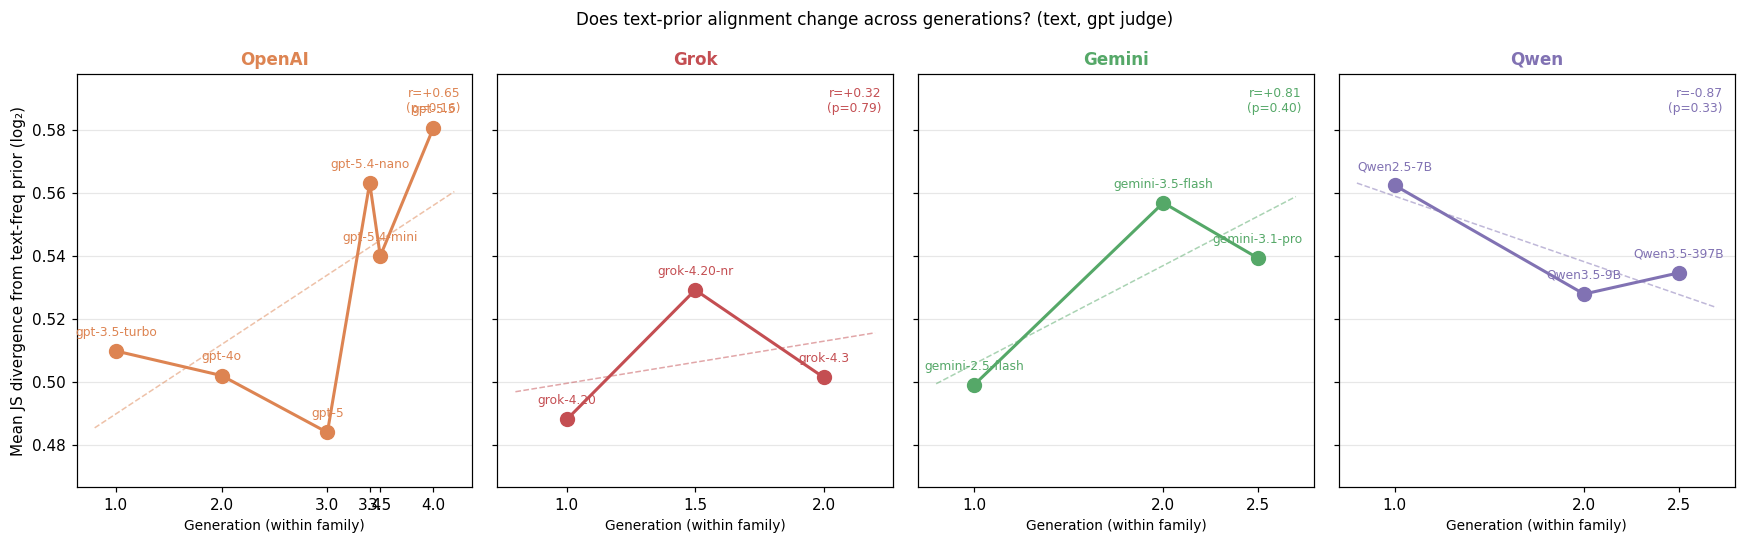

In [30]:
print('=== TEXT: generation trend ===')
plot_generation_trend('text')

## 6. Per-Word Inter-Model Disagreement

For each word, we compute the **mean pairwise JS divergence** across all models that have data for that word. High scores mark words where models strongly disagree — i.e., different models pick completely different senses. Low scores mark words where all models converge on the same dominant sense regardless of family.

Words with high disagreement are the most interesting lexical 'battlegrounds' for studying how training data and model architecture shape semantic representations.

=== IMAGE: word disagreement ===


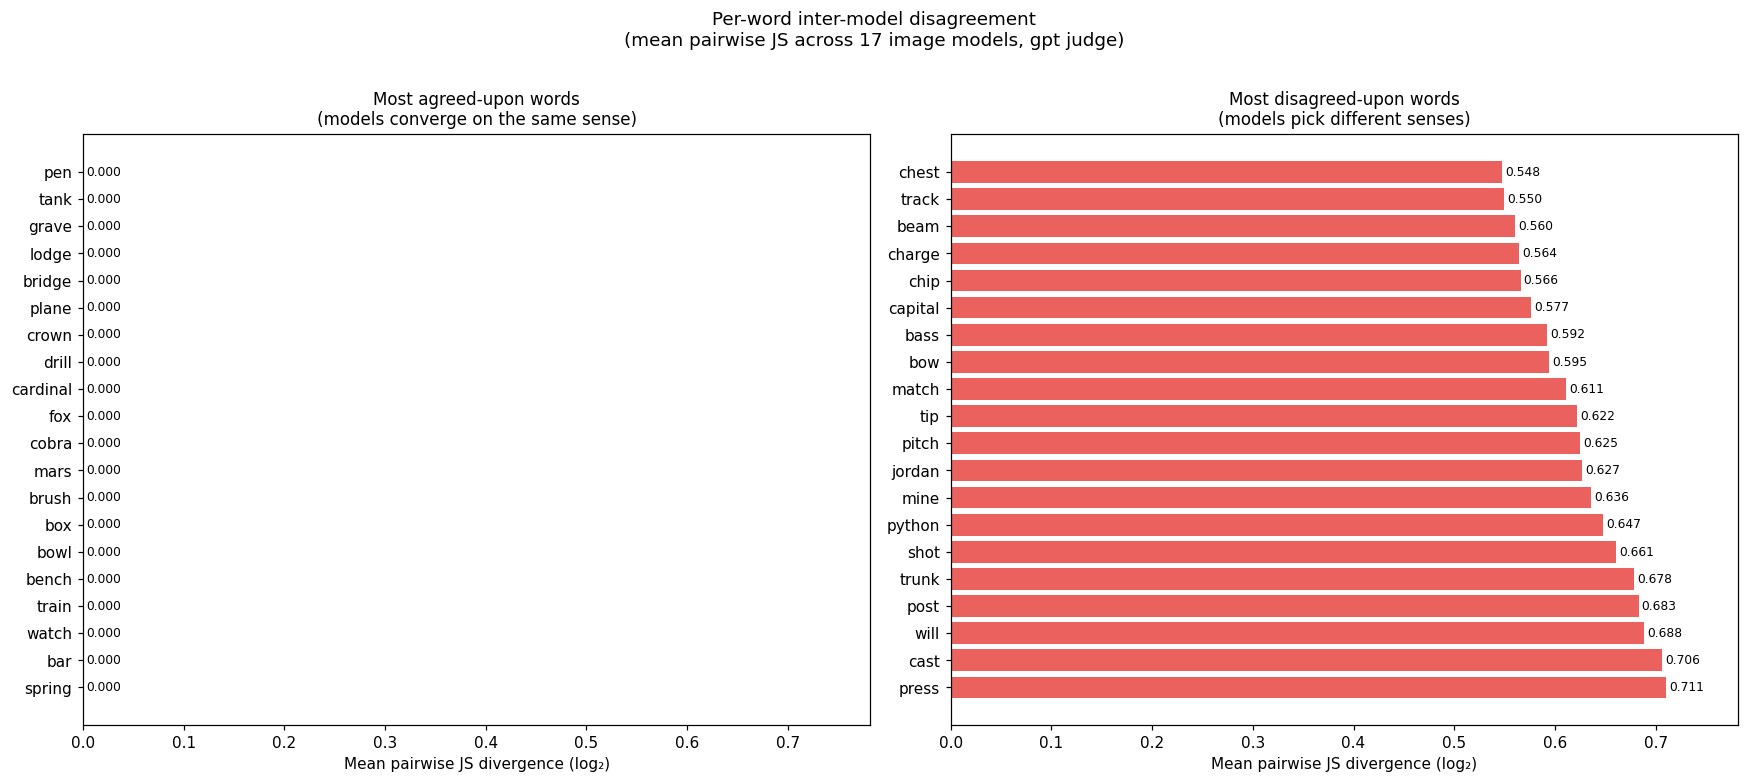

In [31]:
def plot_word_disagreement(modality, judge='gpt', top_n=20):
    hist = hist_image if modality == 'image' else hist_text
    models = IMAGE_MODELS if modality == 'image' else TEXT_MODELS

    word_scores = {}
    for word, word_data in hist.items():
        vocab = get_vocab(word, word_data, judge)
        dists = [d for m in models if m in word_data
                 and (d := dist_for(word_data[m], vocab, judge)) is not None]
        if len(dists) < 2: continue
        word_scores[word] = mean_pairwise_js(dists)

    ranked = sorted(word_scores.items(), key=lambda x: x[1])
    most_sim  = ranked[:top_n]
    most_diff = ranked[-top_n:]

    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    for ax, items, title, color in [
        (axes[0], most_sim, 'Most agreed-upon words\n(models converge on the same sense)', '#4CAF50'),
        (axes[1], list(reversed(most_diff)), 'Most disagreed-upon words\n(models pick different senses)', '#E53935'),
    ]:
        words  = [w for w, _ in items]
        scores = [s for _, s in items]
        y = np.arange(len(words))
        ax.barh(y, scores, color=color, alpha=0.8)
        ax.set_yticks(y); ax.set_yticklabels(words, fontsize=10)
        ax.set_xlabel('Mean pairwise JS divergence (log₂)')
        ax.set_xlim(0, max(word_scores.values()) * 1.1)
        ax.set_title(title, fontsize=11)
        for i, (w, s) in enumerate(items):
            ax.text(s + 0.003, i, f'{s:.3f}', va='center', fontsize=8)

    plt.suptitle(f'Per-word inter-model disagreement\n'
                 f'(mean pairwise JS across {len(models)} {modality} models, {judge} judge)',
                 fontsize=12, y=1.01)
    plt.tight_layout(); plt.show()

    return word_scores

print('=== IMAGE: word disagreement ===')
img_word_scores = plot_word_disagreement('image')

## 7. Cross-Modality Comparison: Image vs Text

All **100 words** have been classified in both modalities, enabling a full comparison. For each word and each model family, we aggregate the family's image-model sense distribution and its text-model distribution over a shared vocabulary, then compute JS divergence between the two.

- A **low** score means the family resolves the word the same way whether drawing a picture or writing a sentence — visual and verbal representations are aligned.
- A **high** score means the two modalities diverged — the family's image and text models have learned different dominant senses for the same word.

The second panel ranks words by how much they split image vs text interpretation across all families.


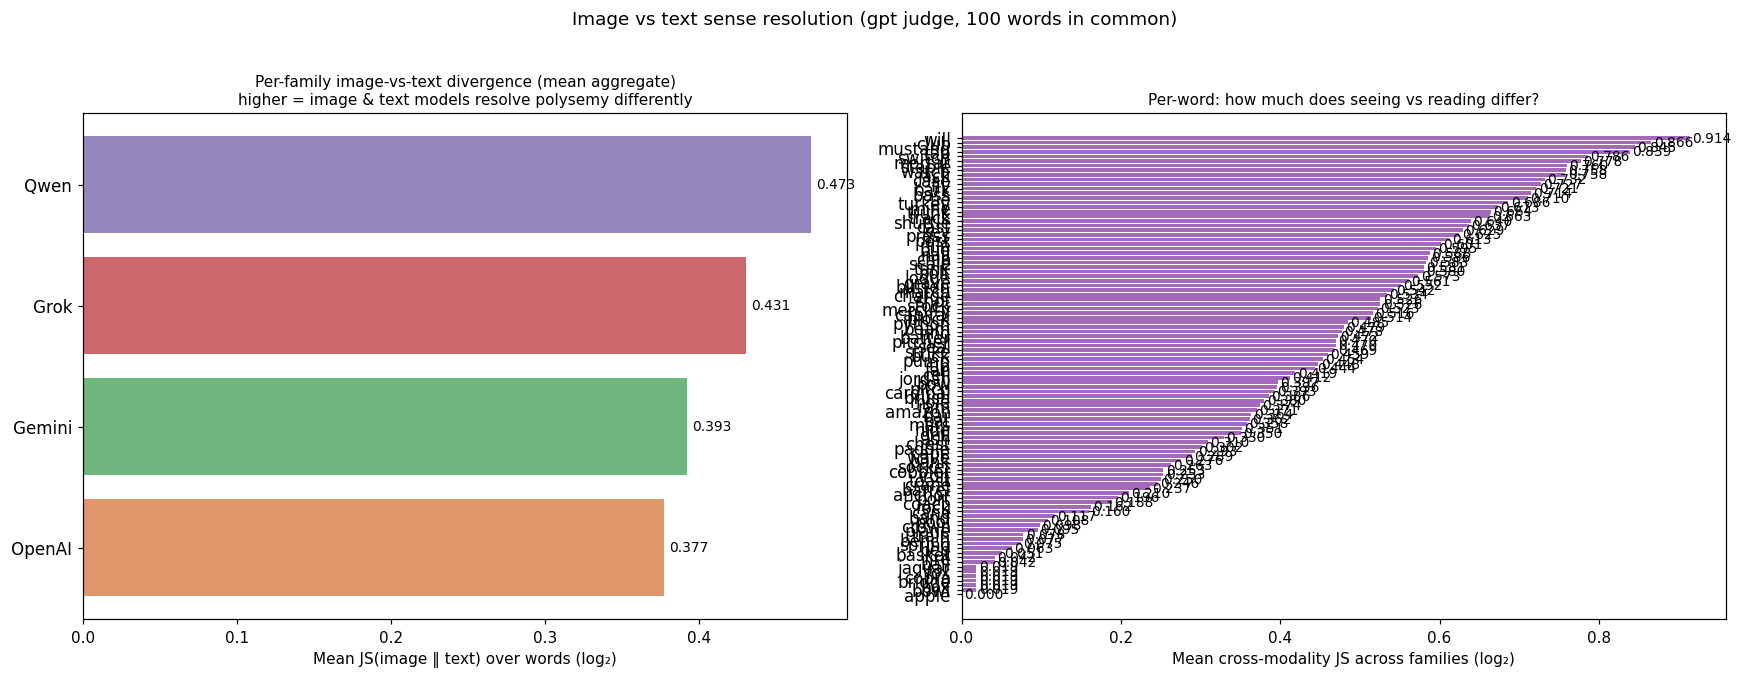


── Per-word side-by-side comparison (image vs text) ──


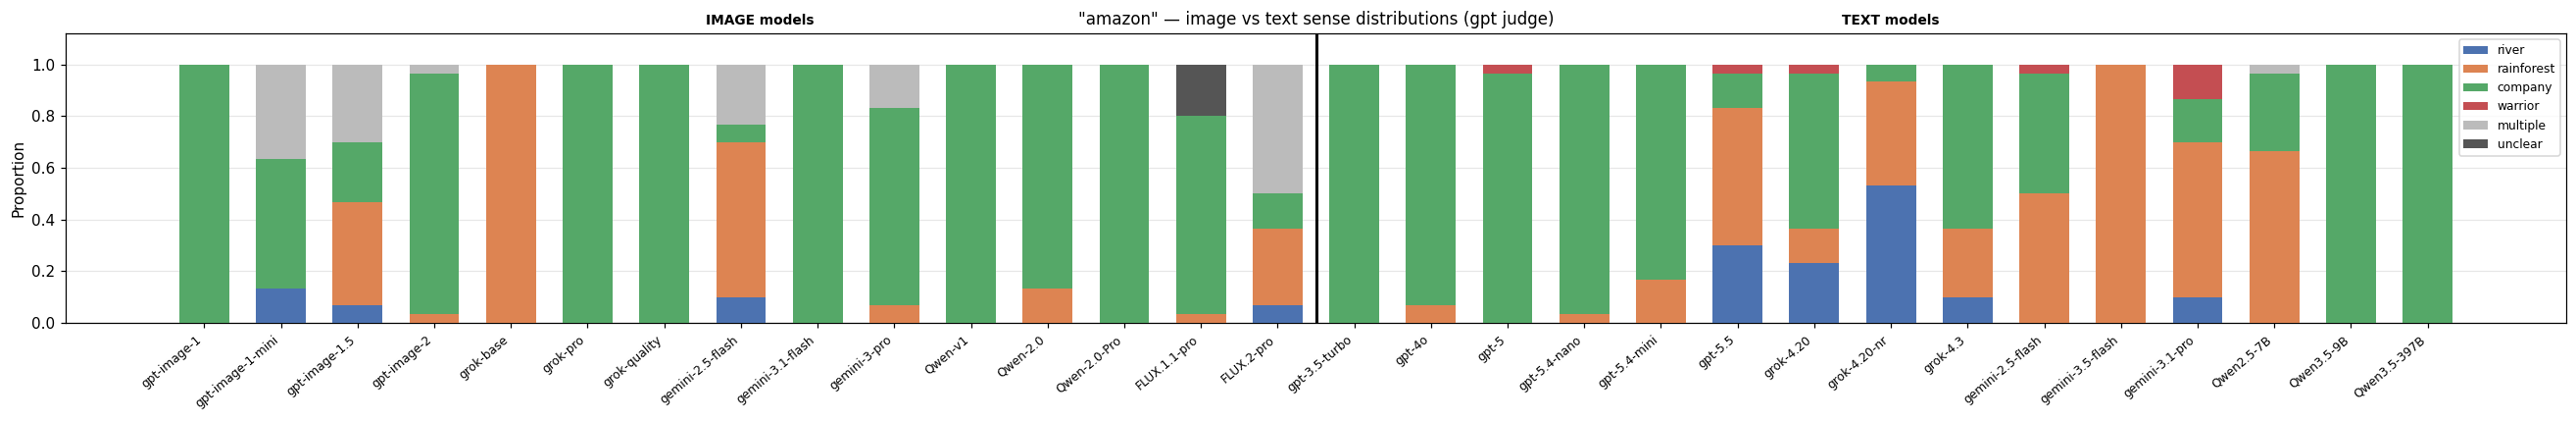

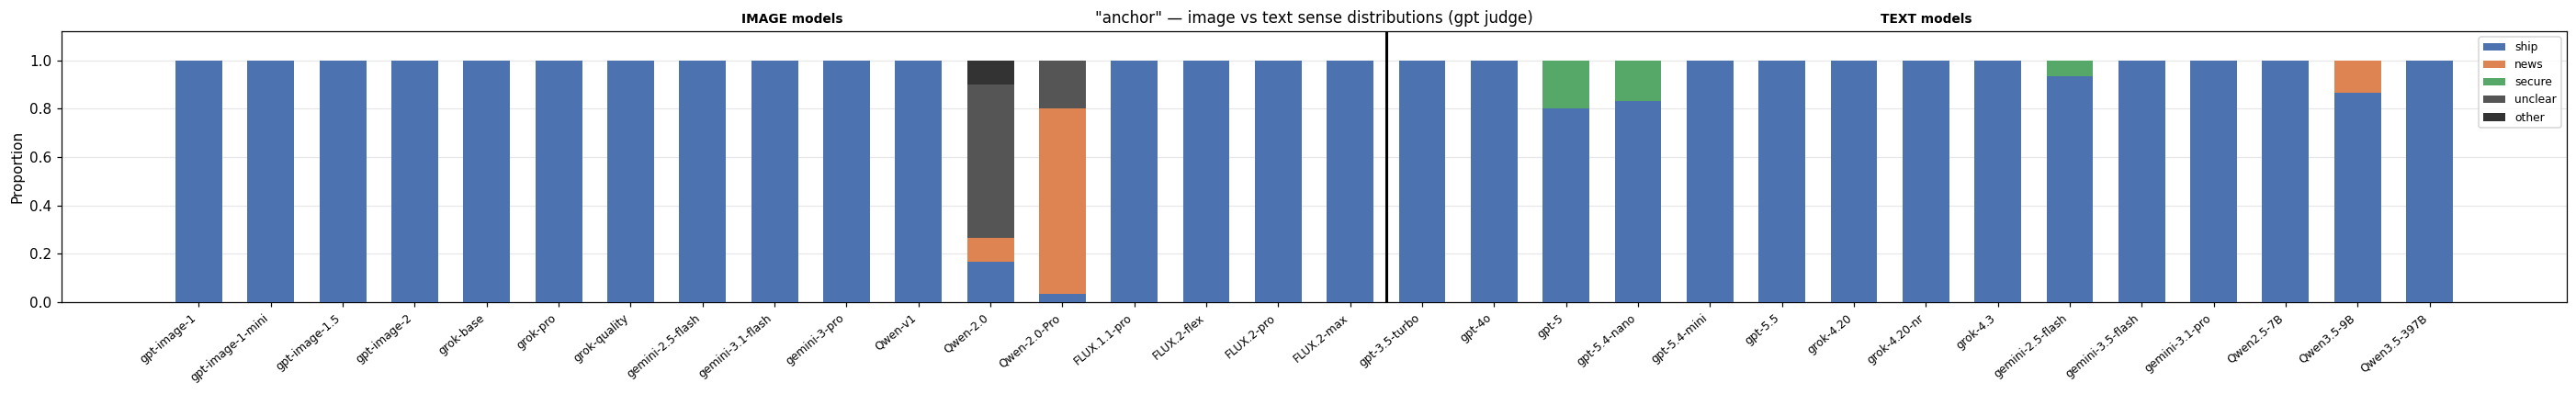

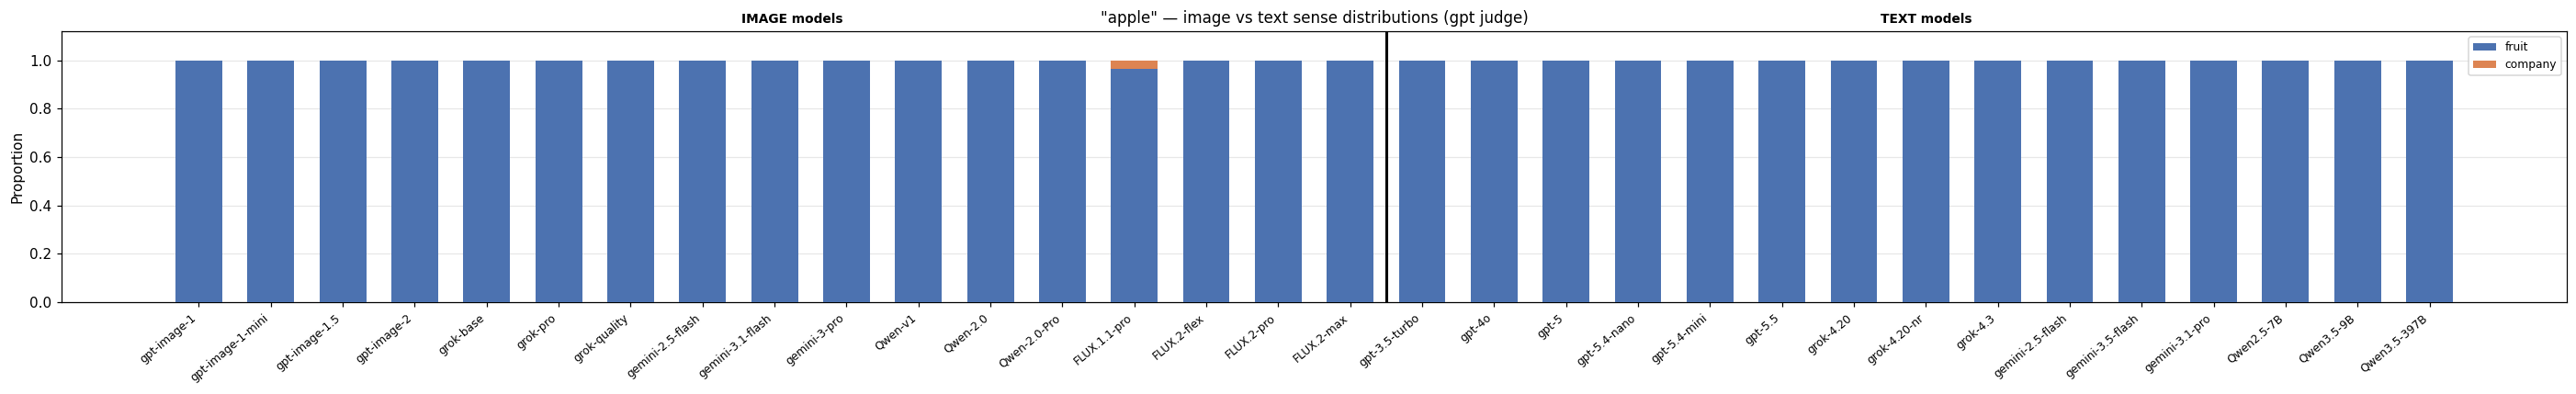

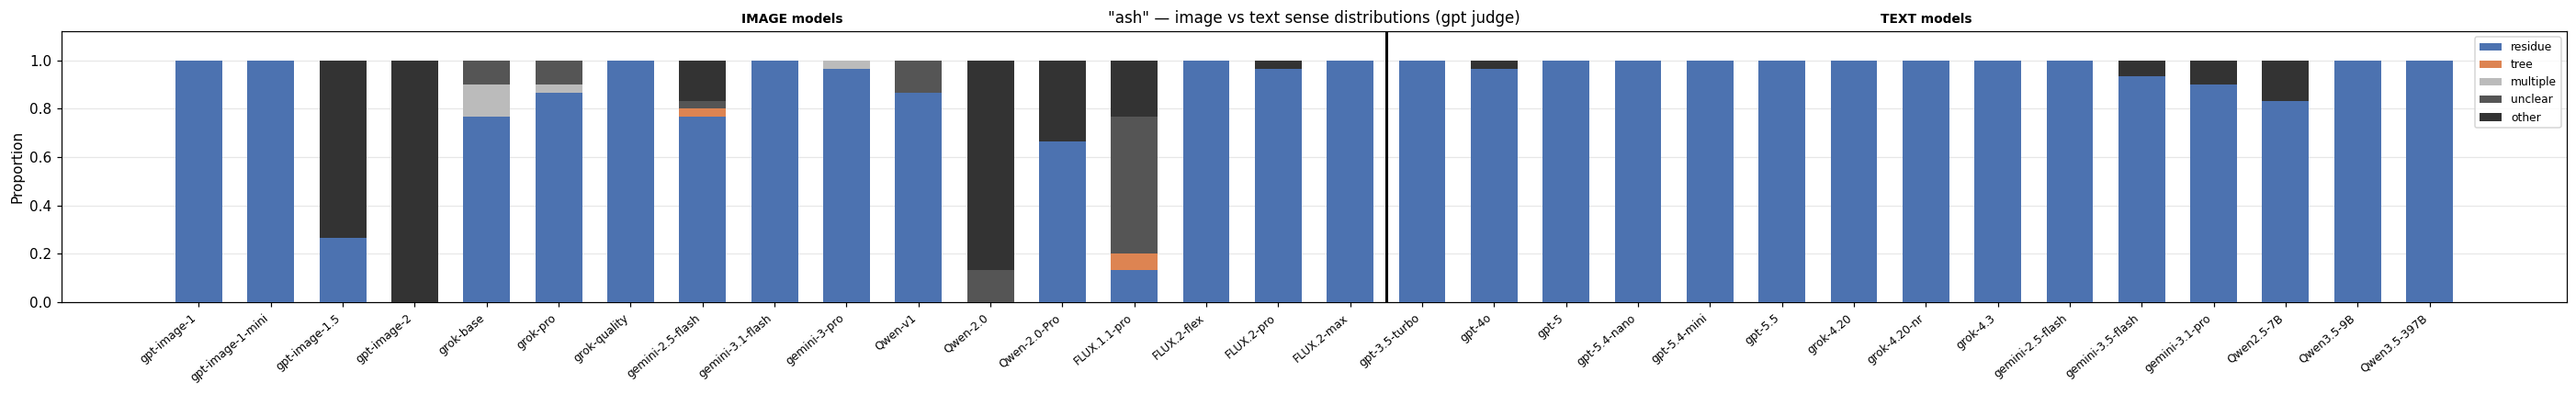

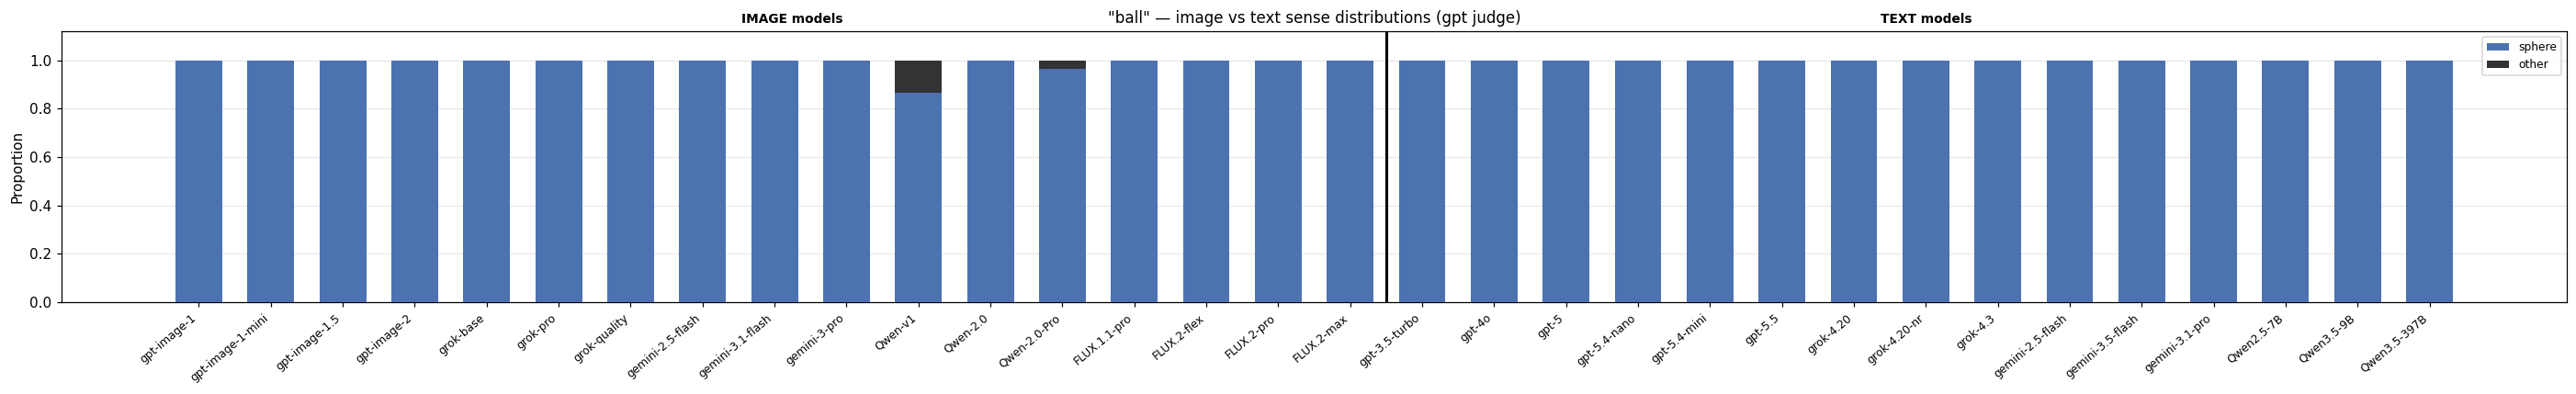

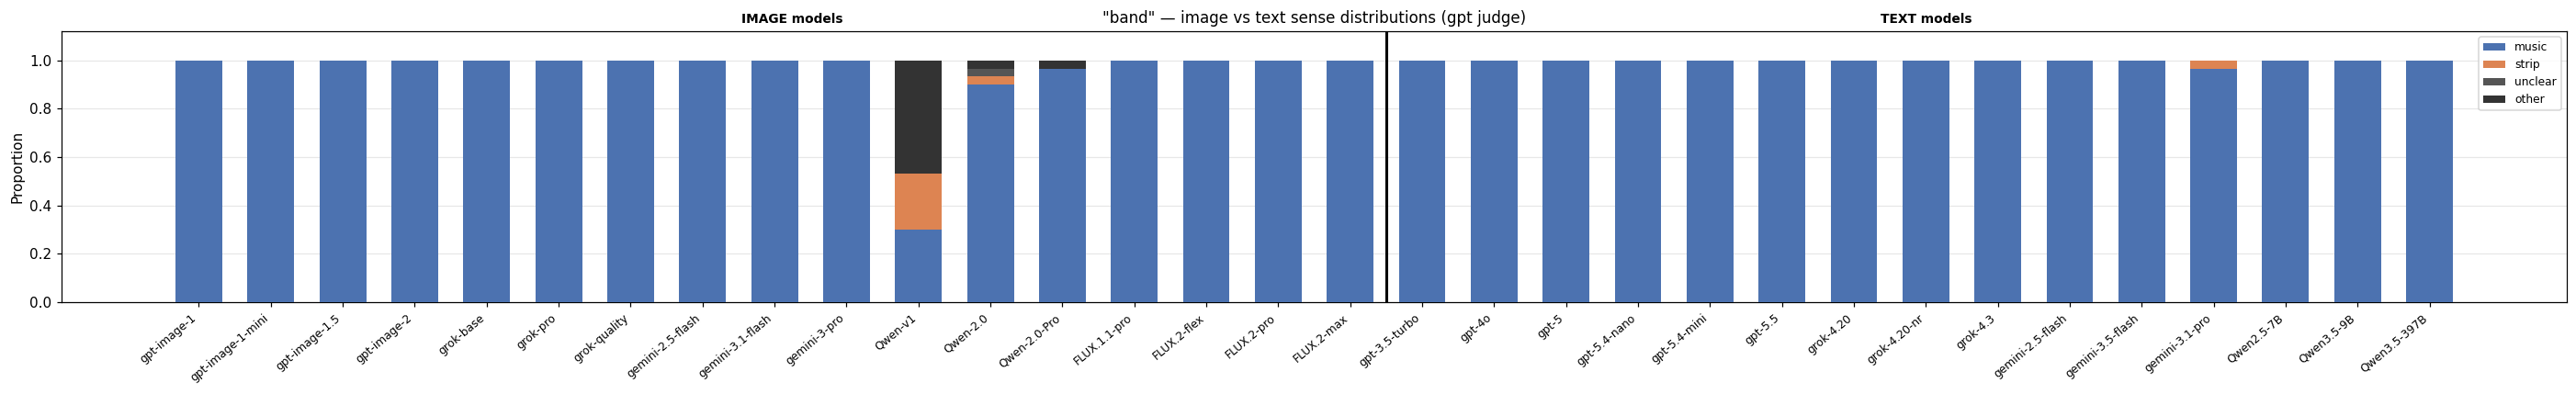

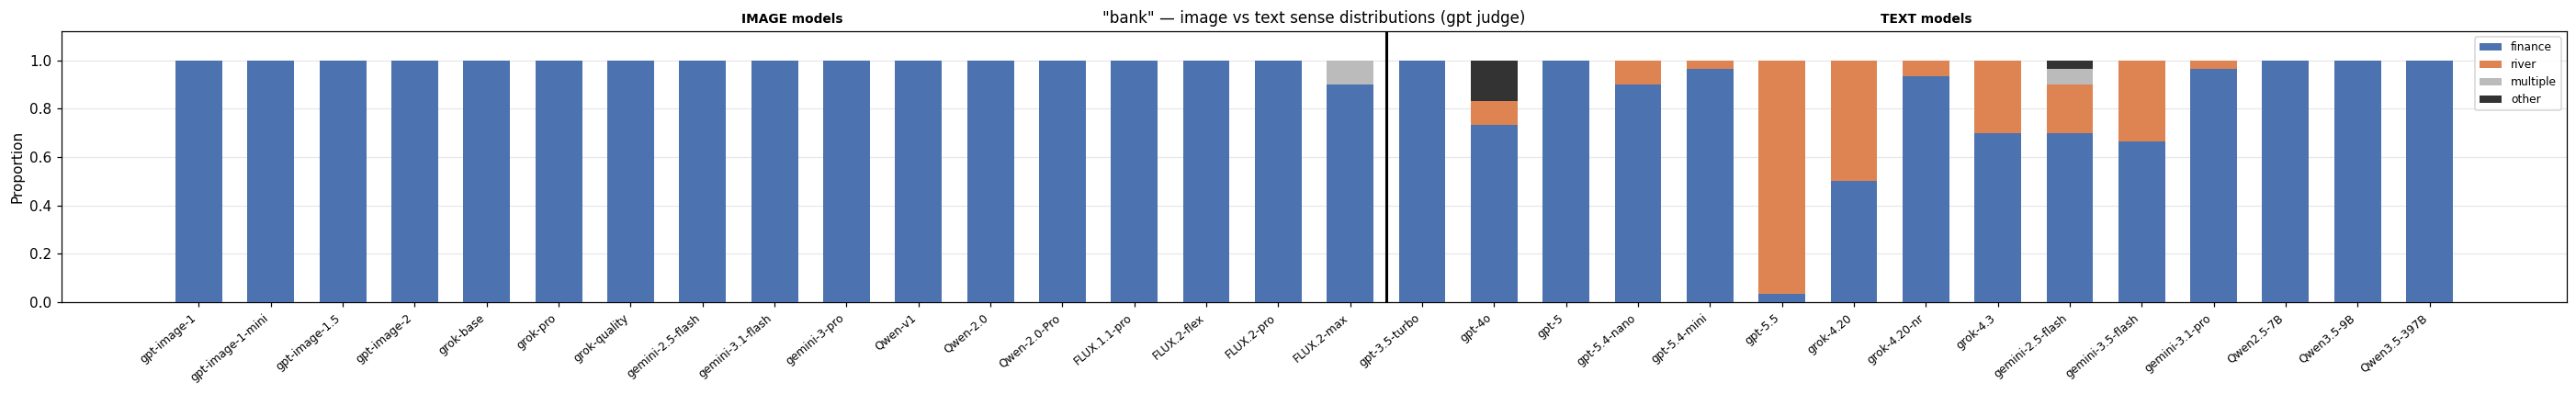

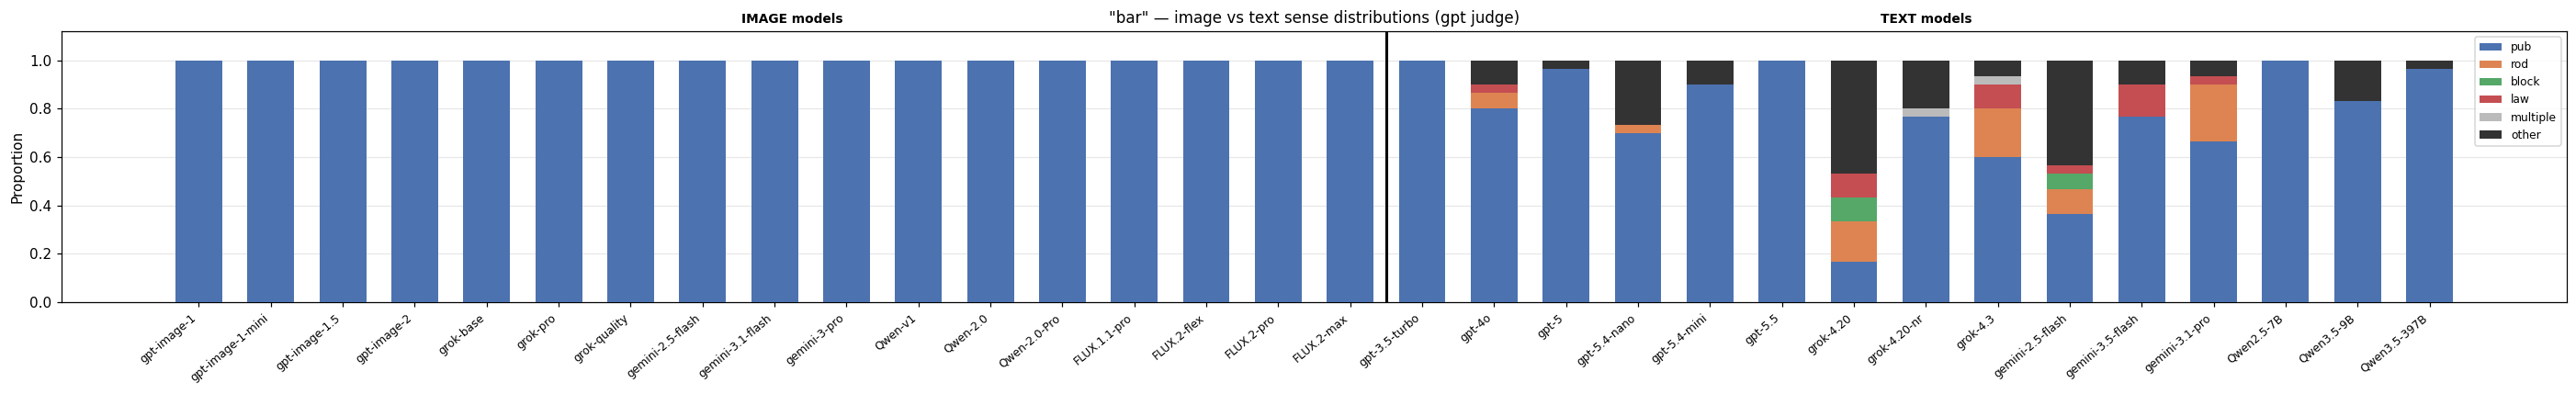

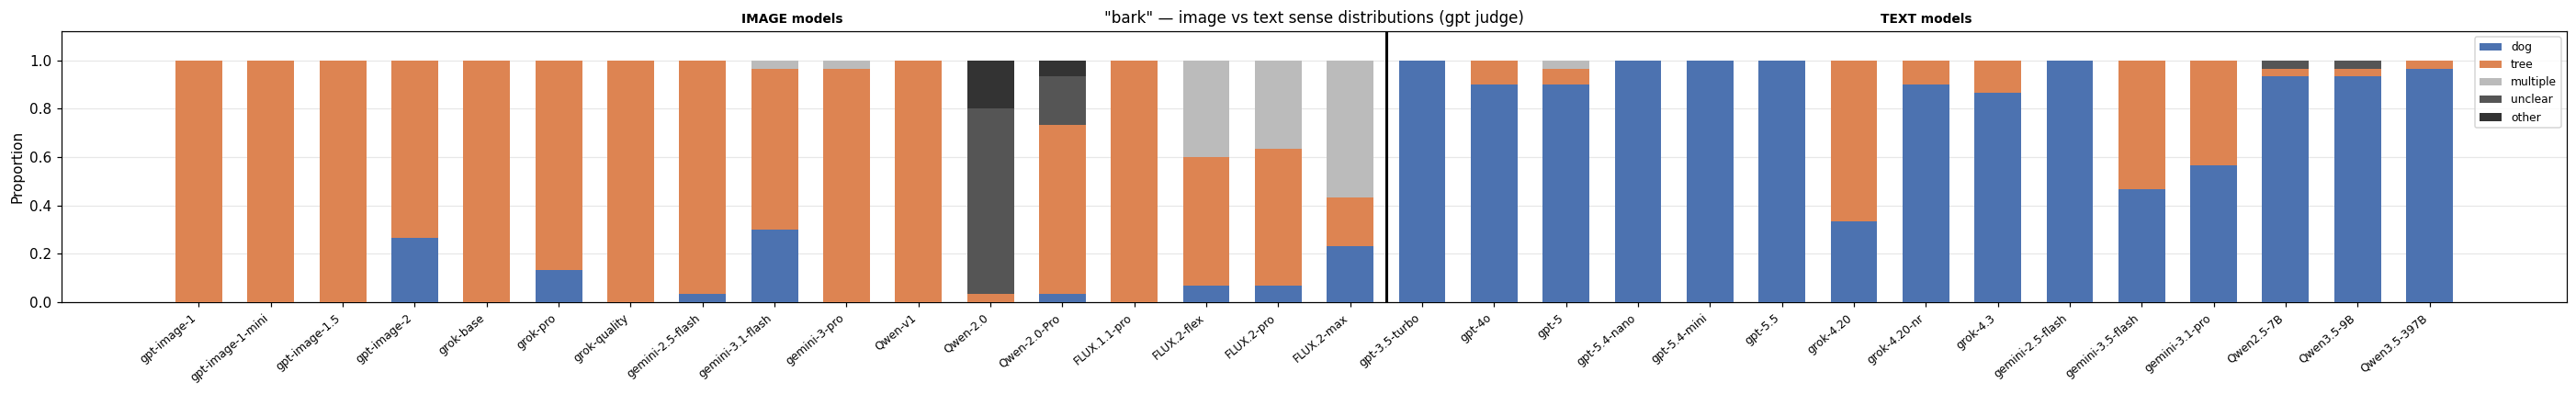

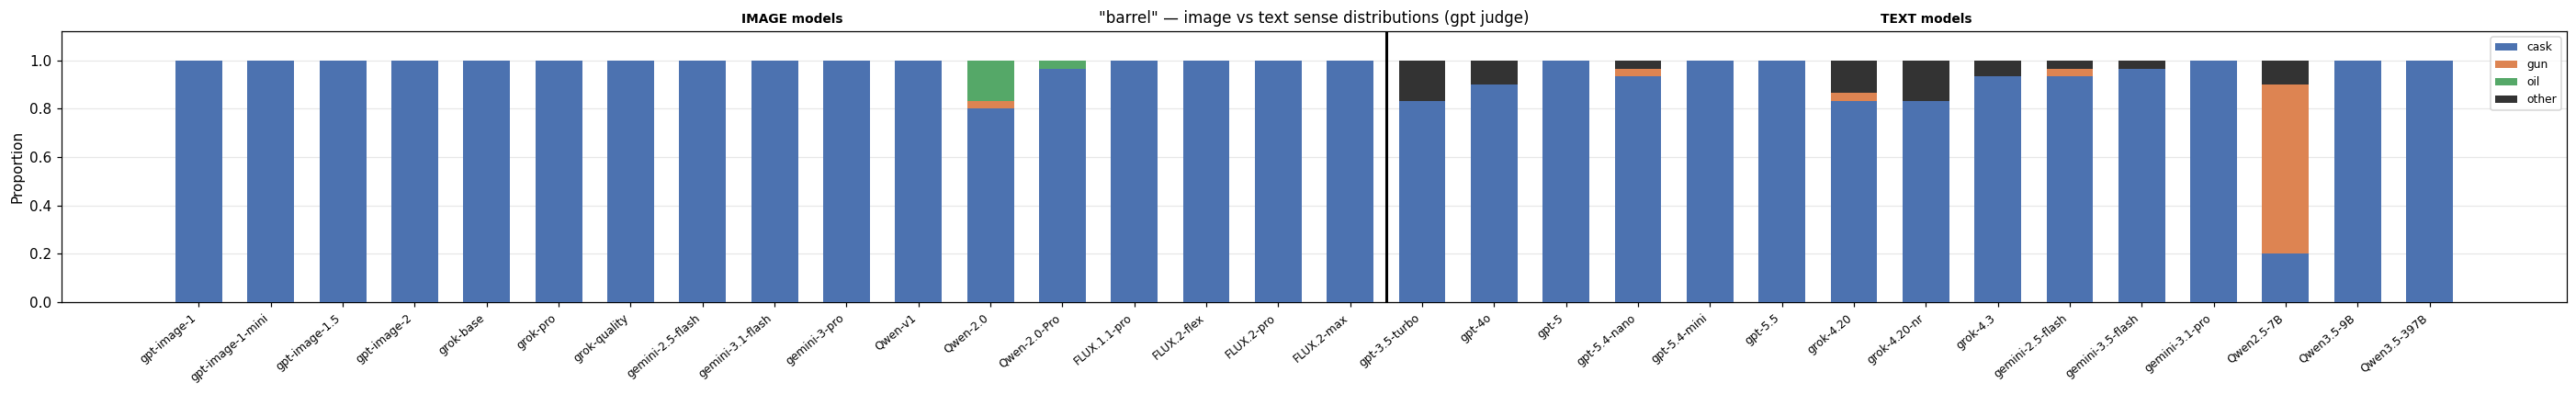

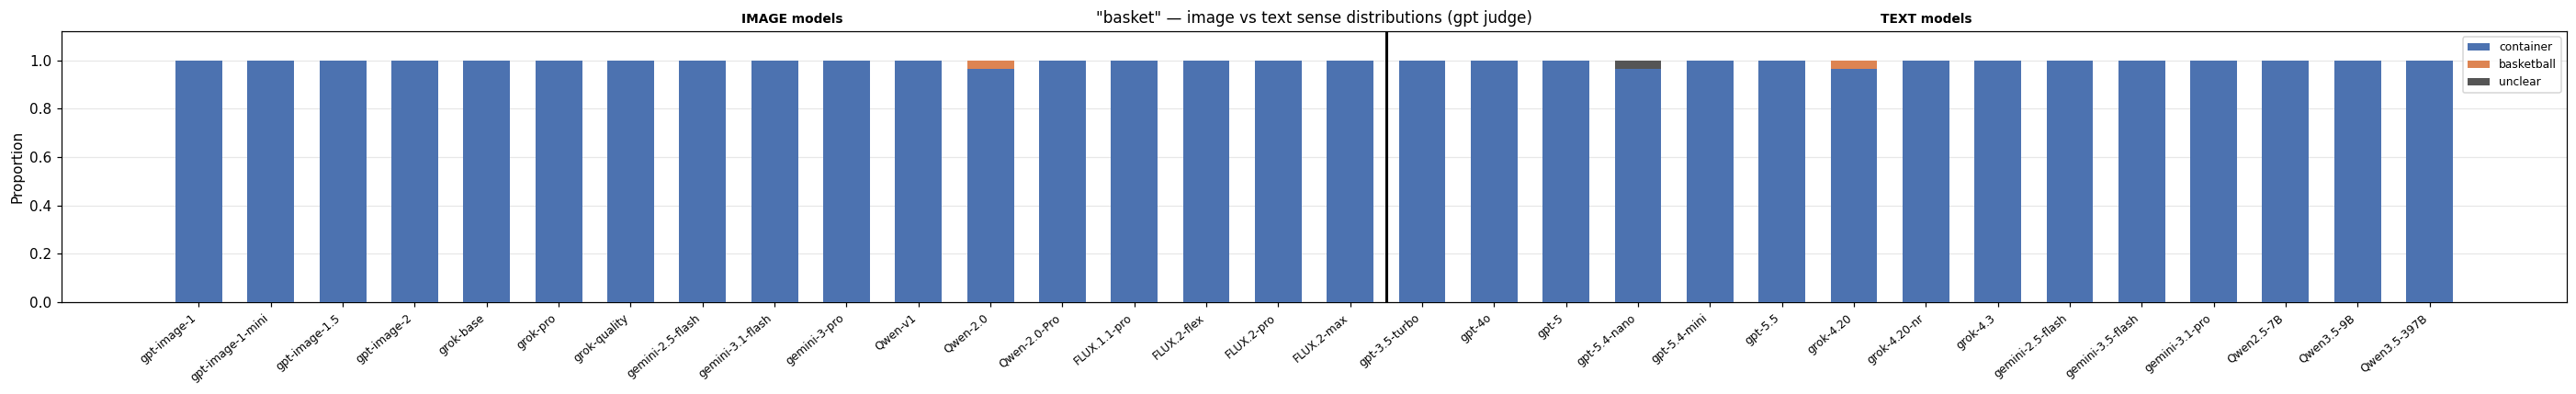

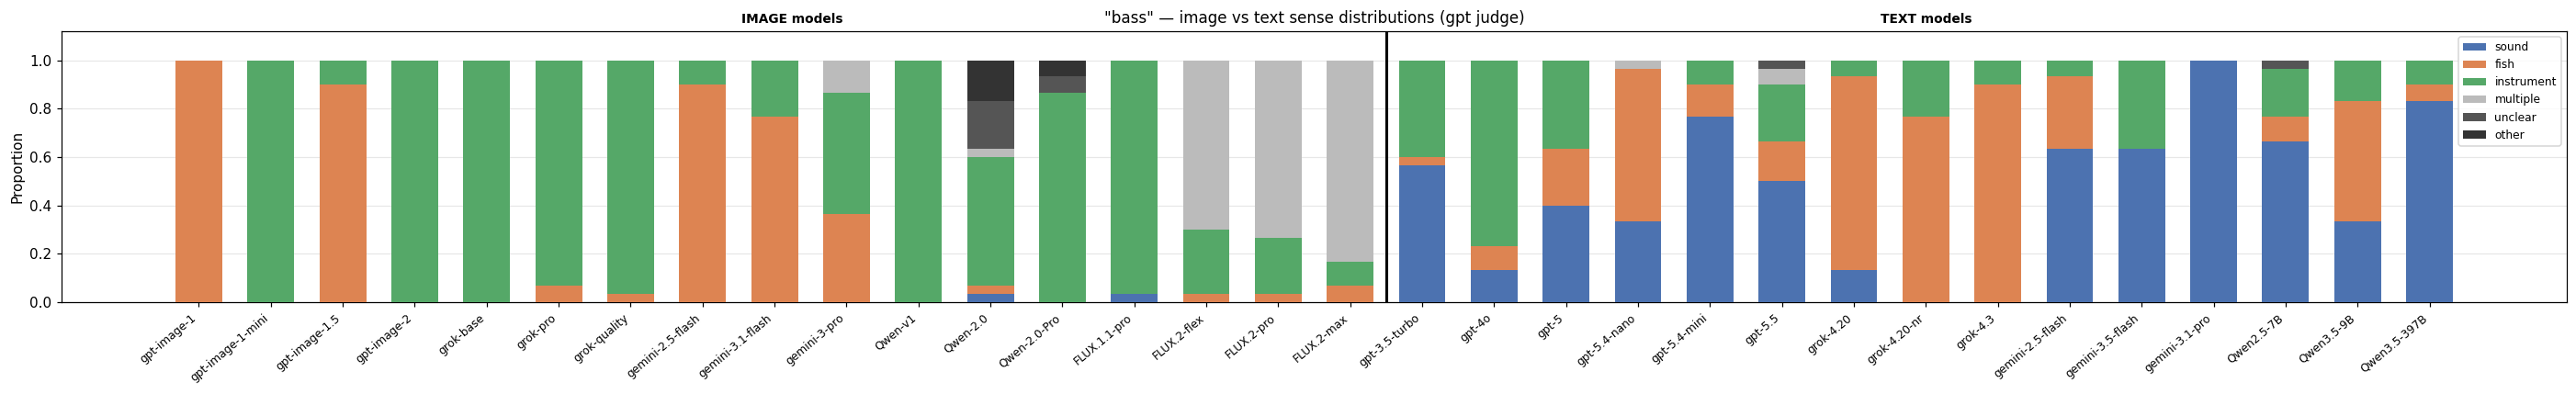

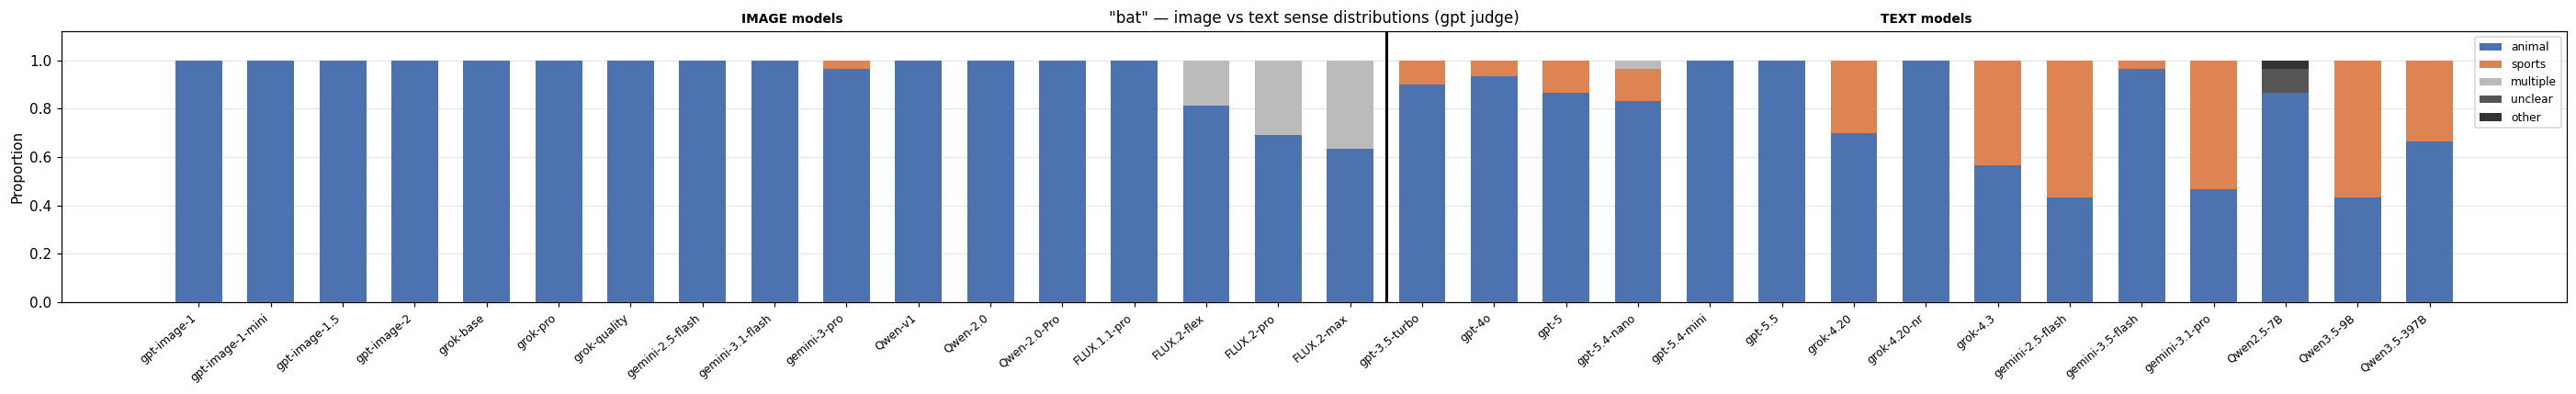

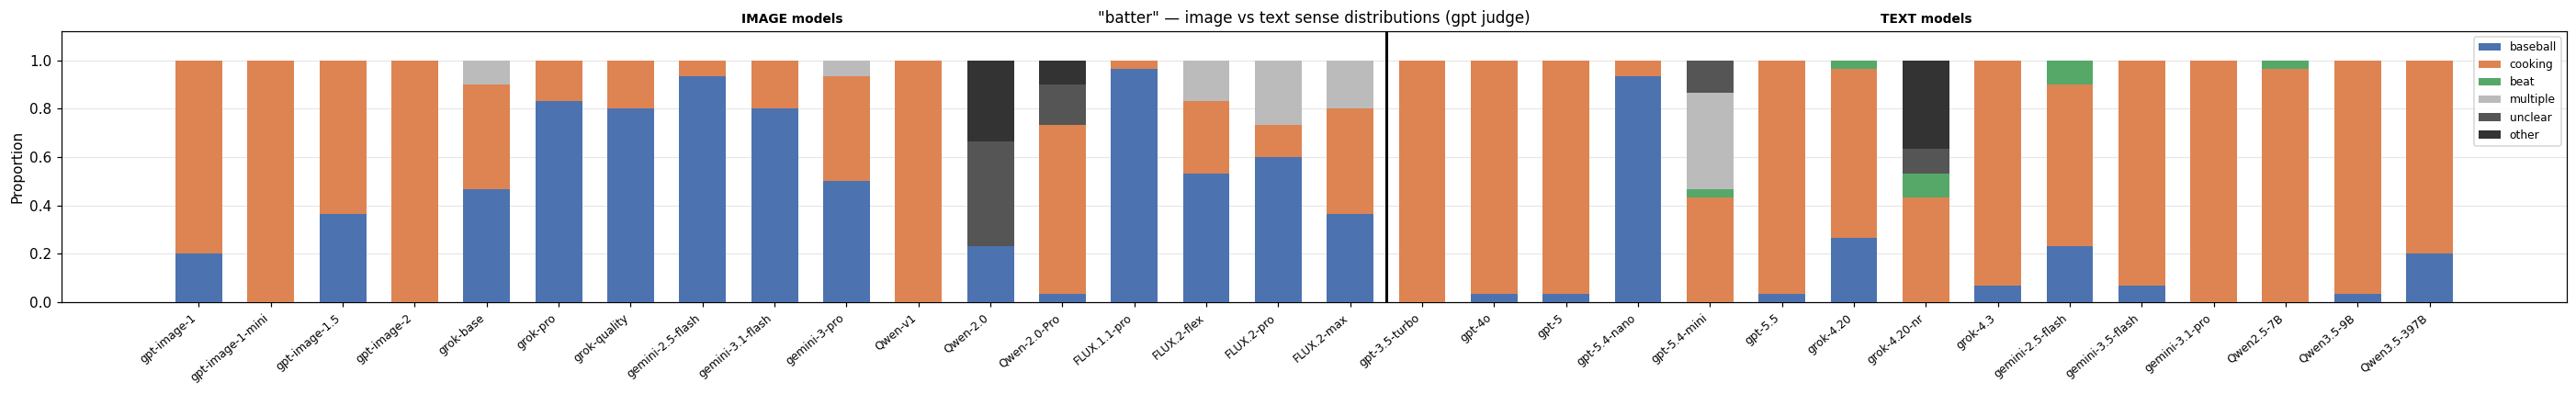

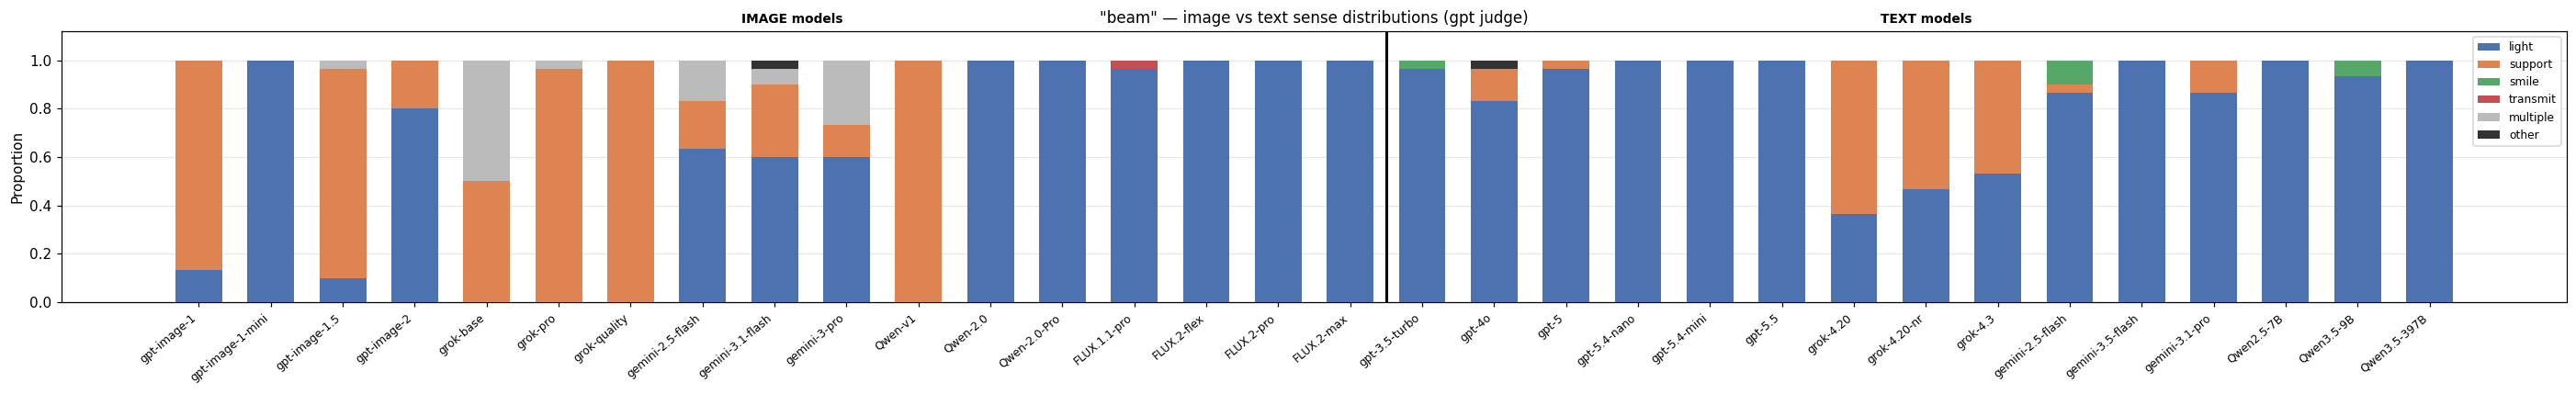

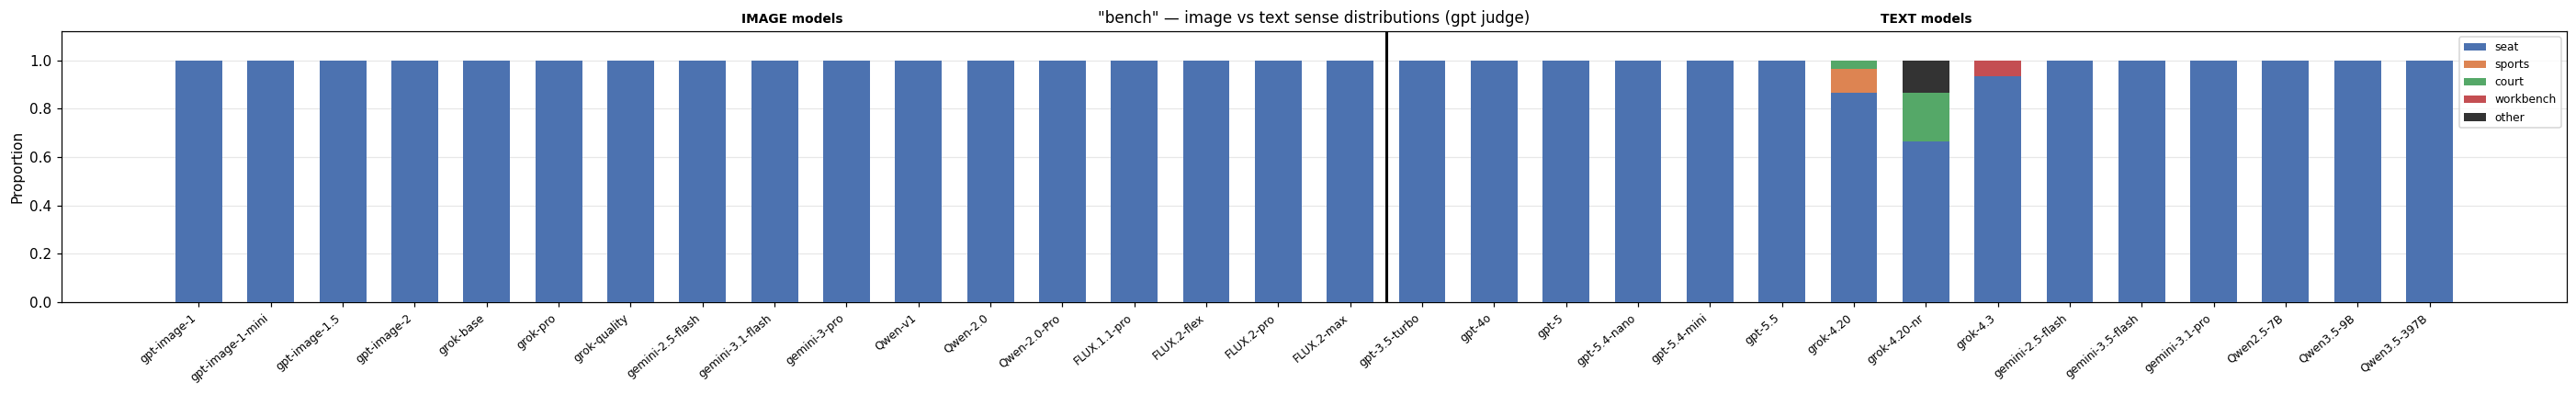

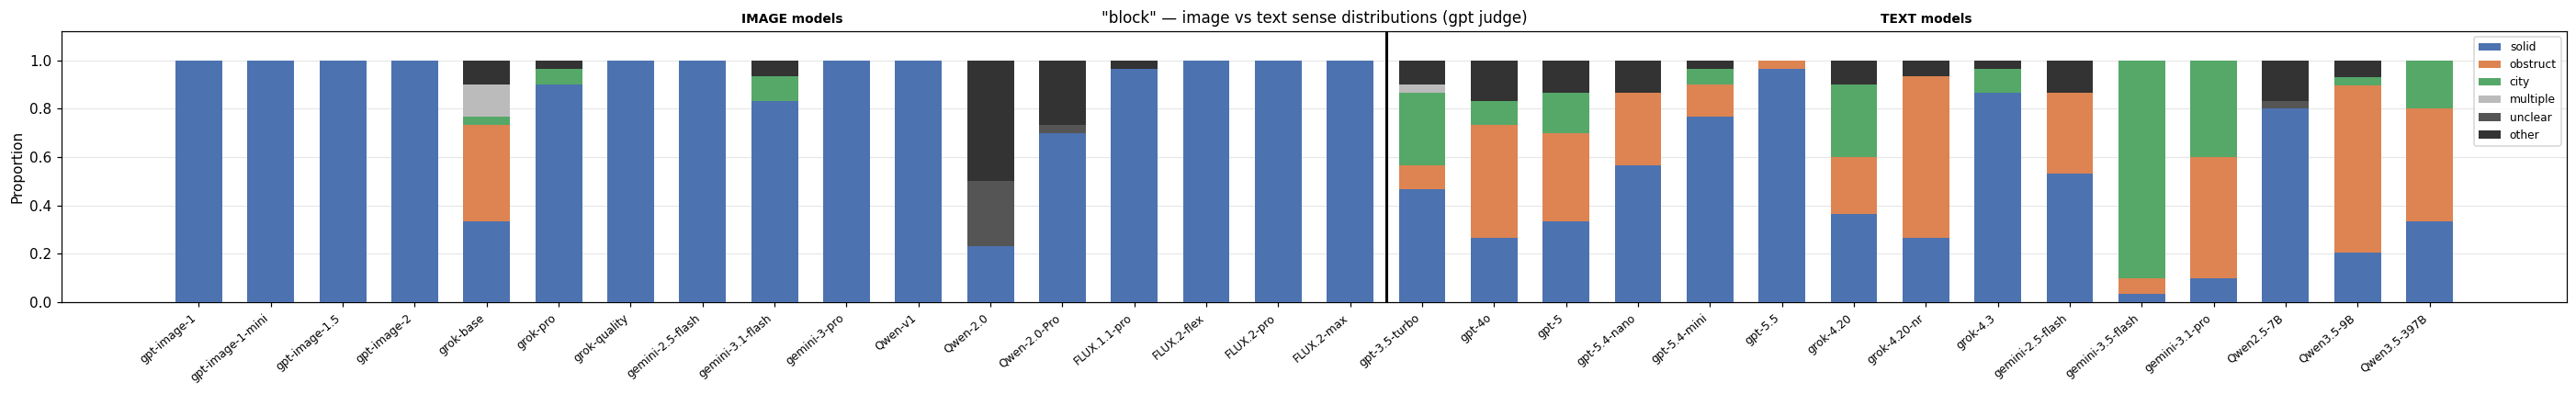

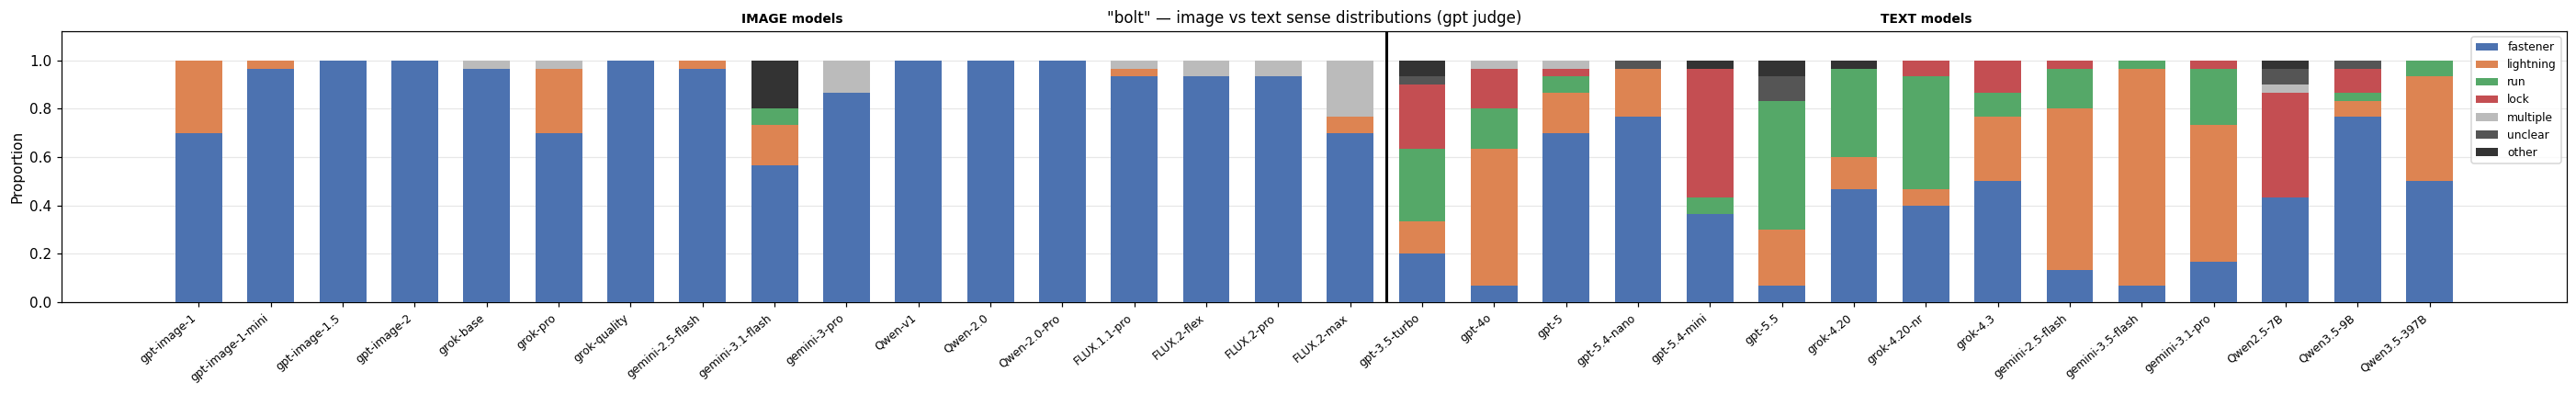

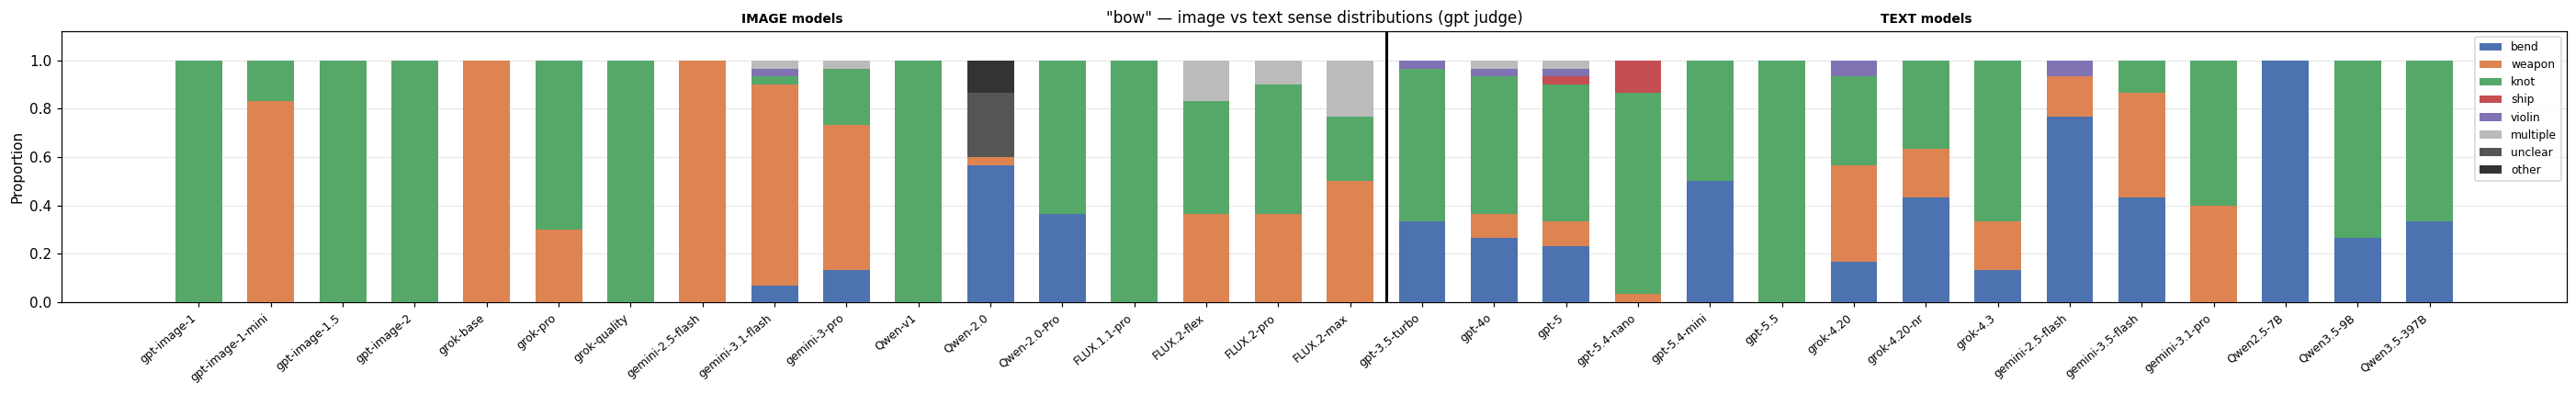

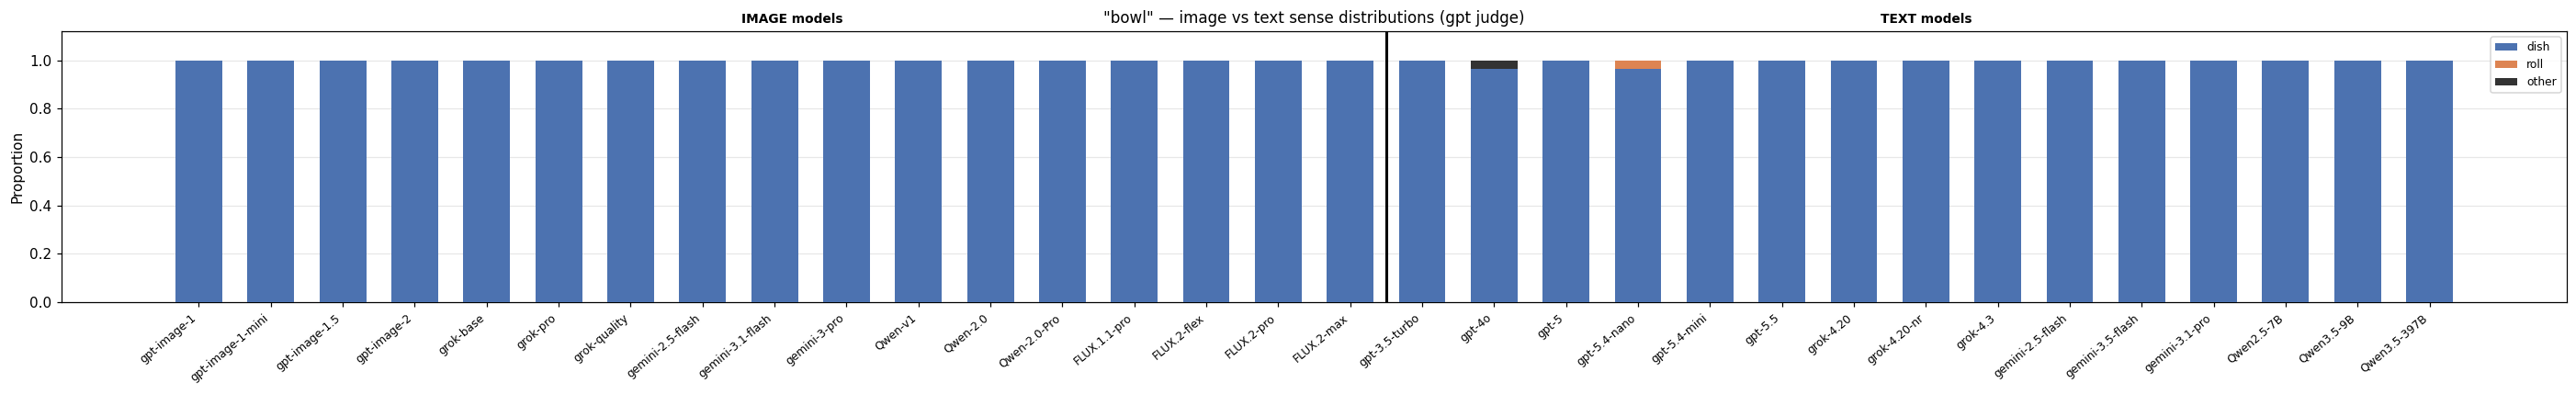

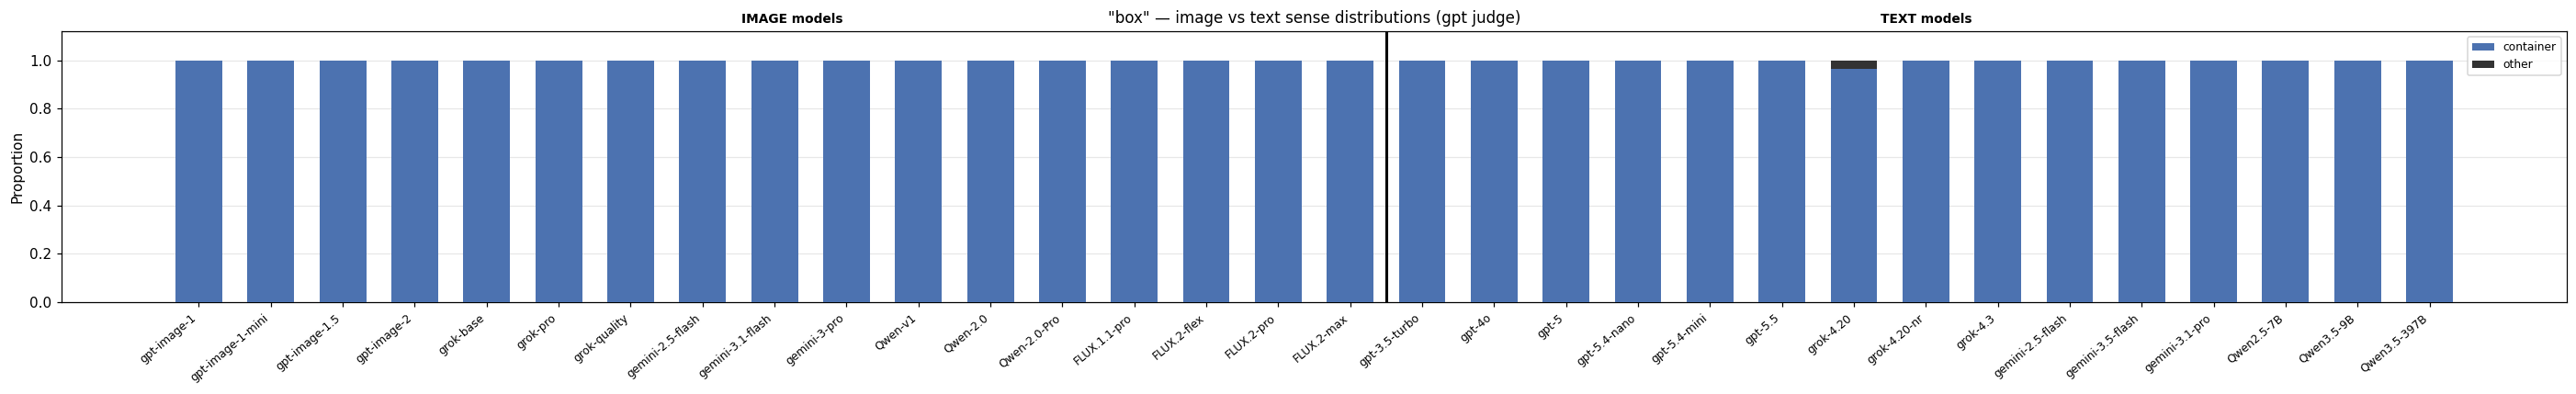

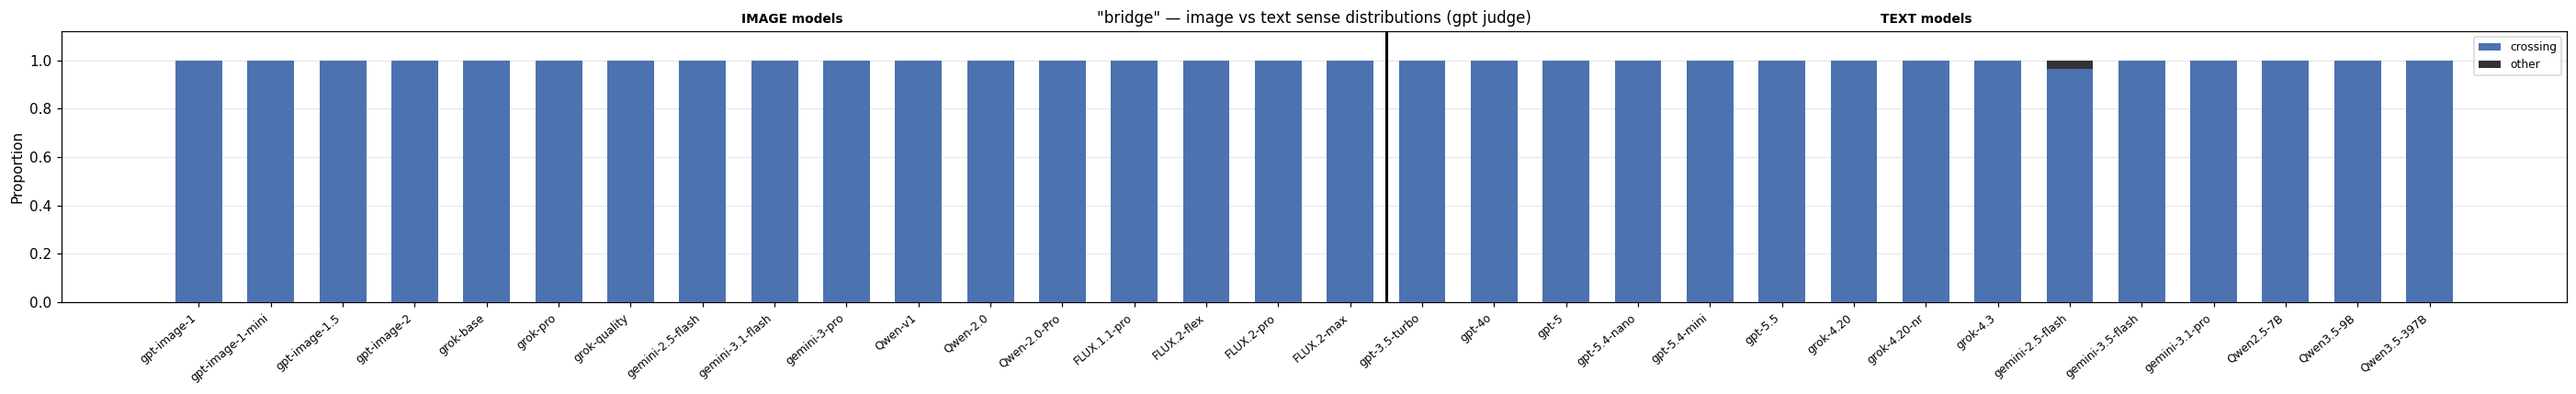

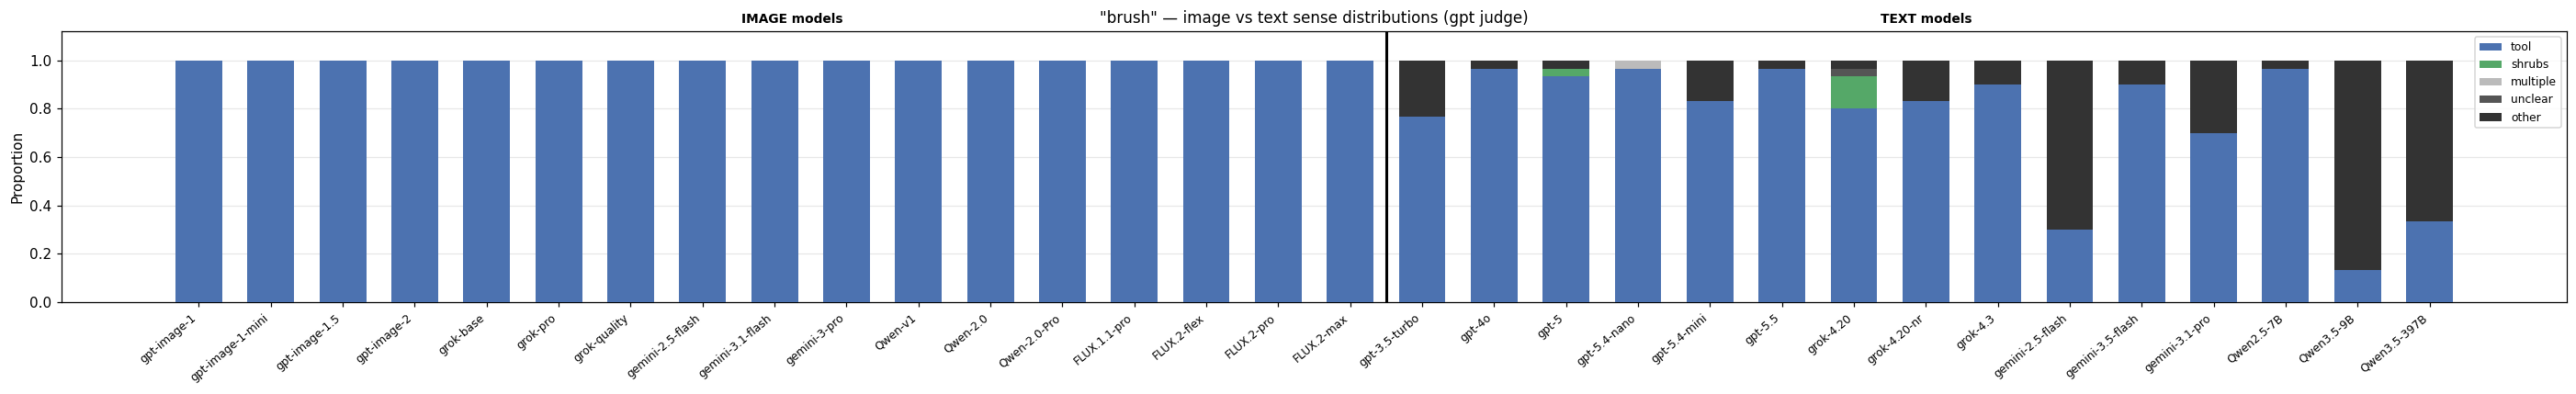

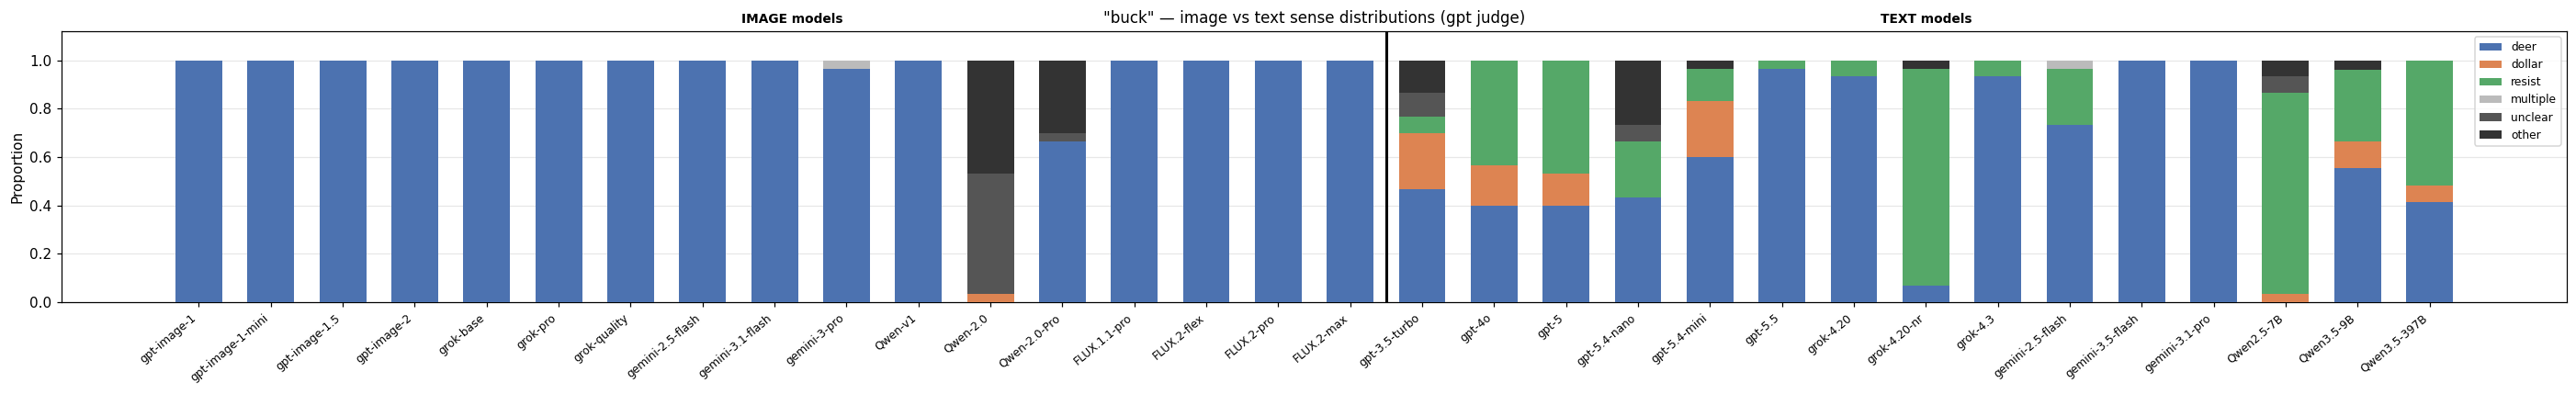

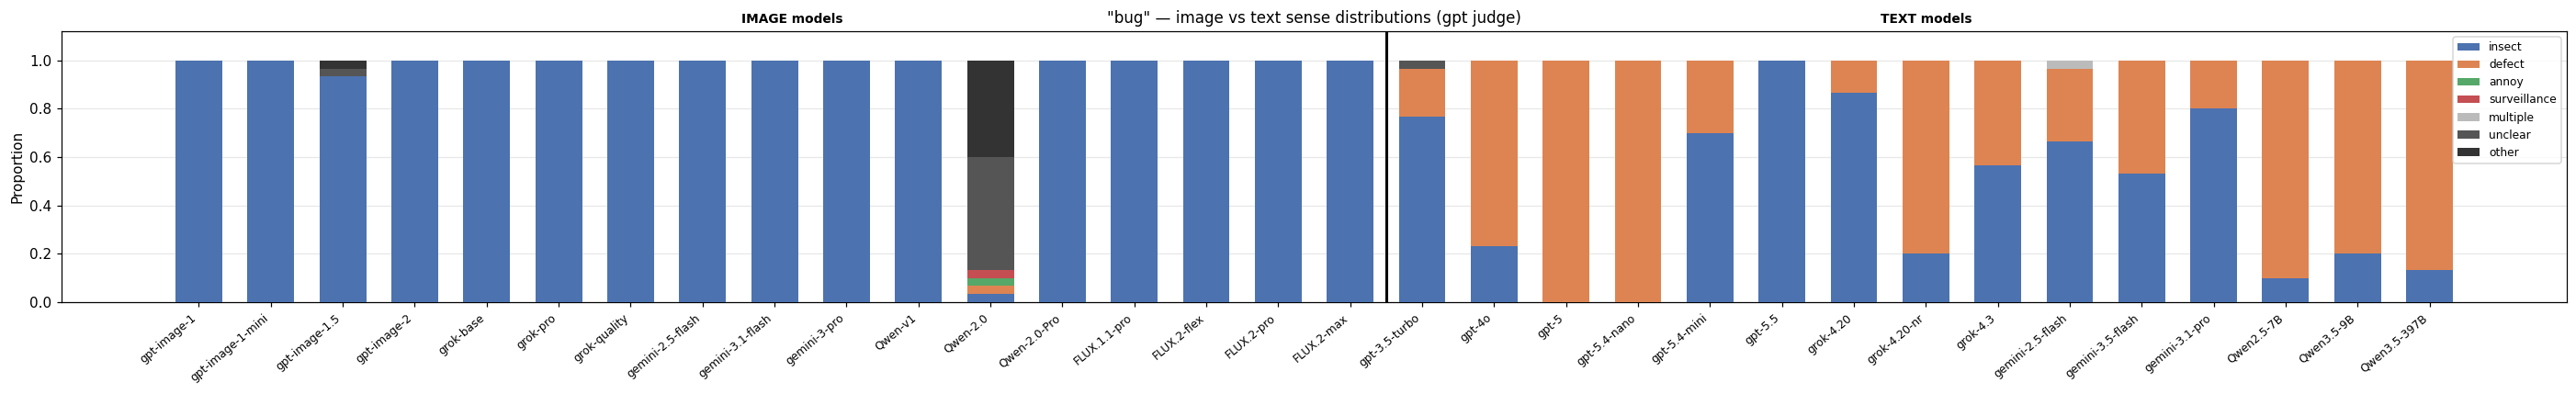

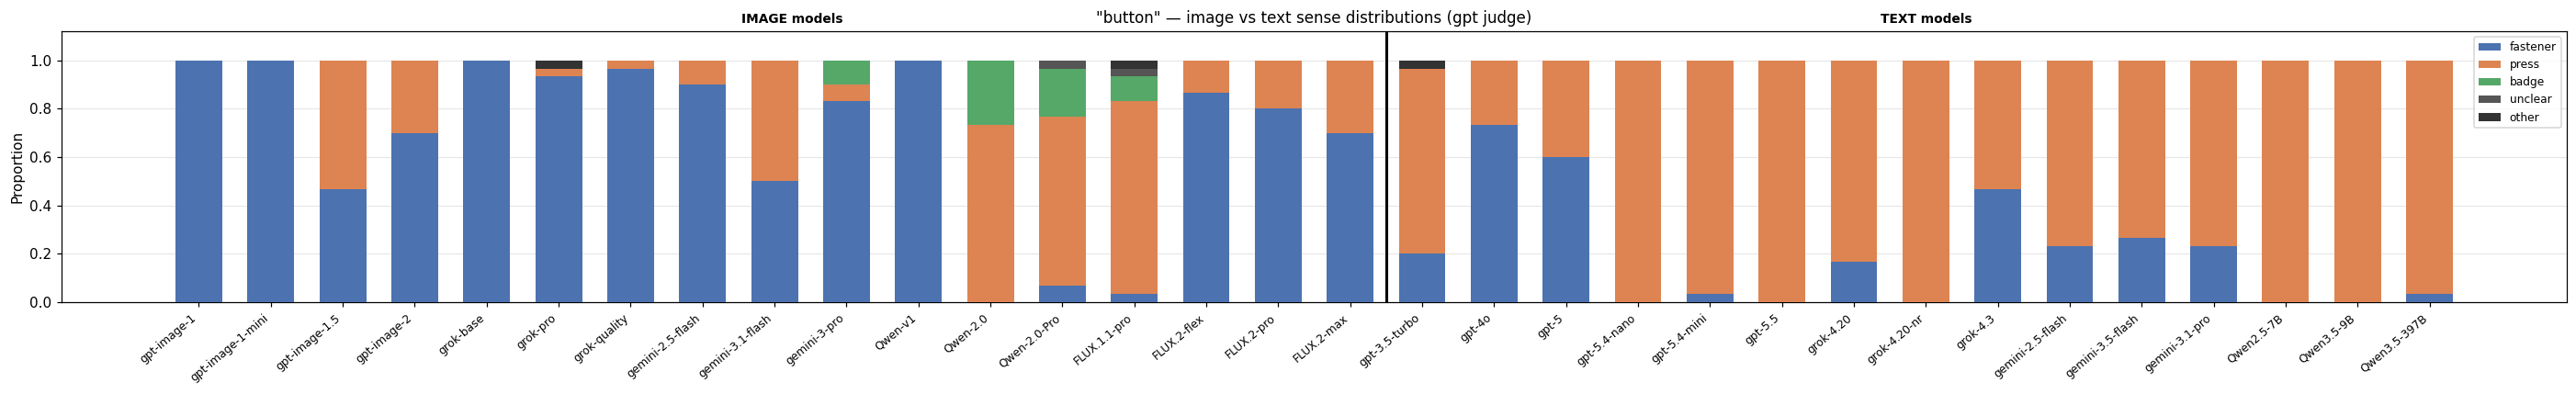

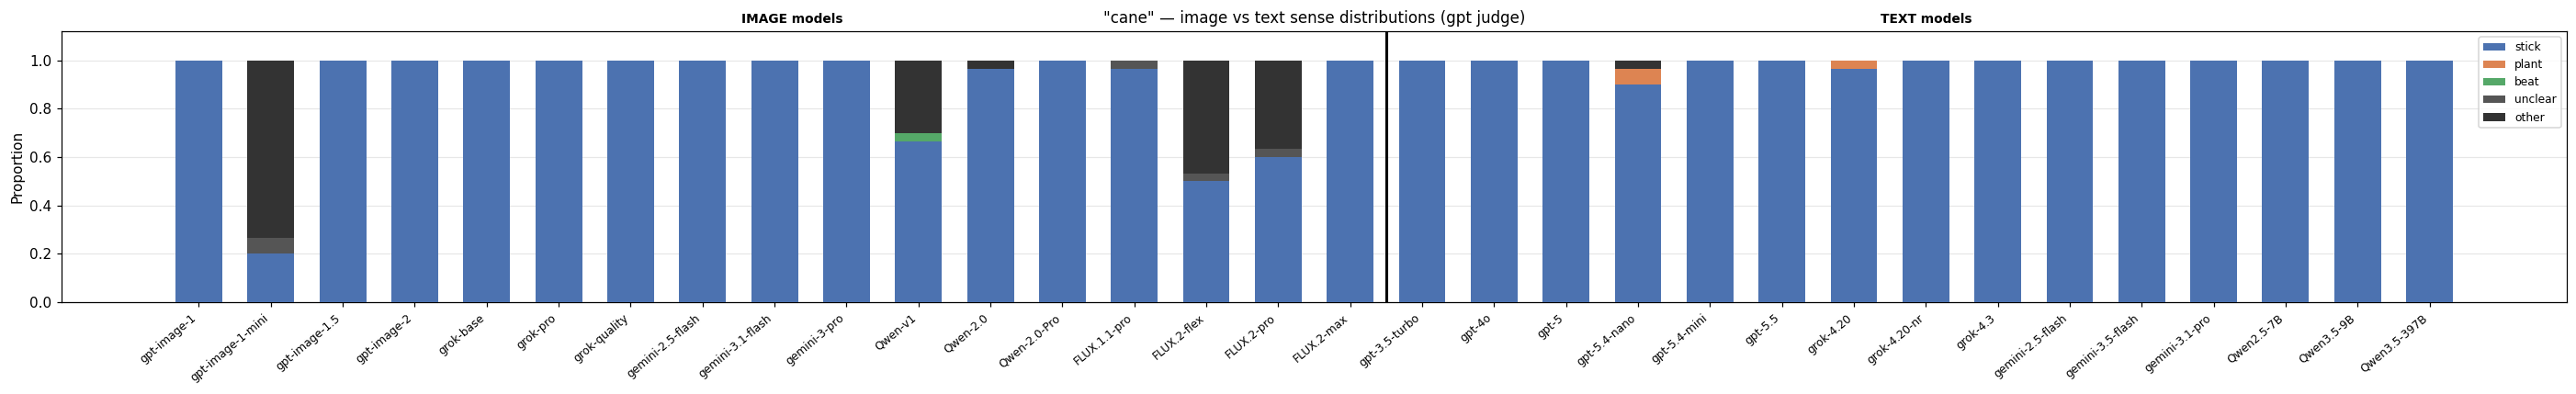

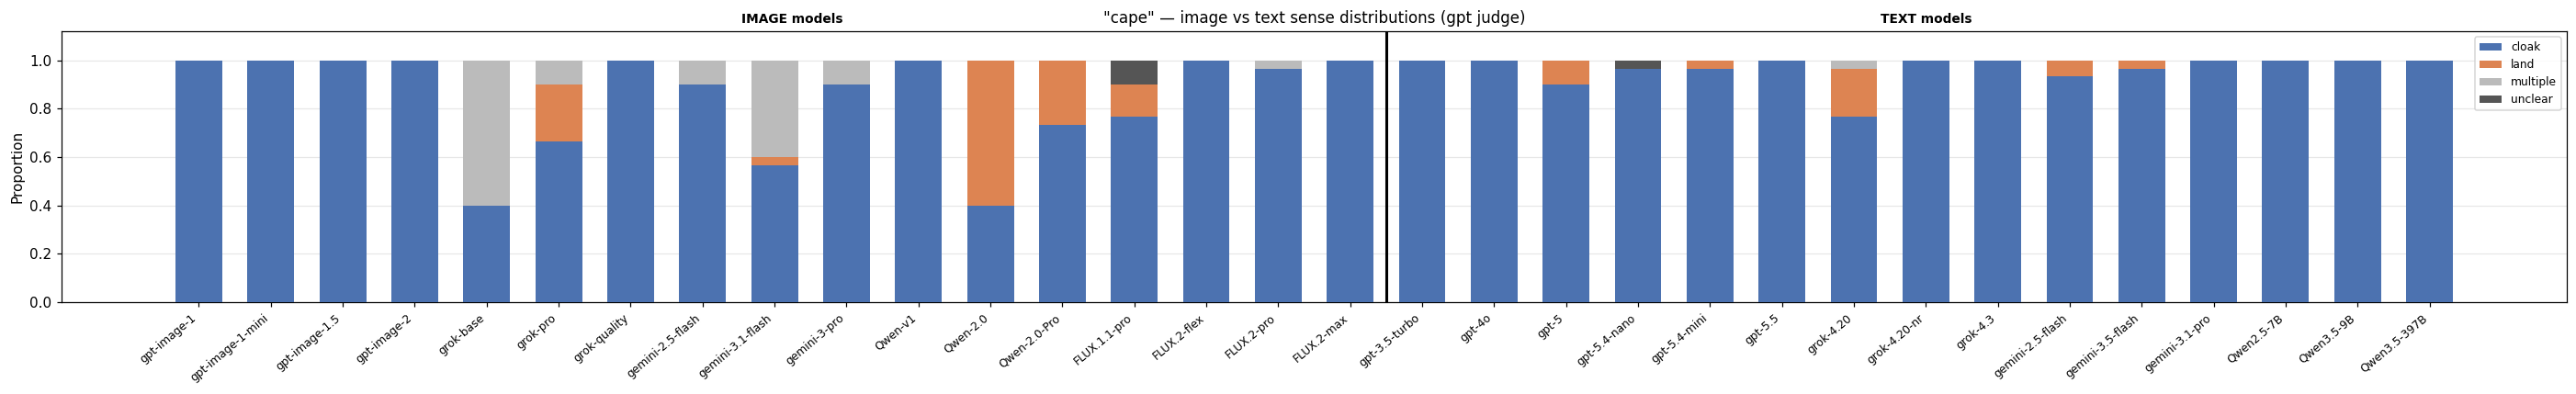

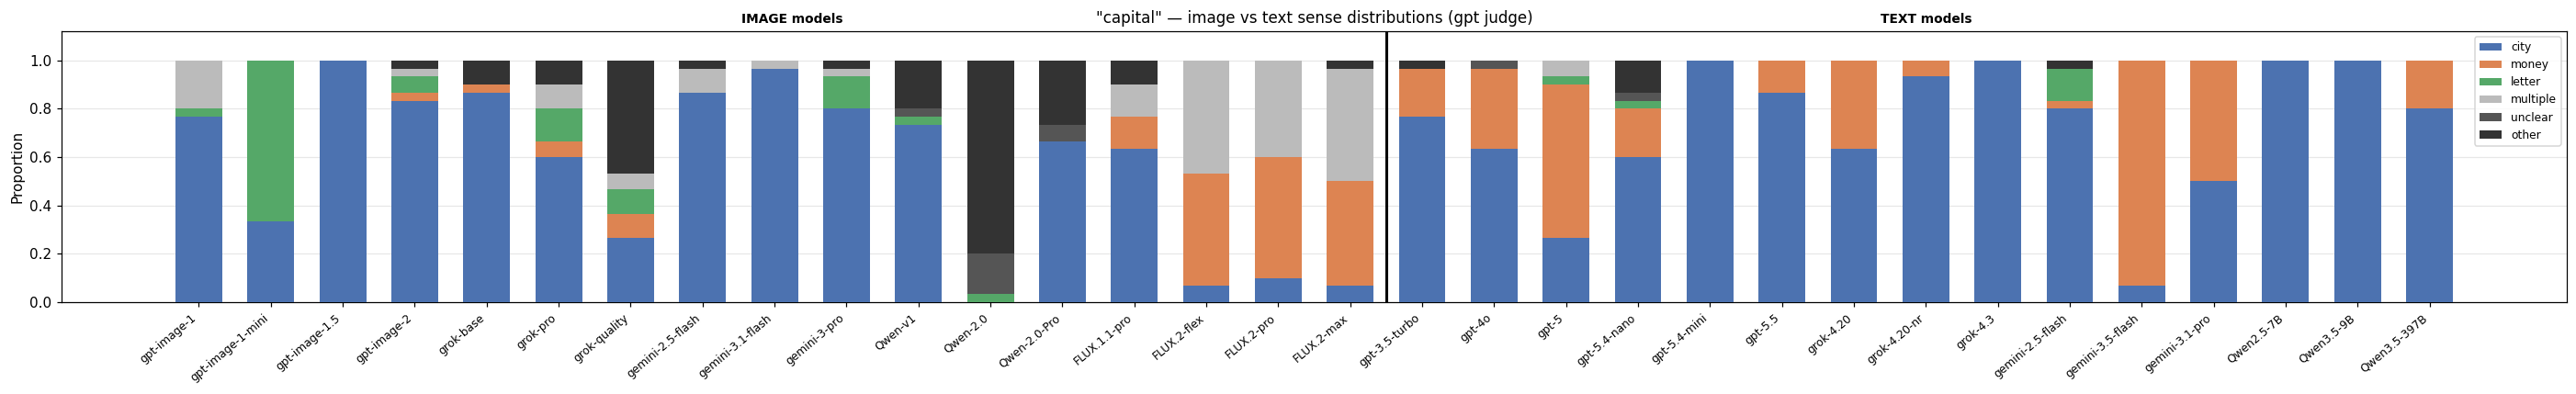

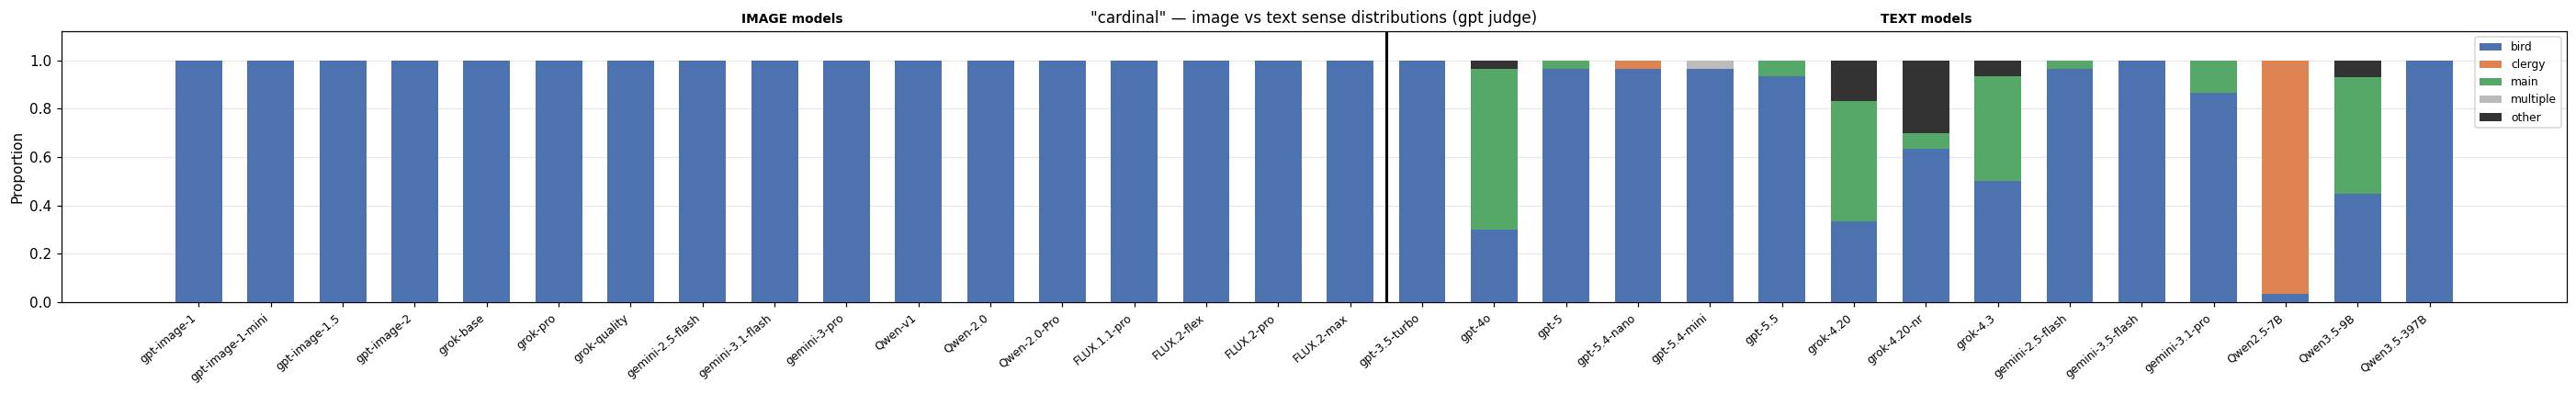

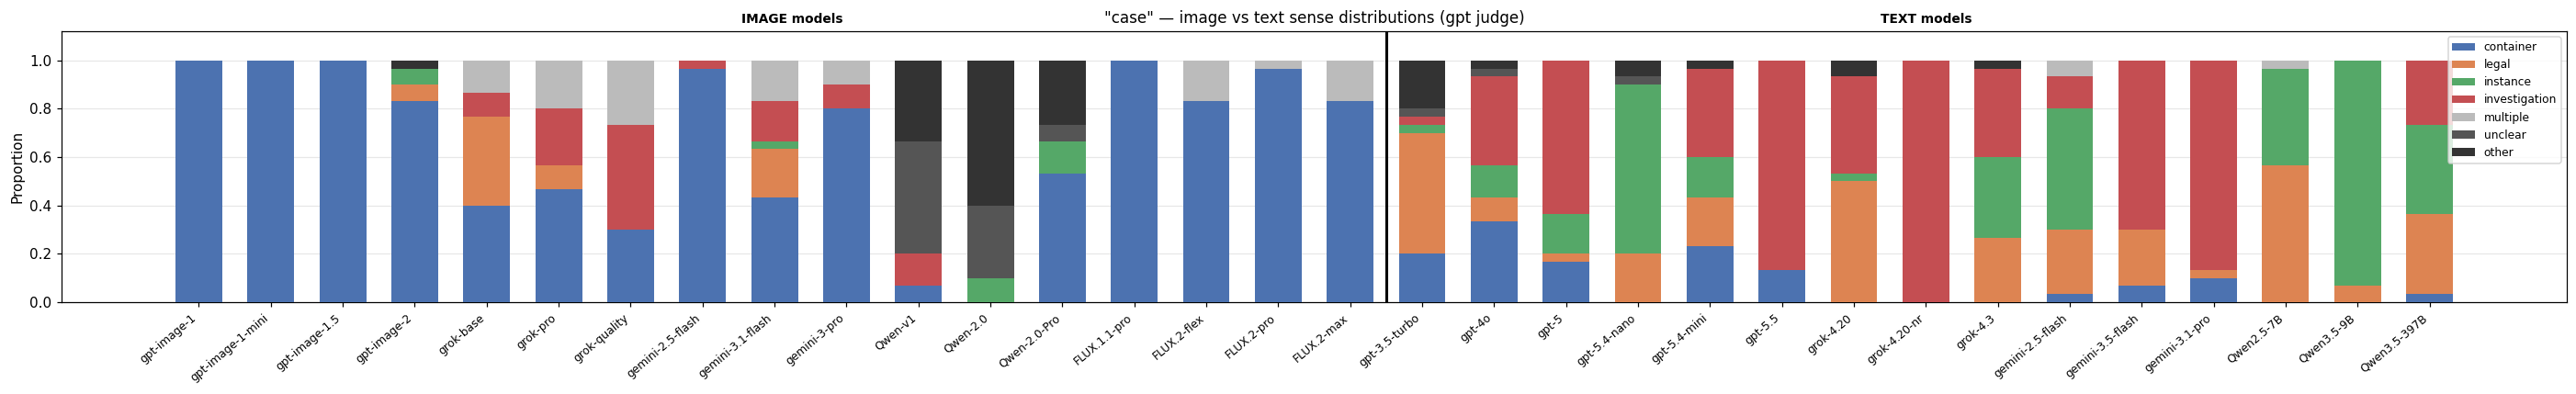

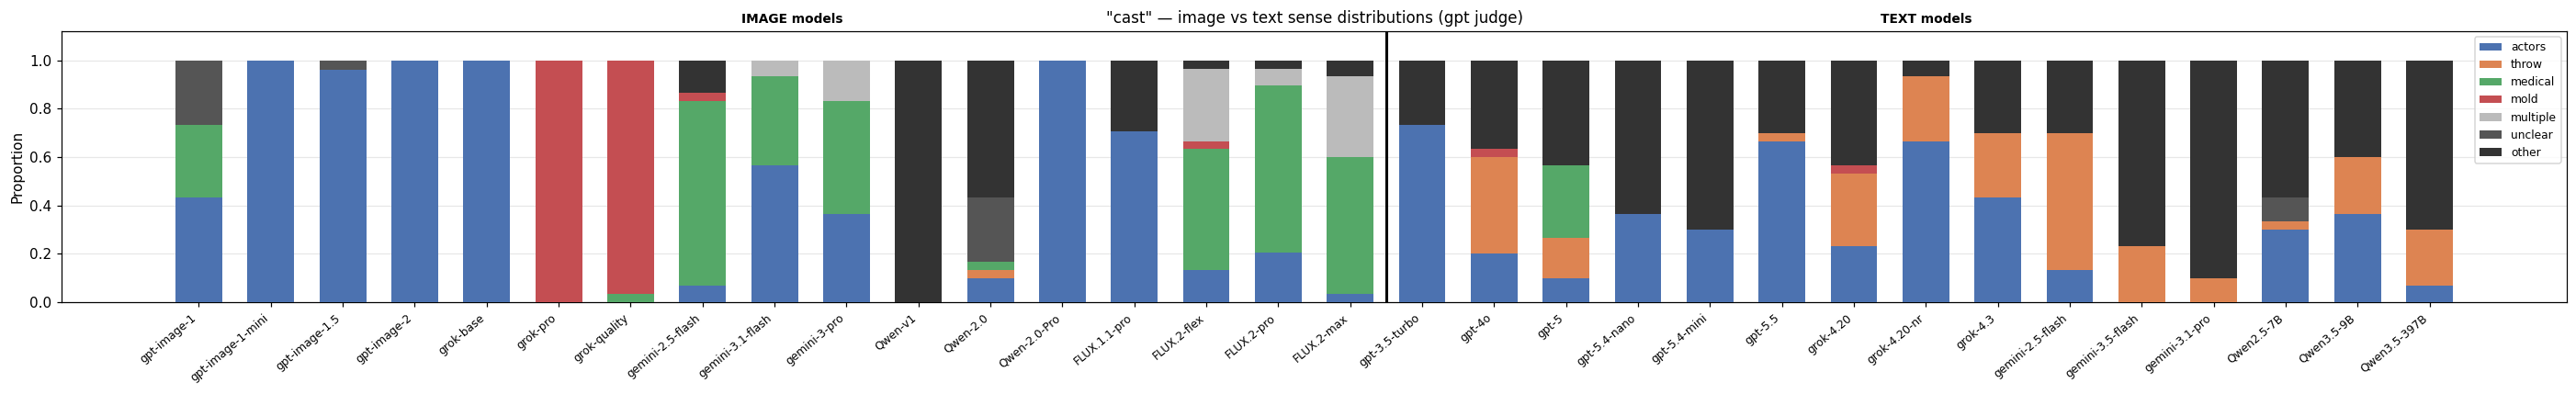

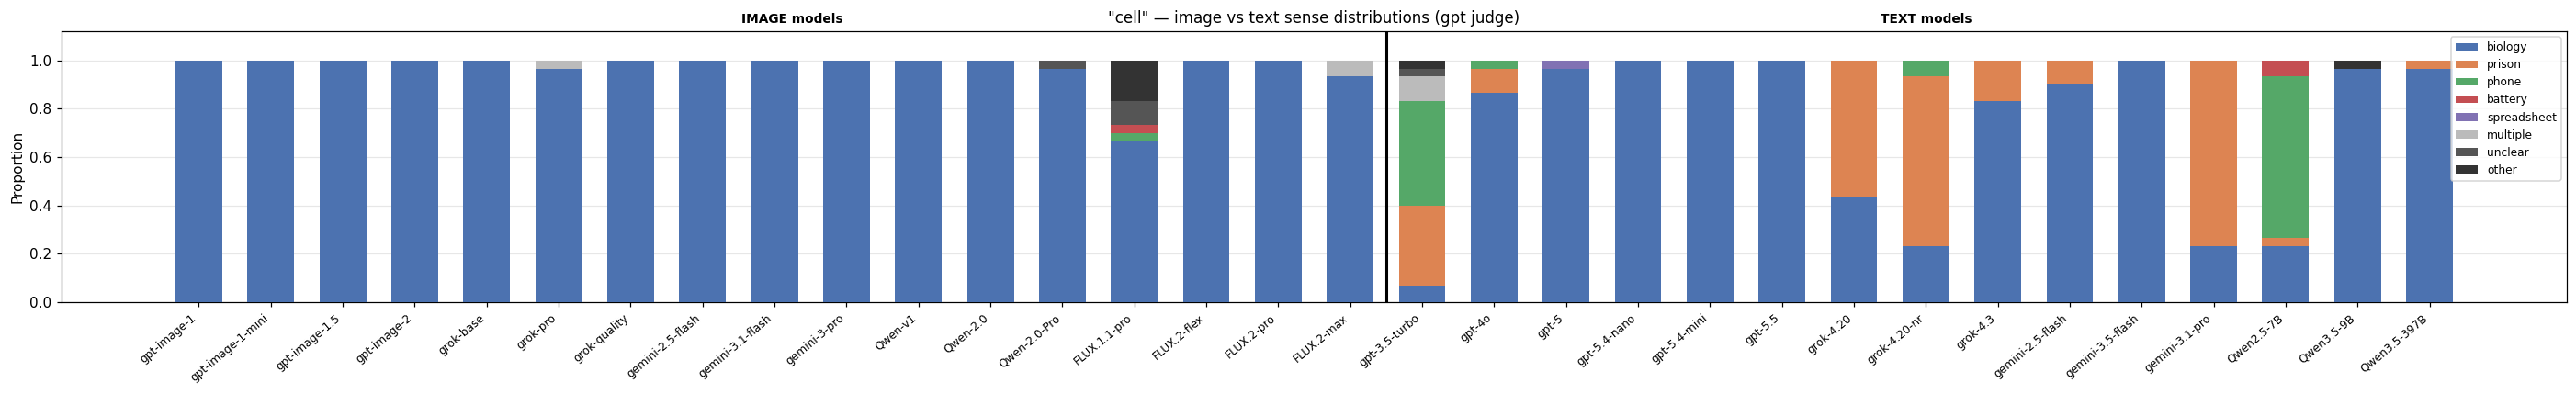

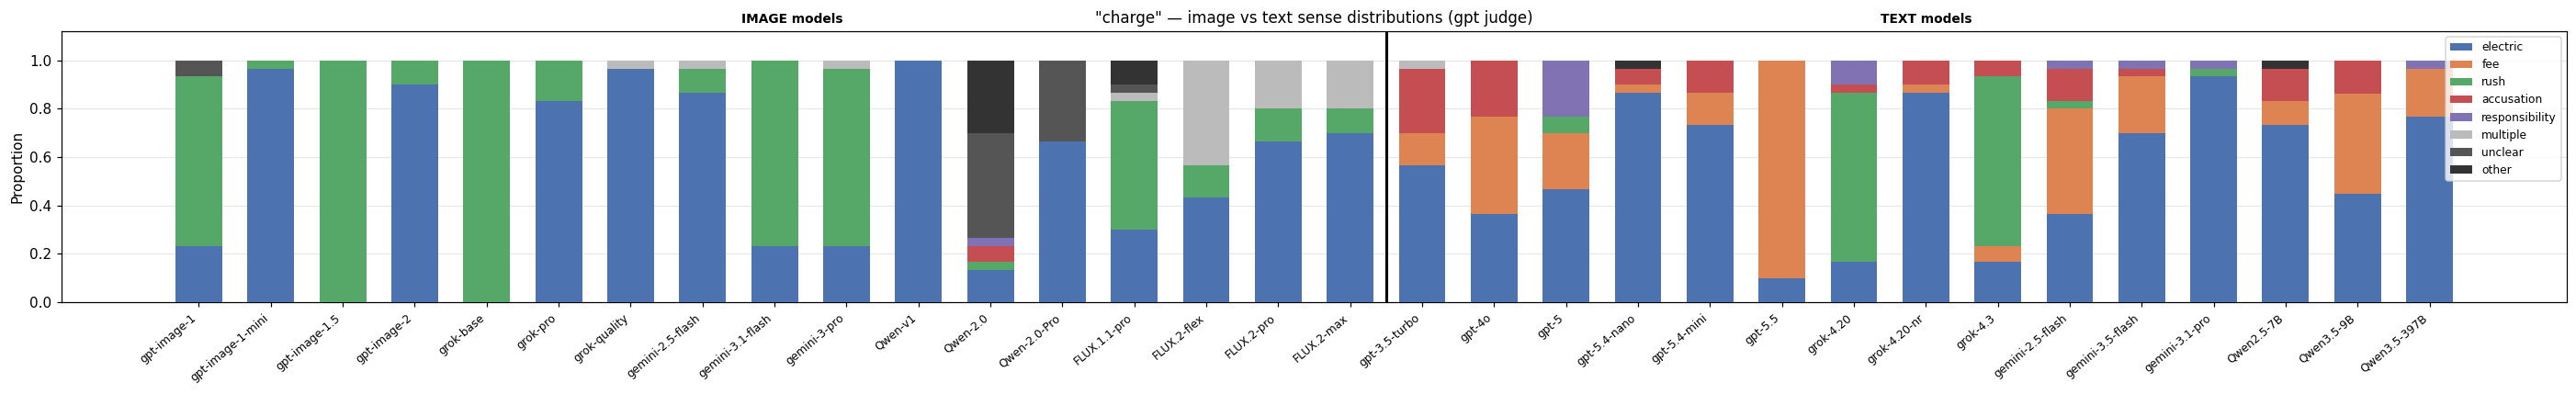

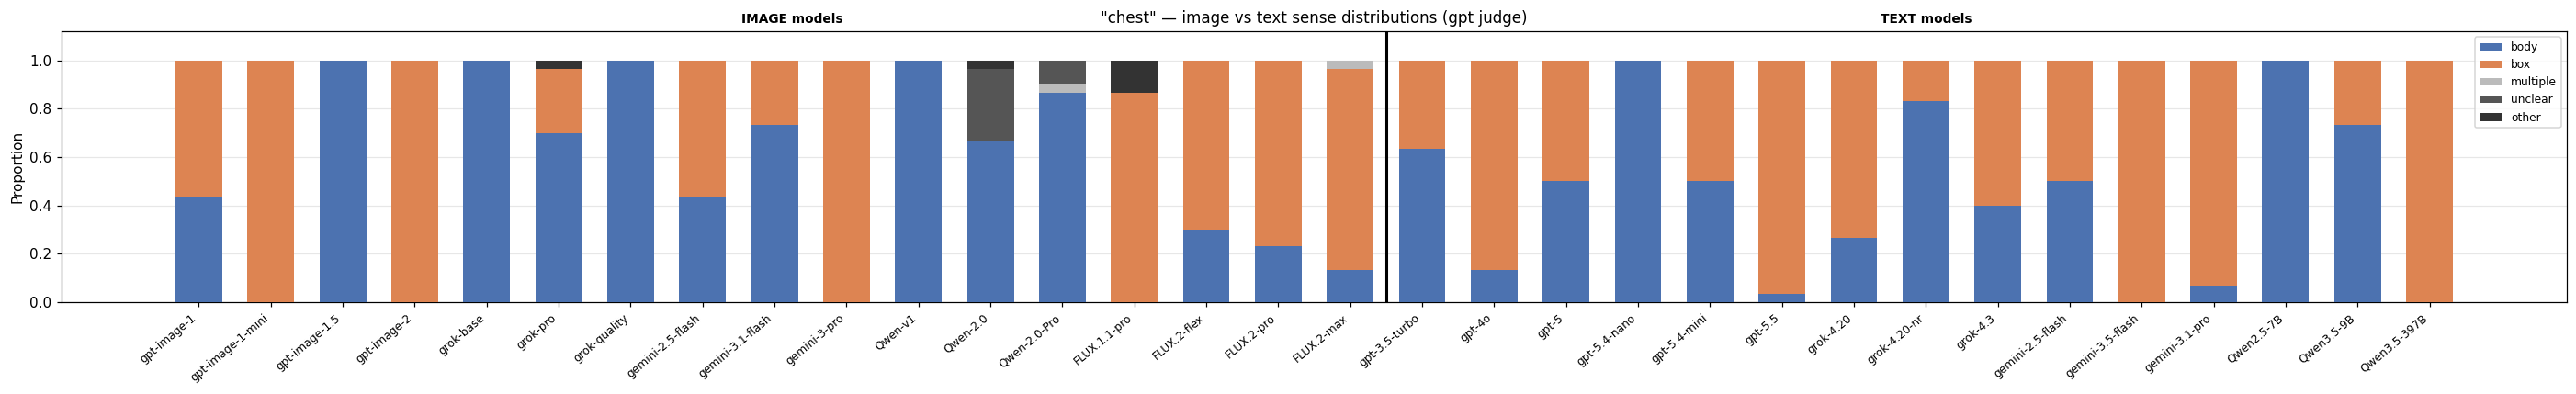

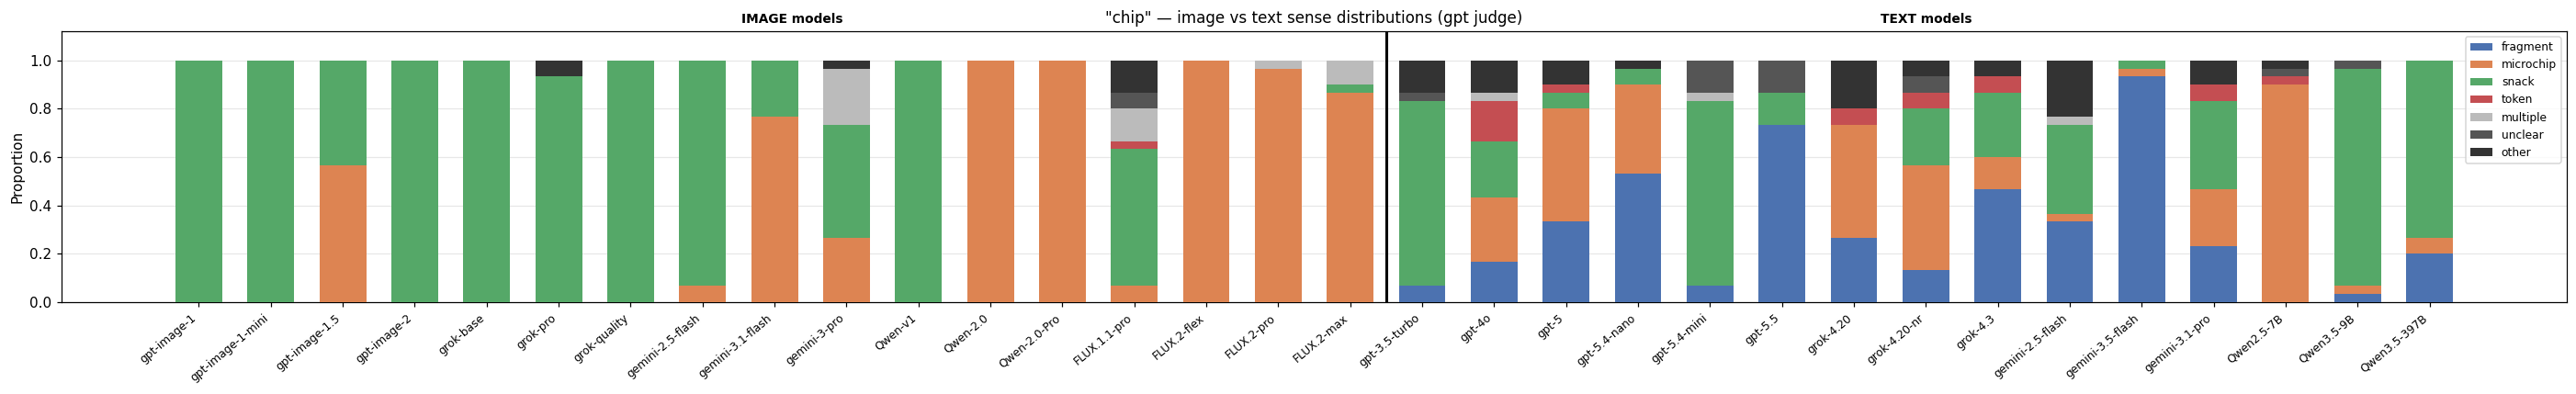

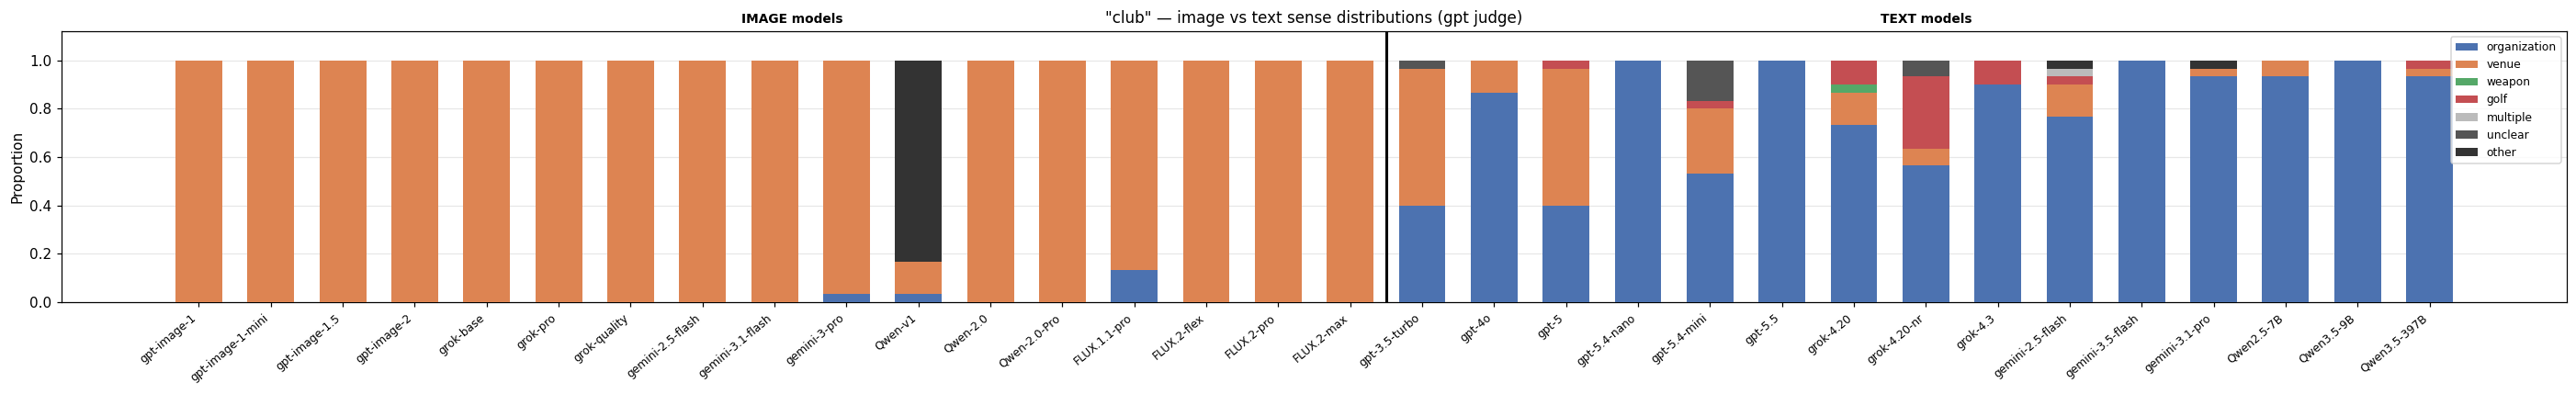

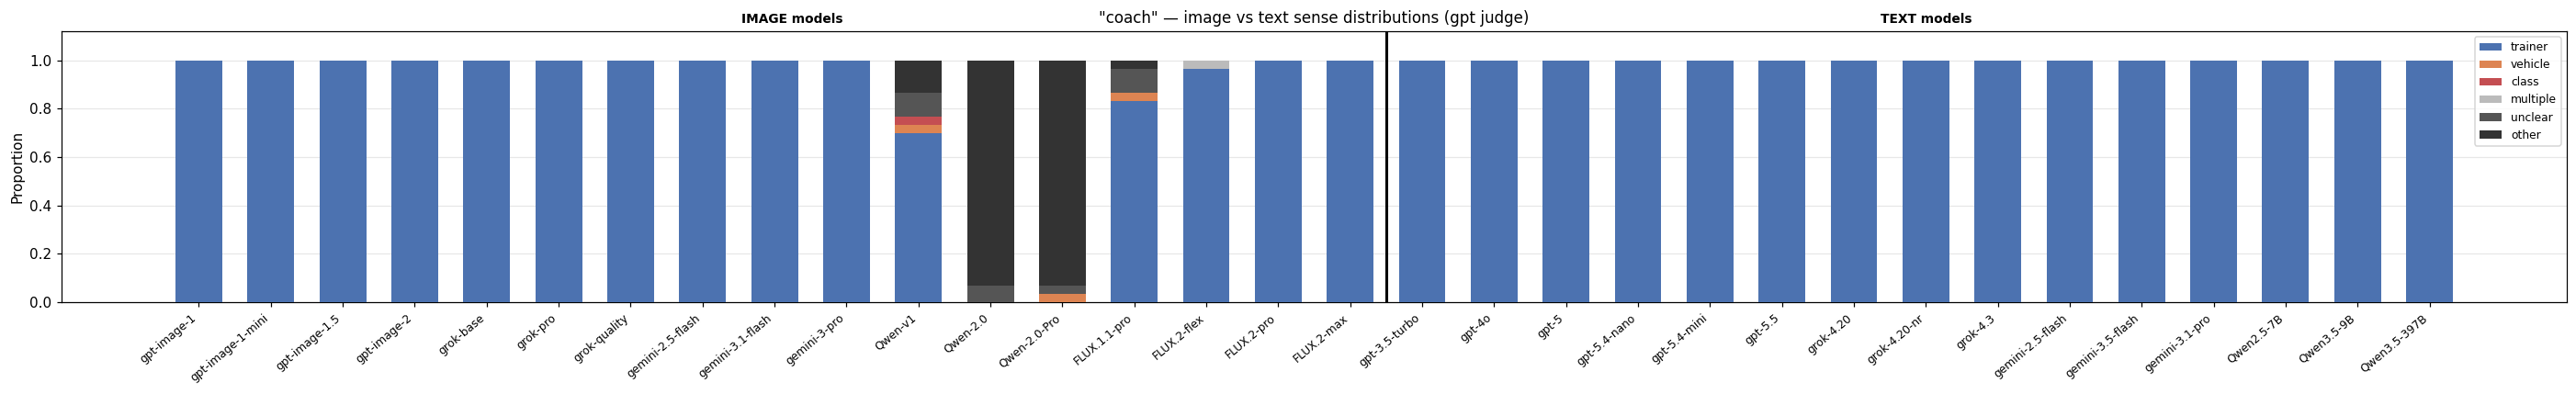

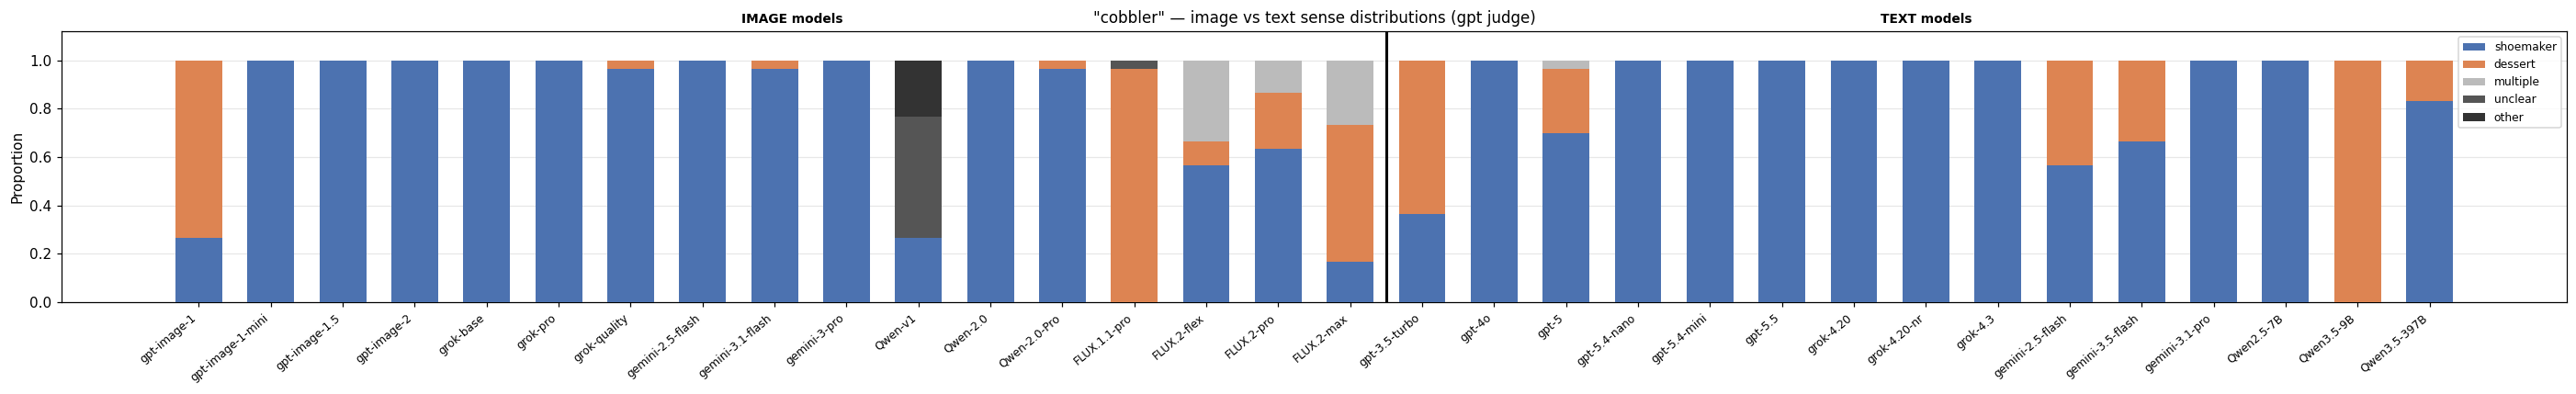

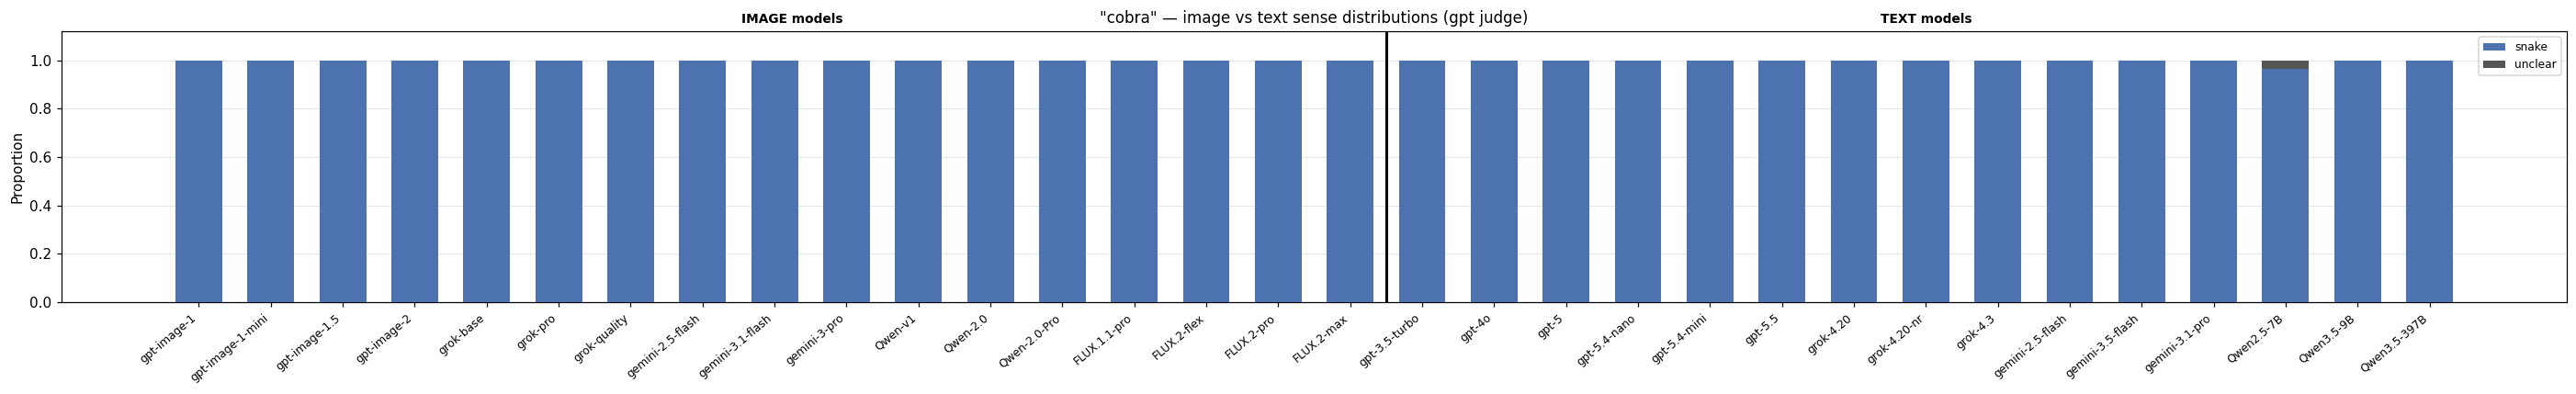

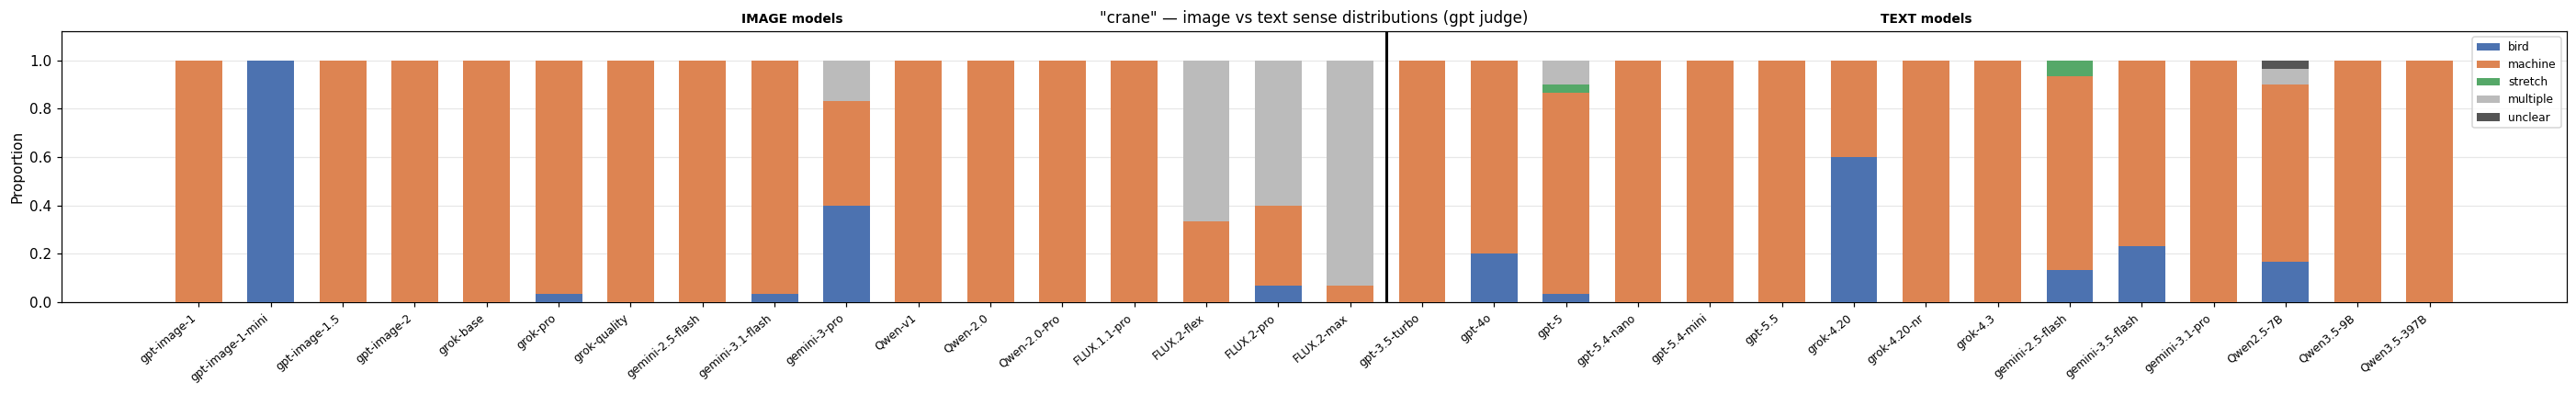

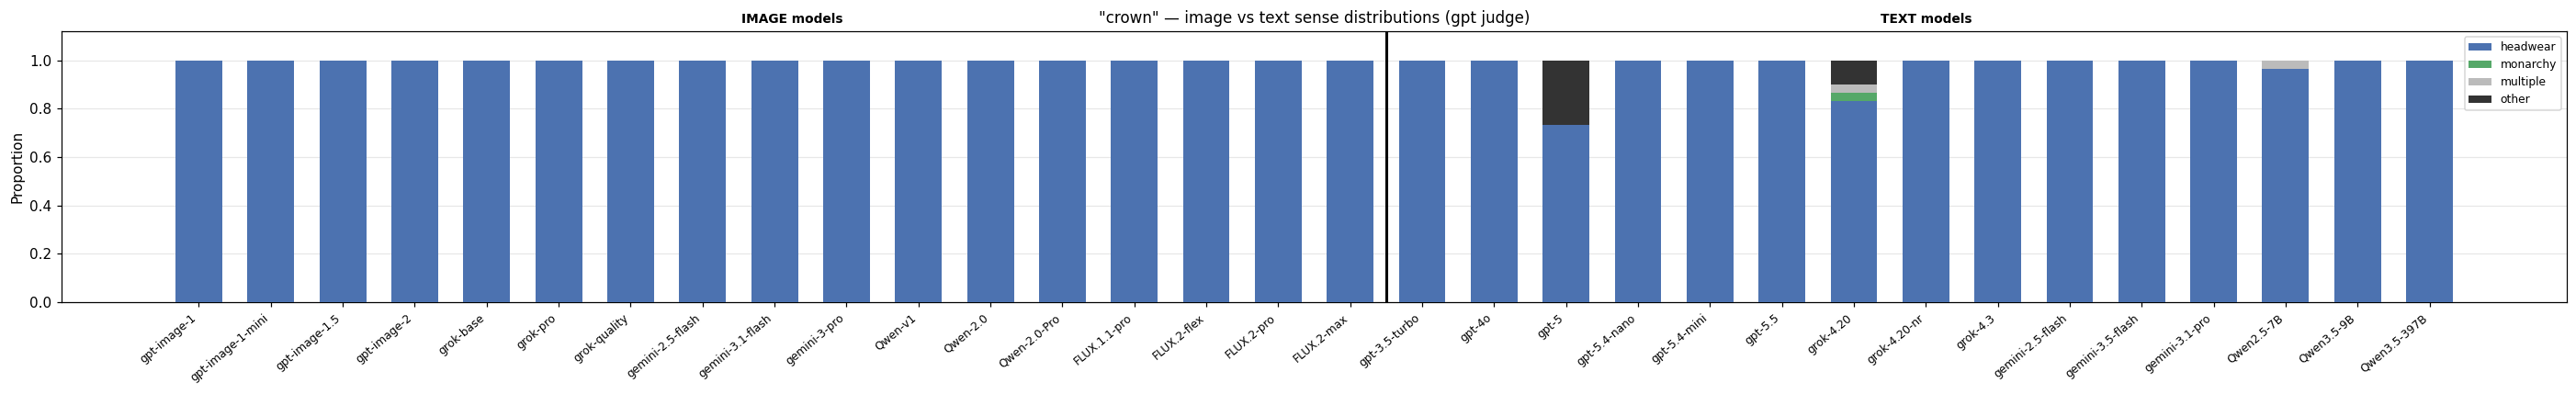

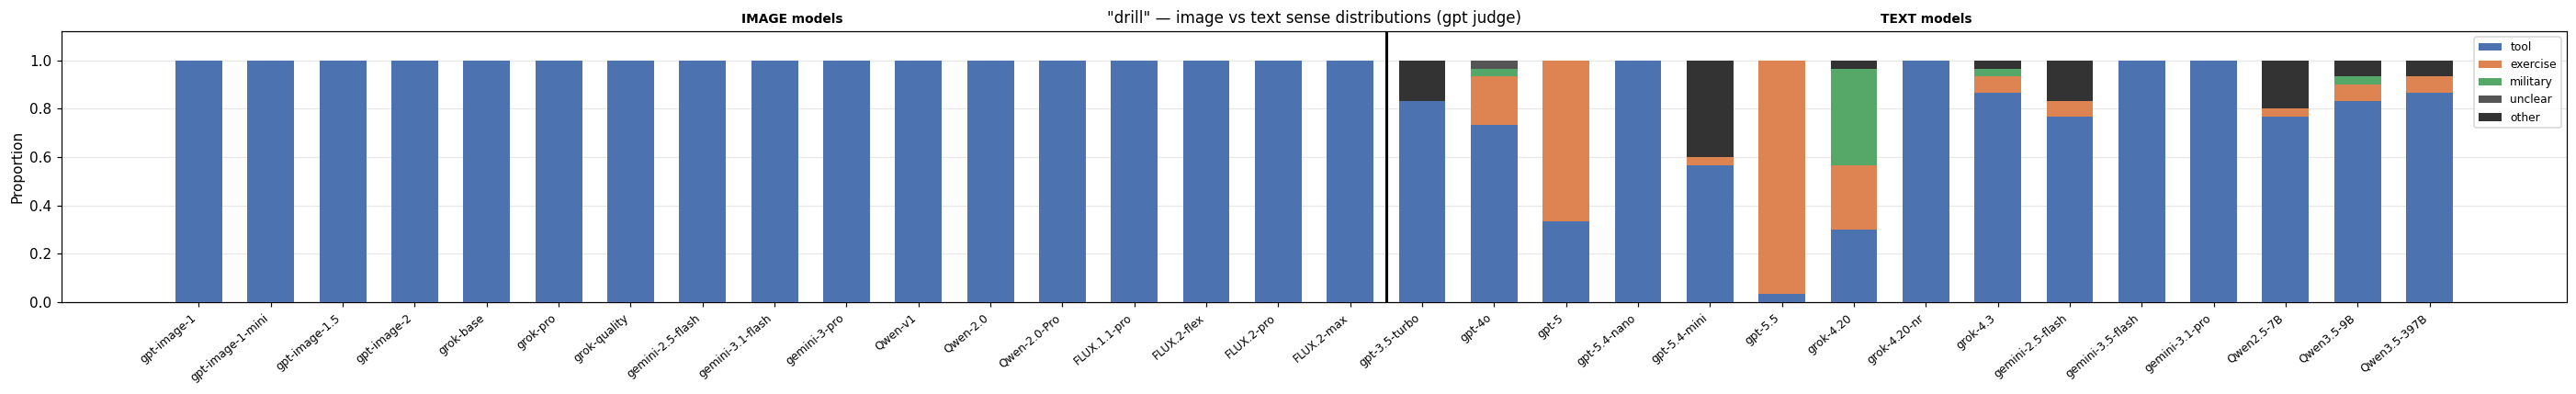

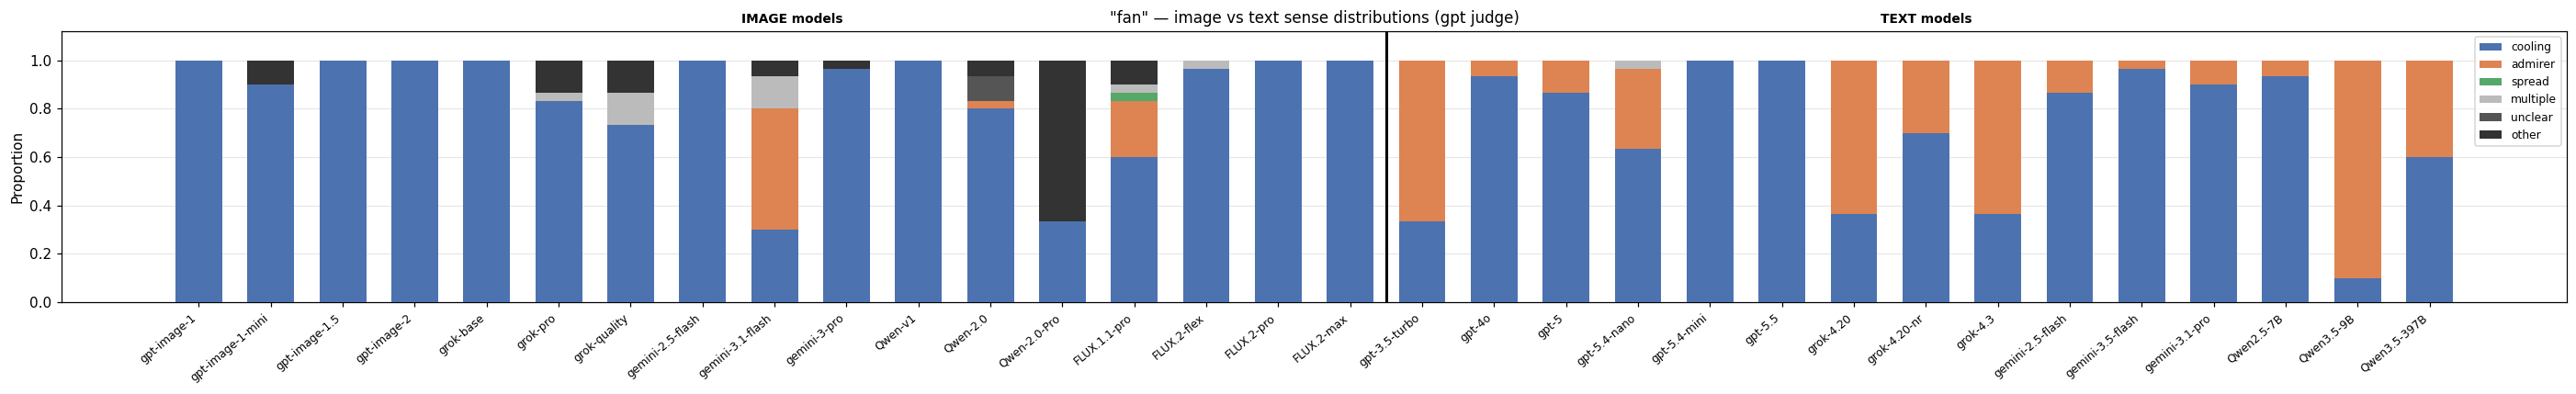

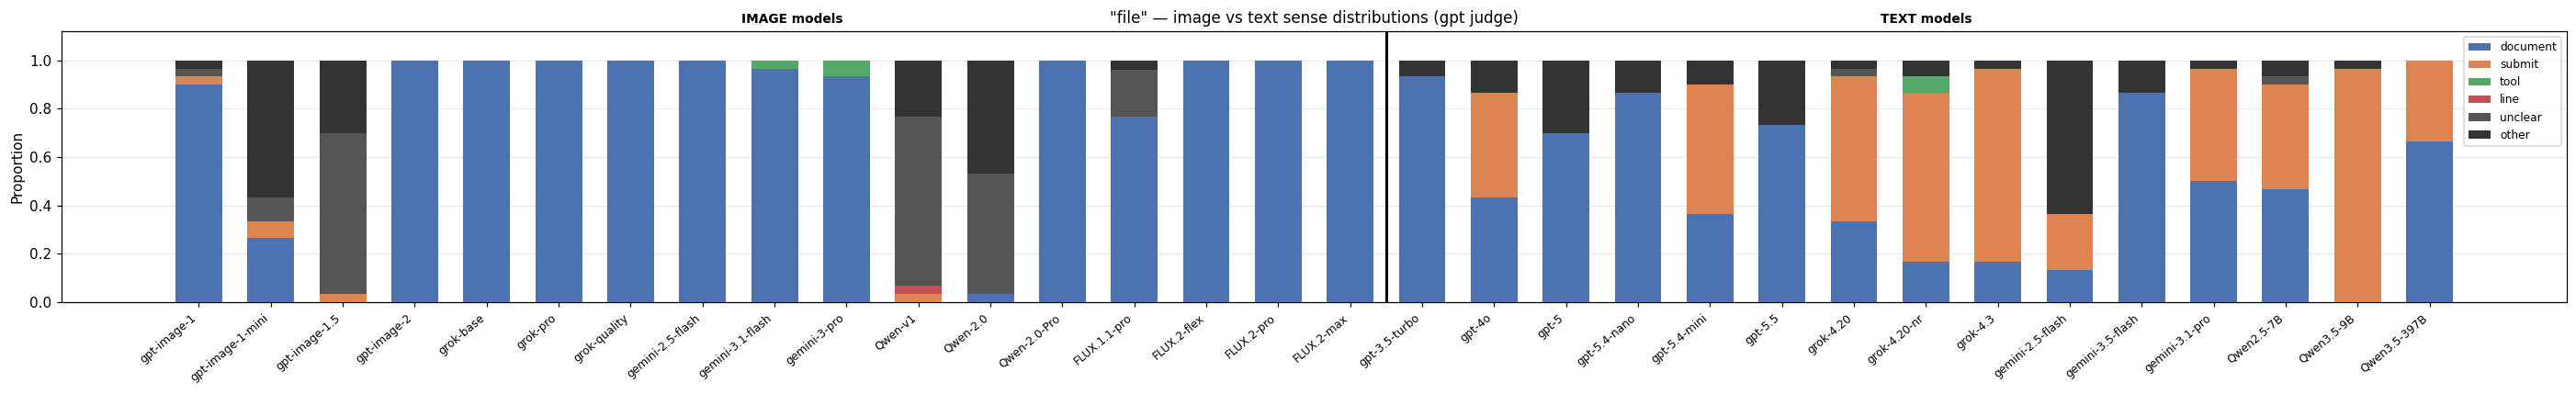

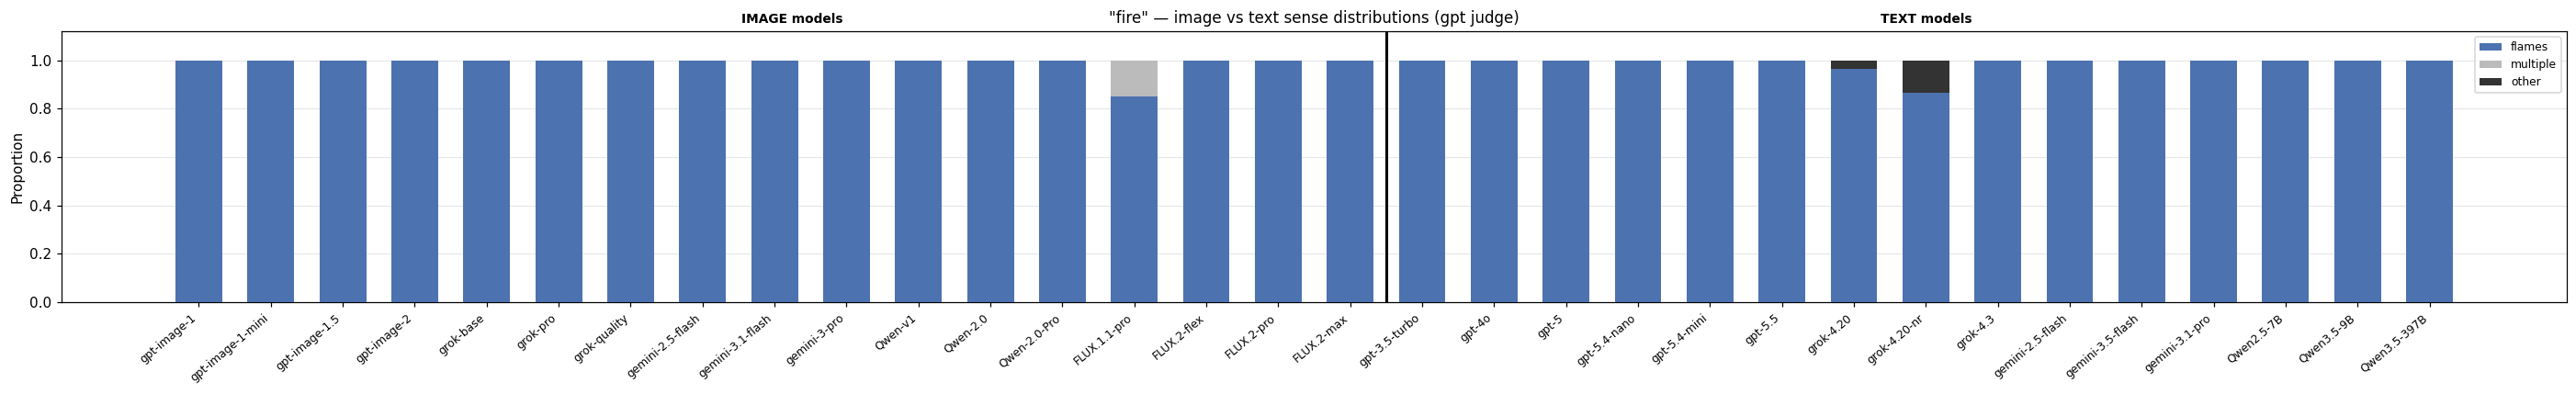

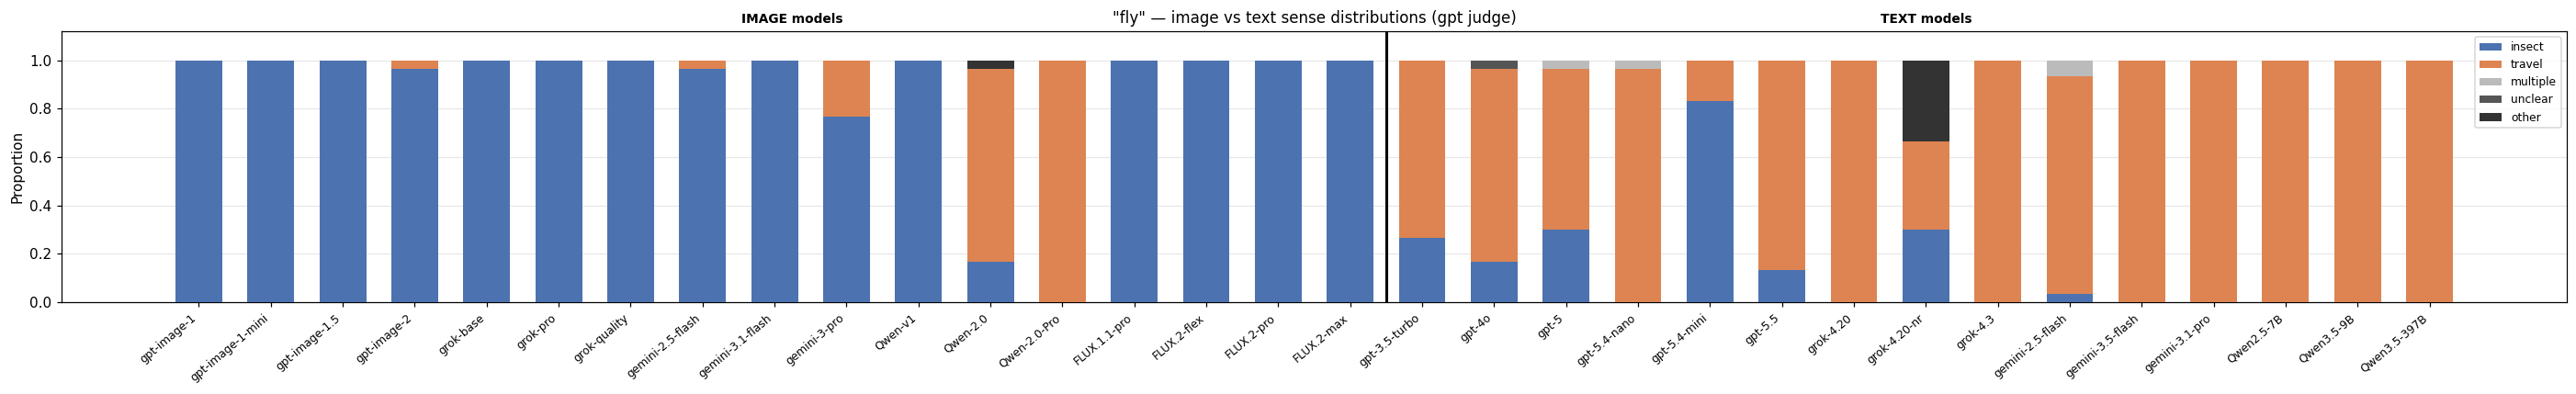

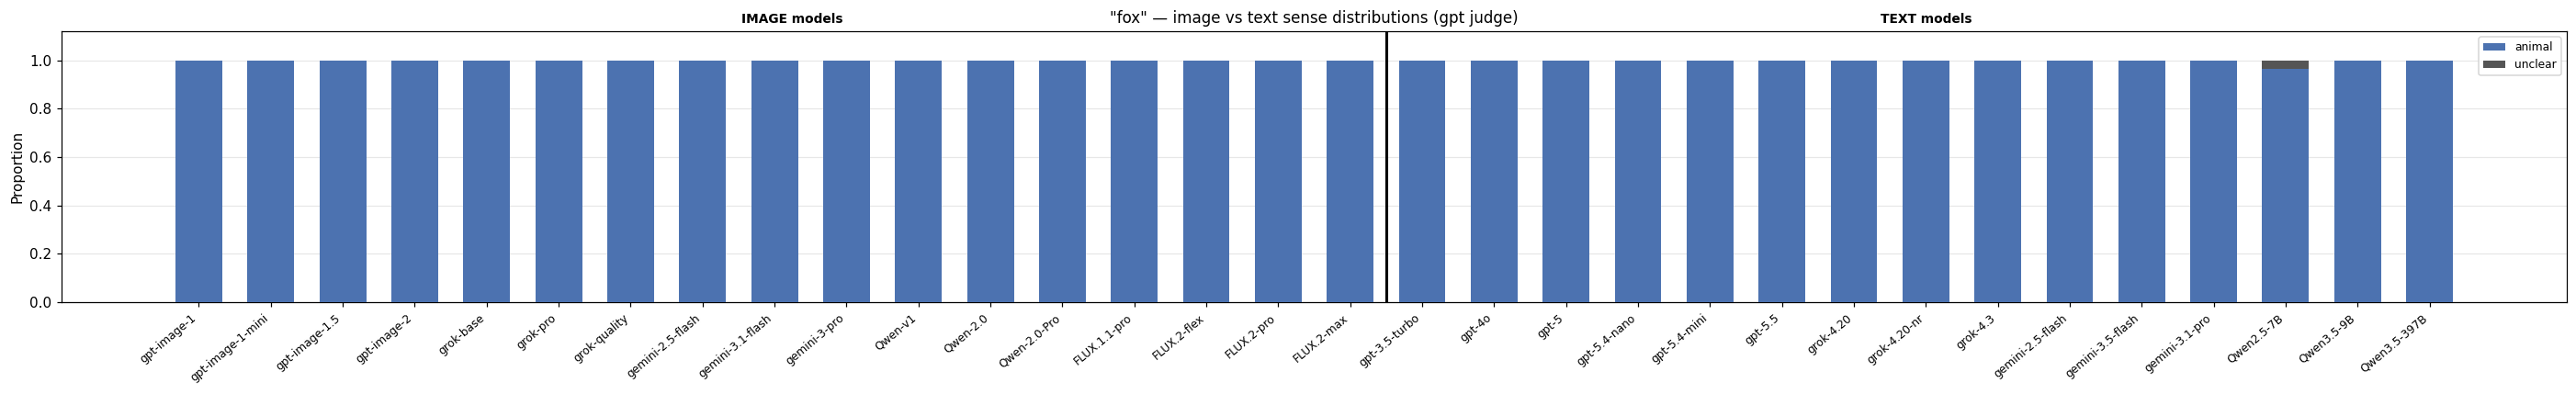

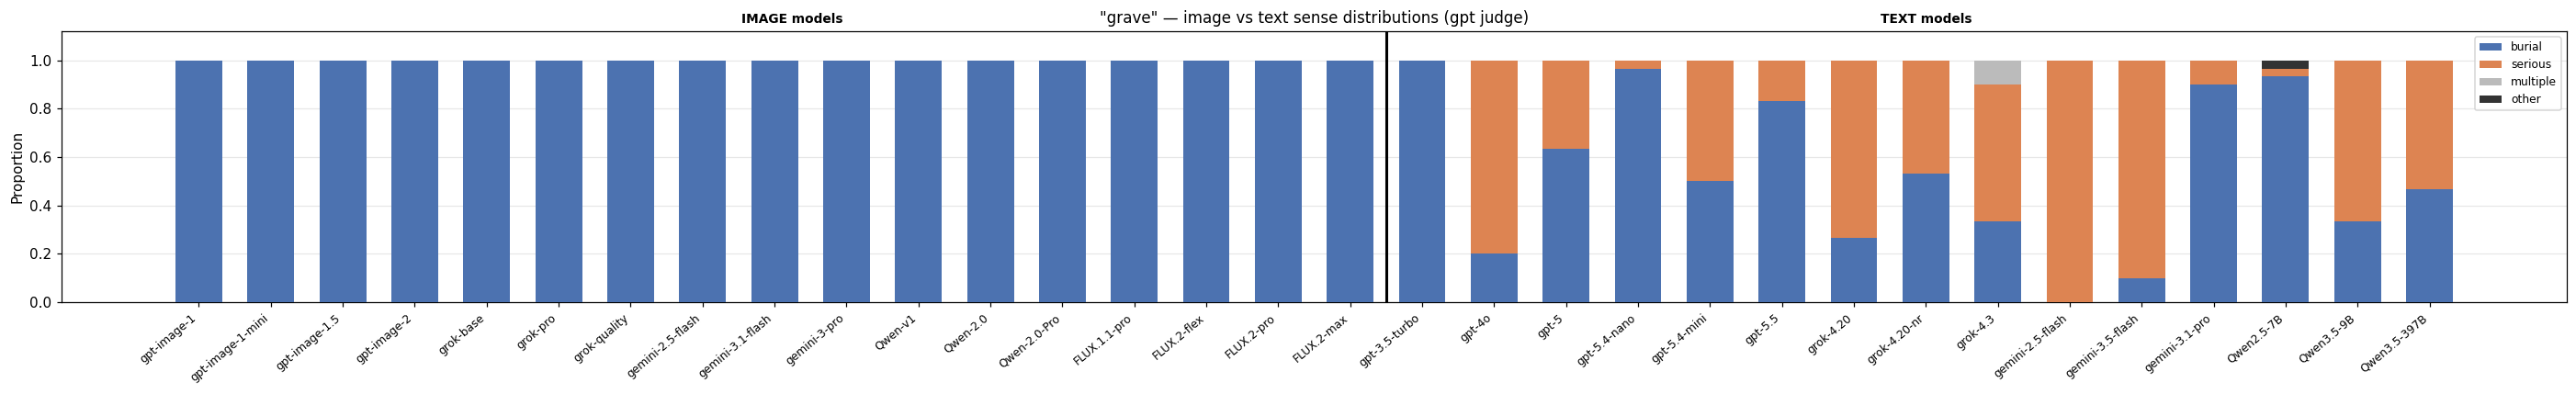

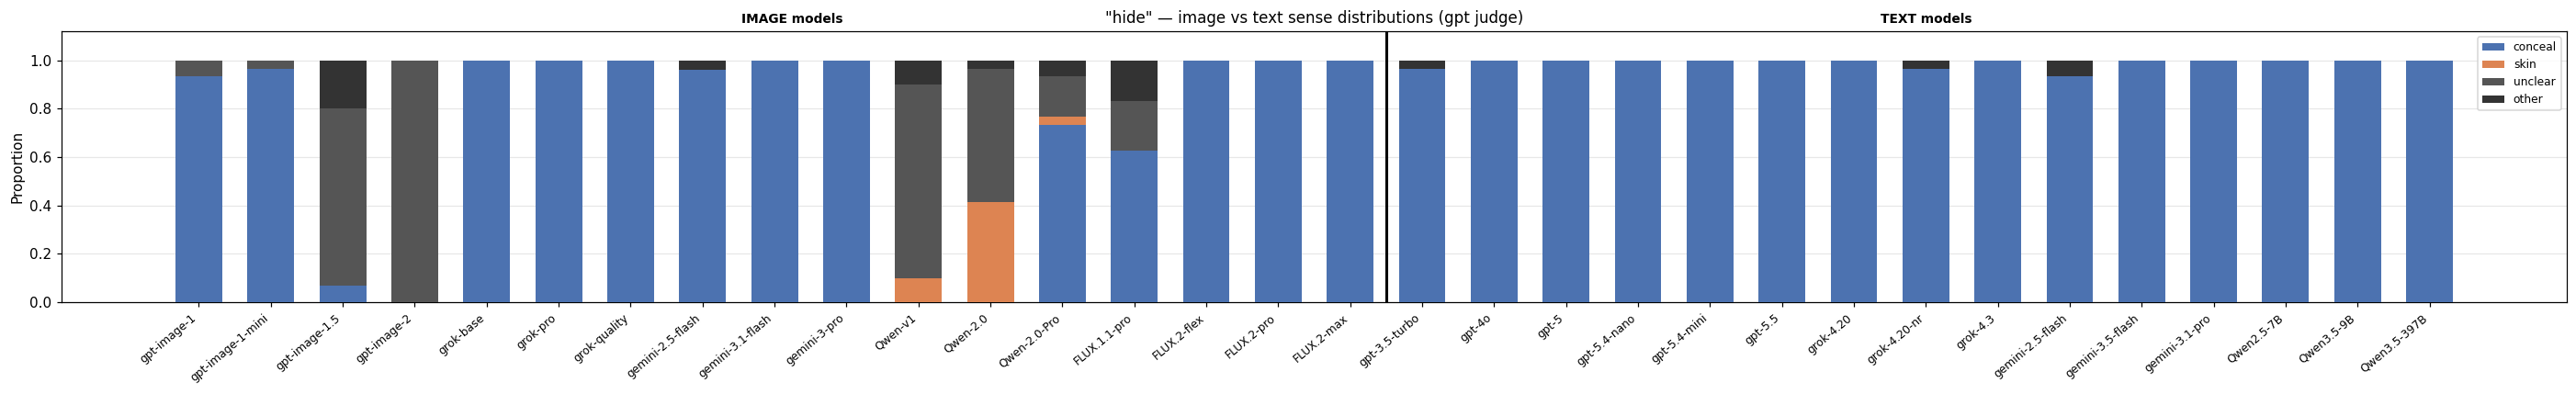

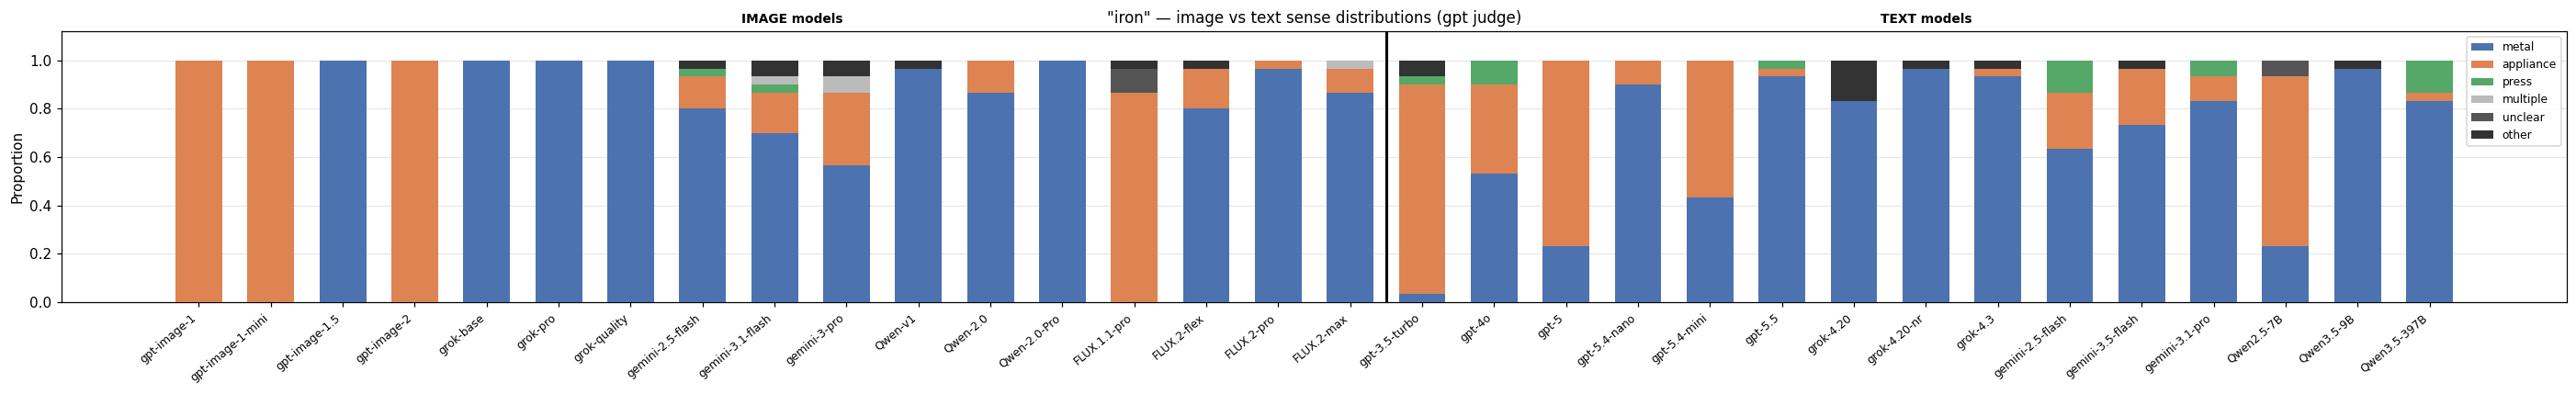

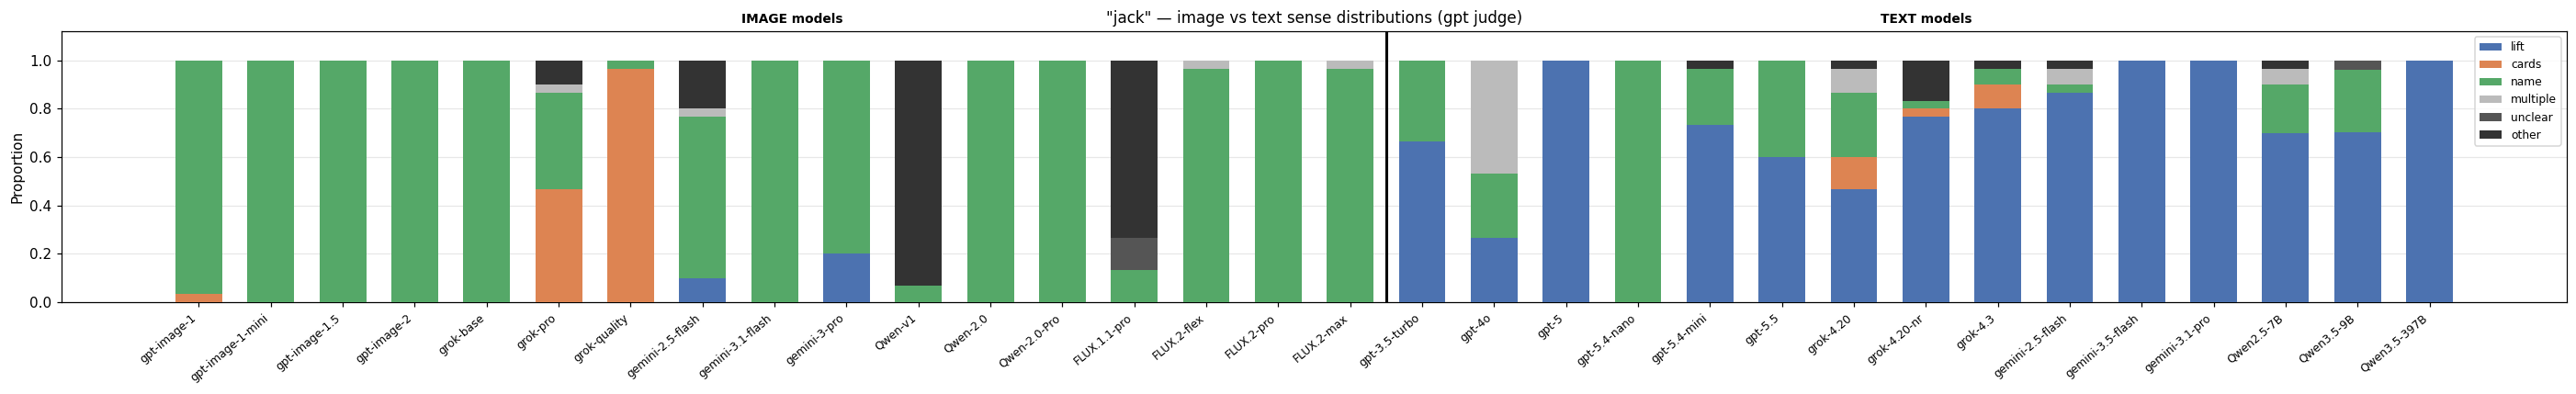

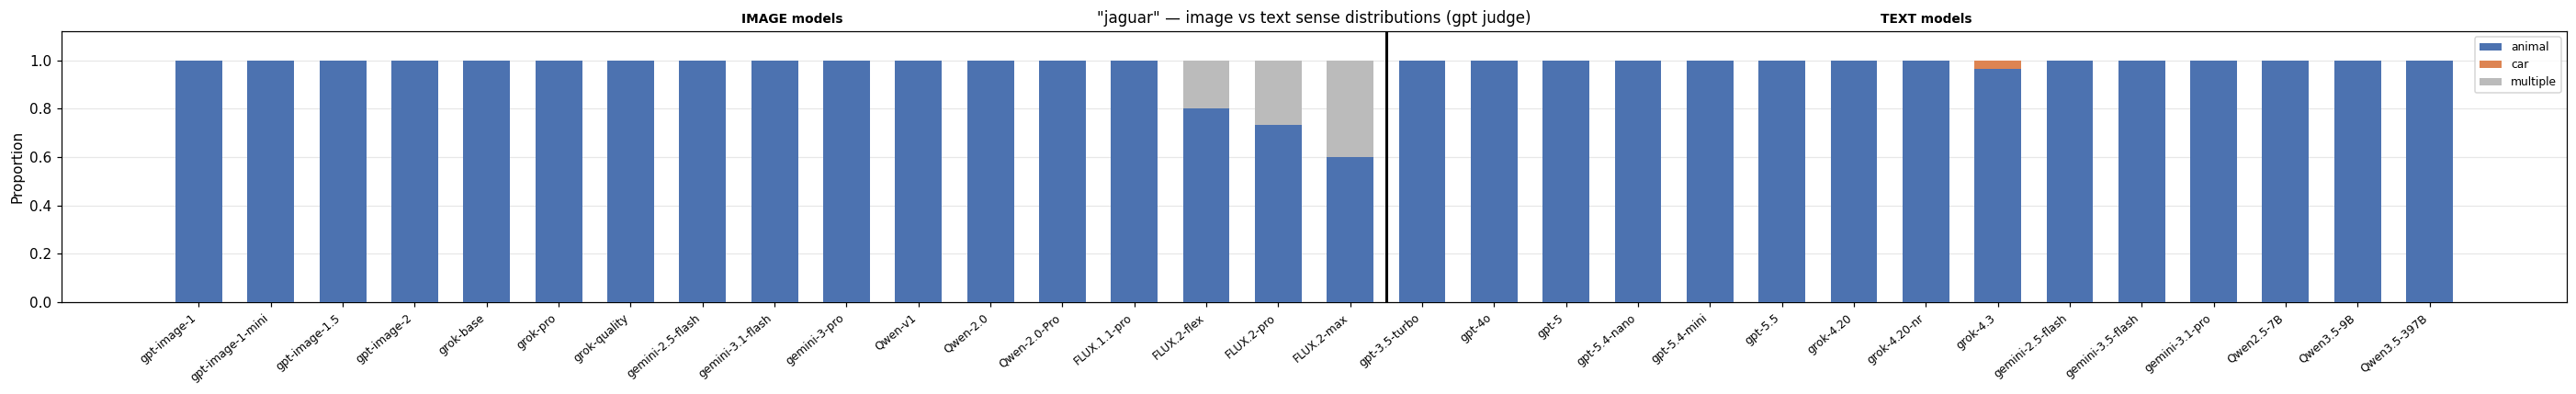

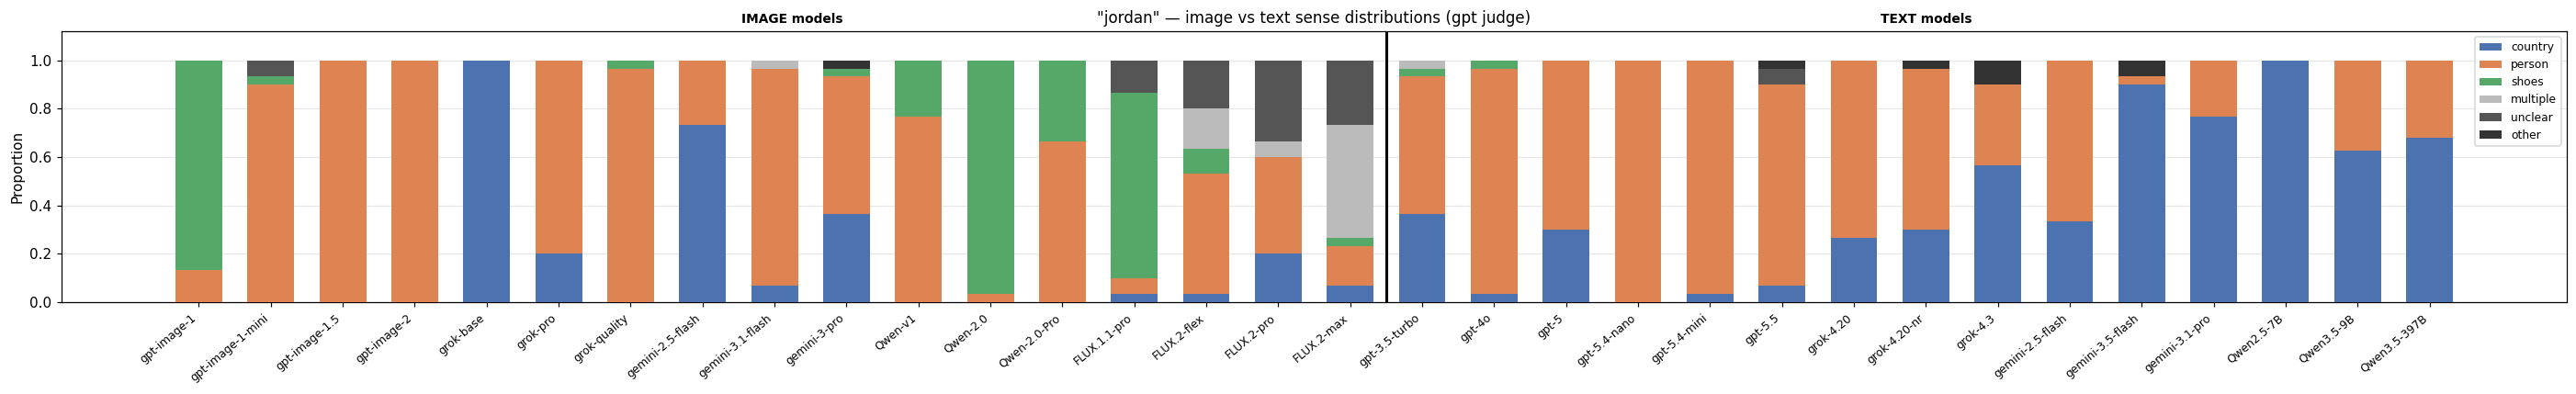

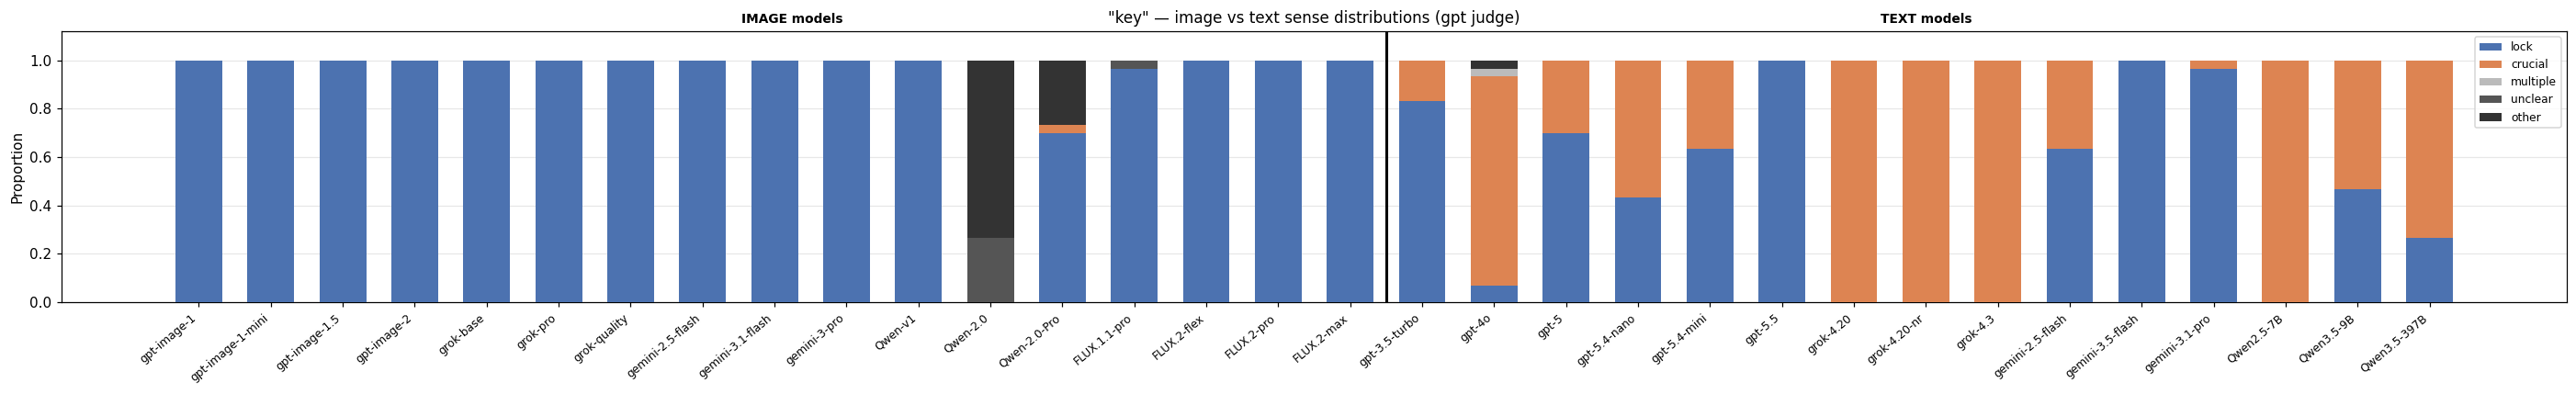

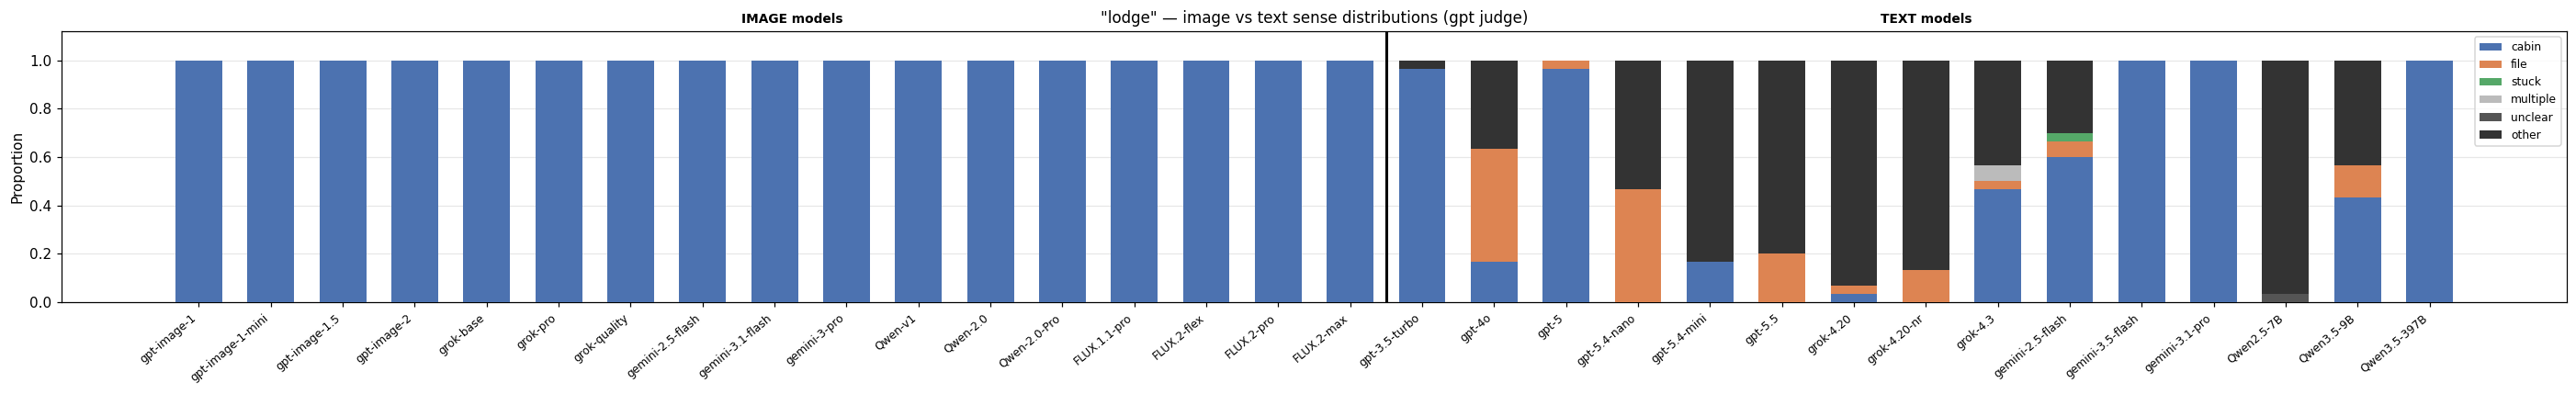

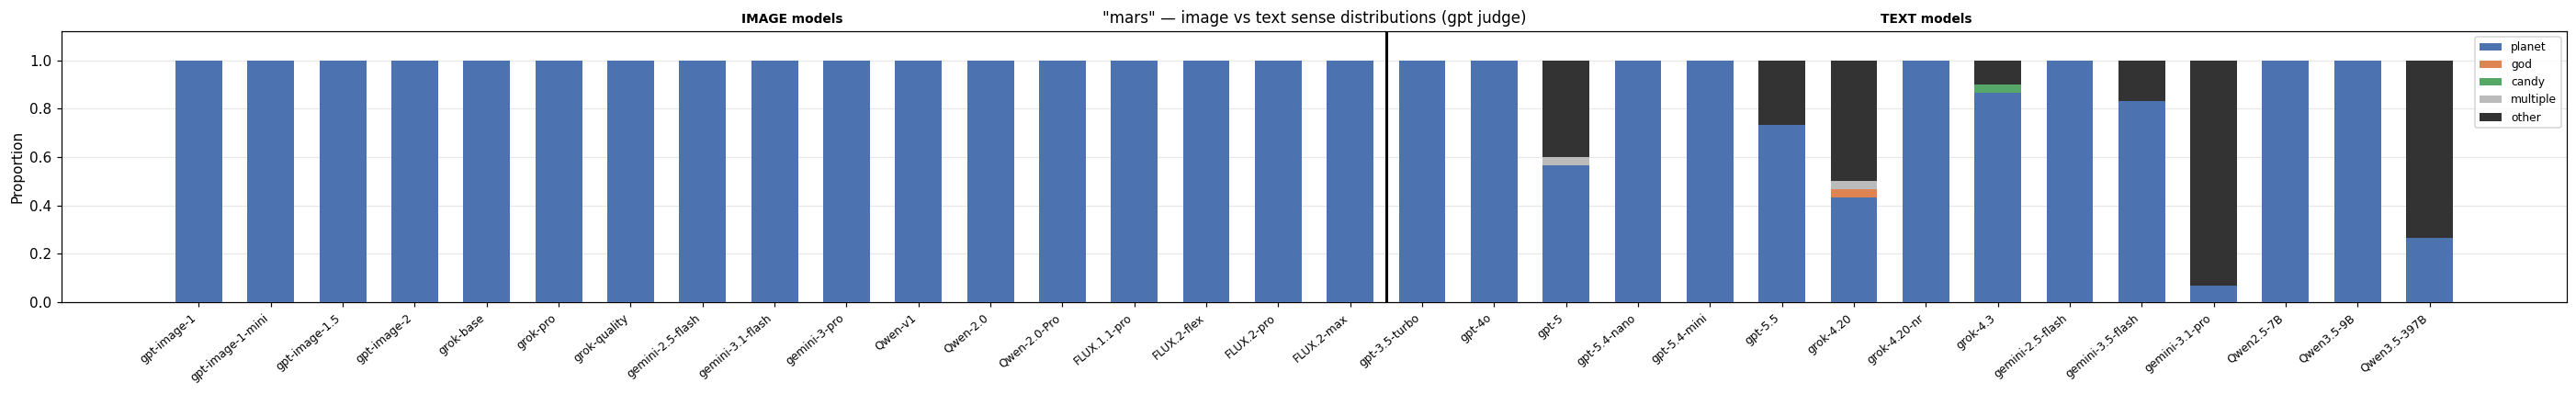

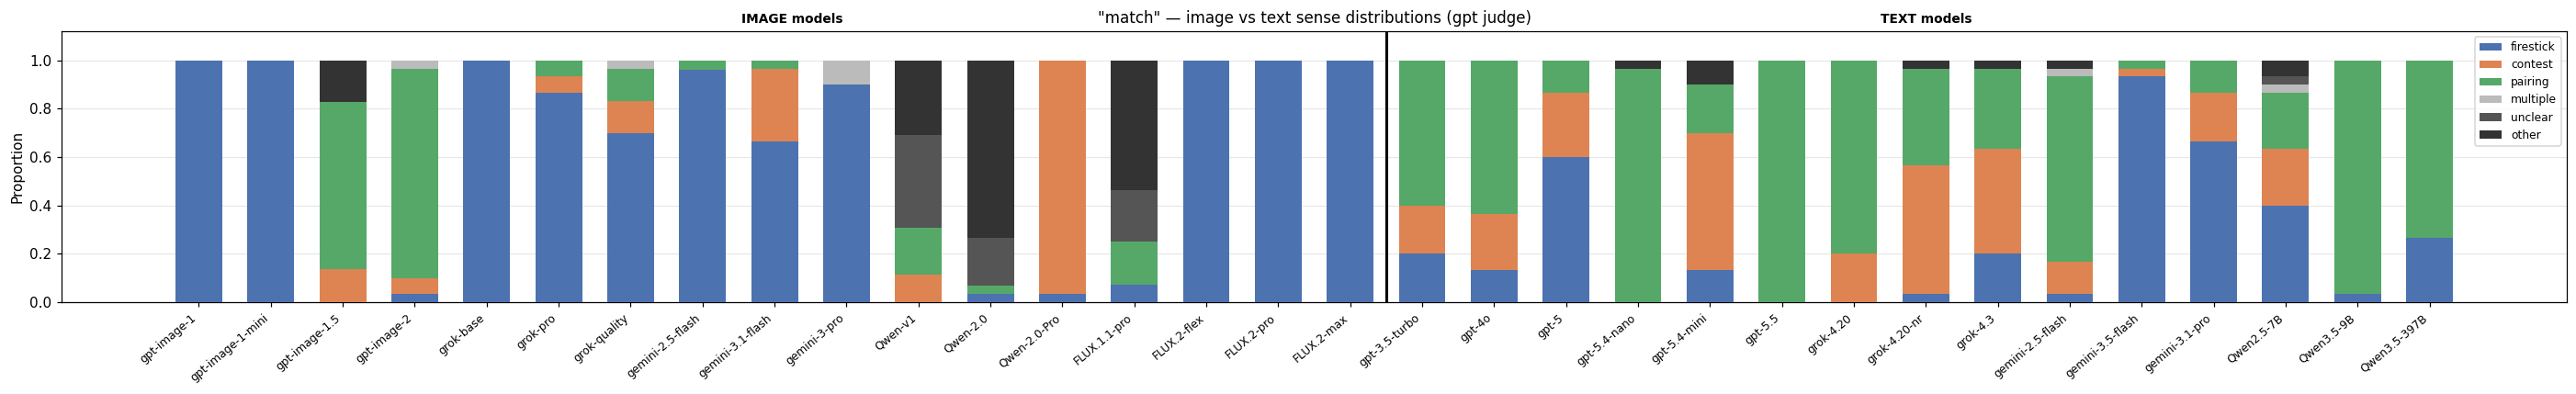

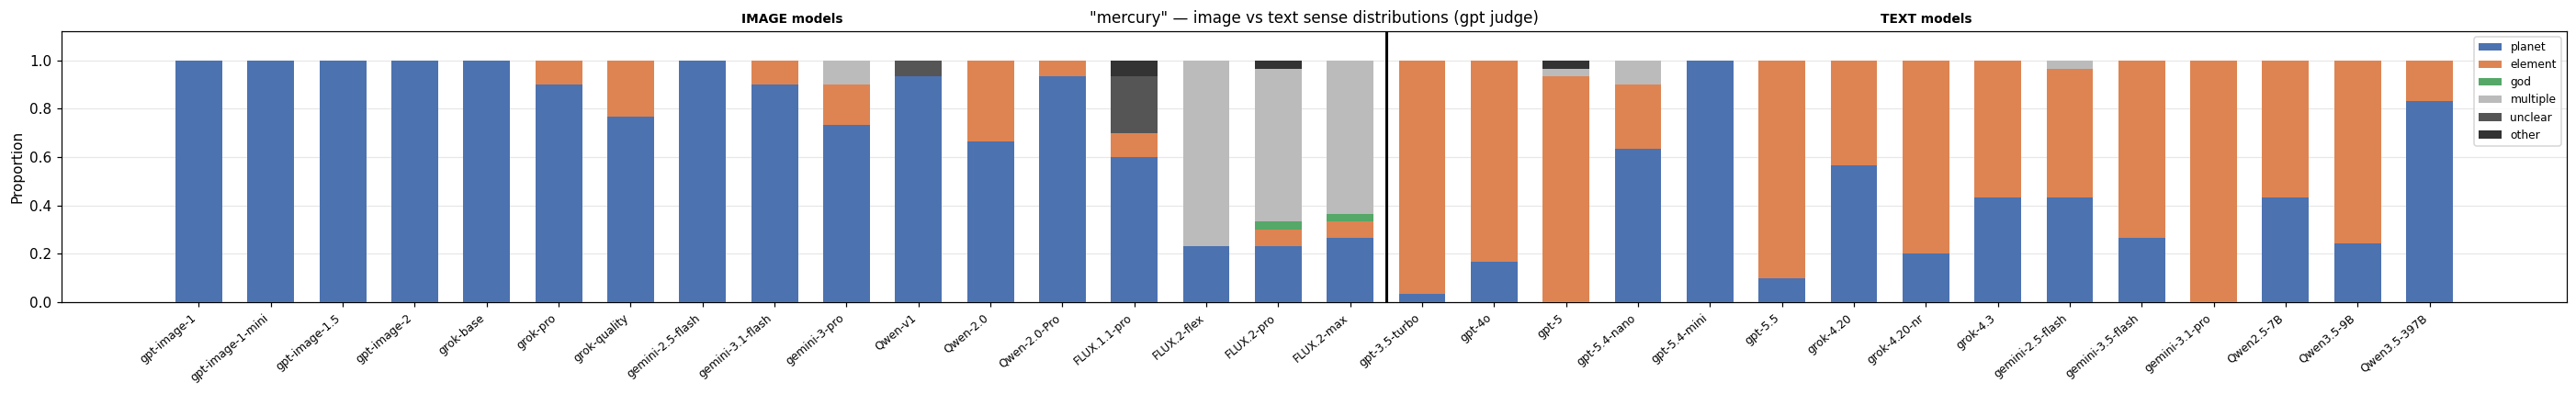

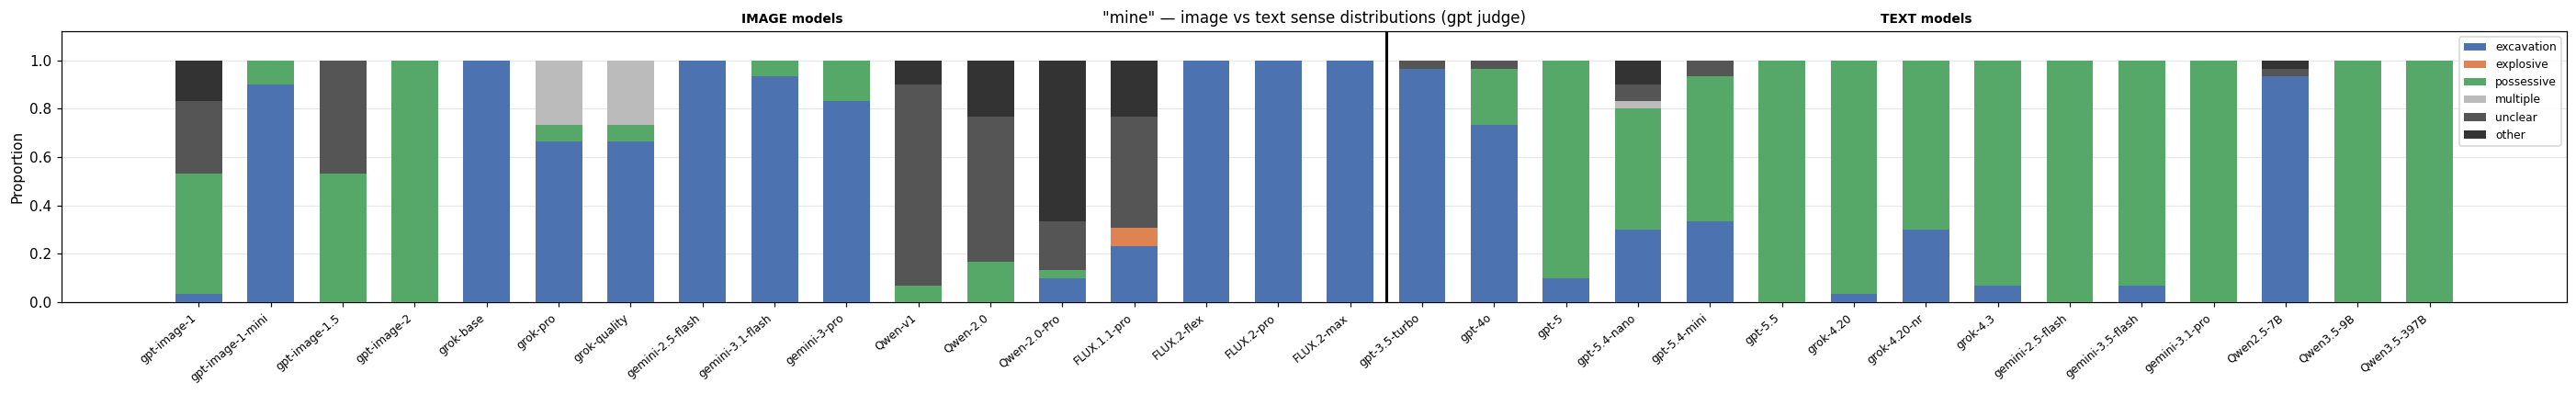

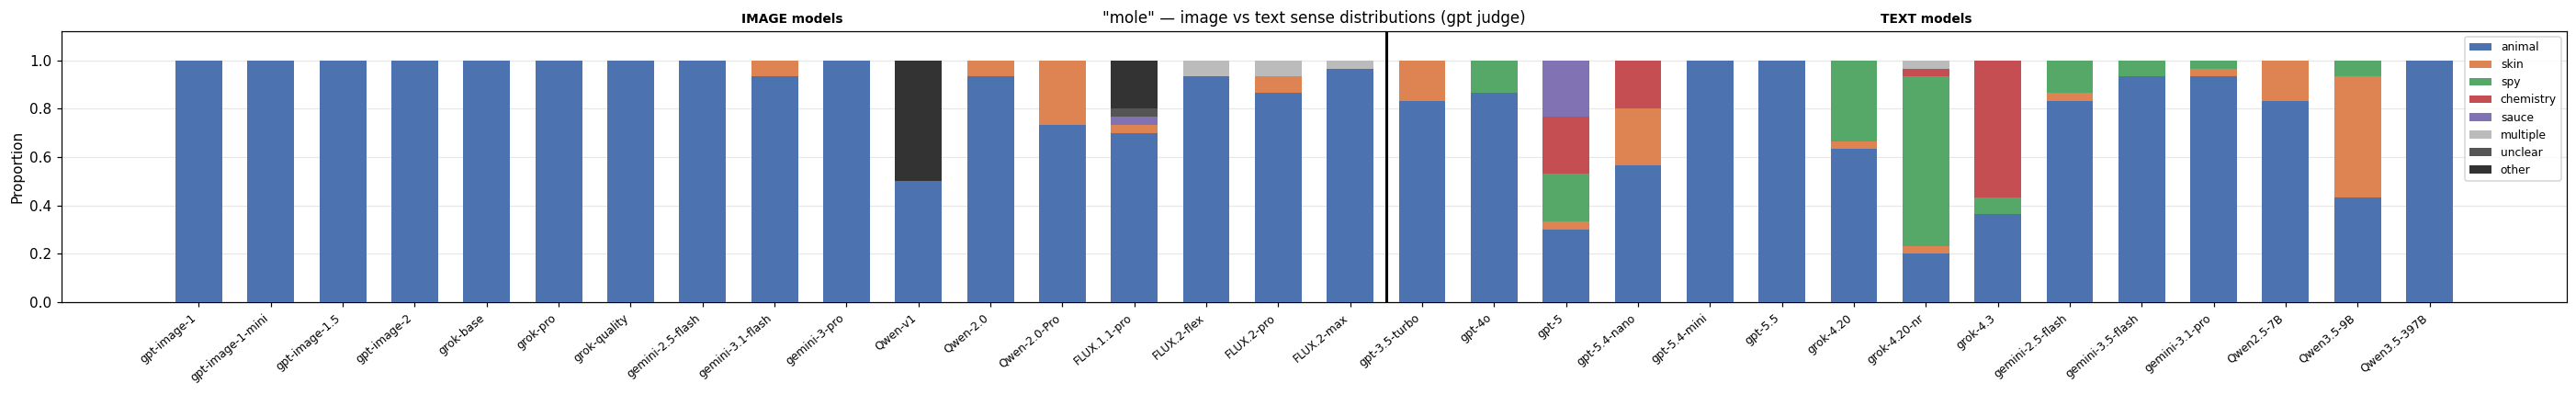

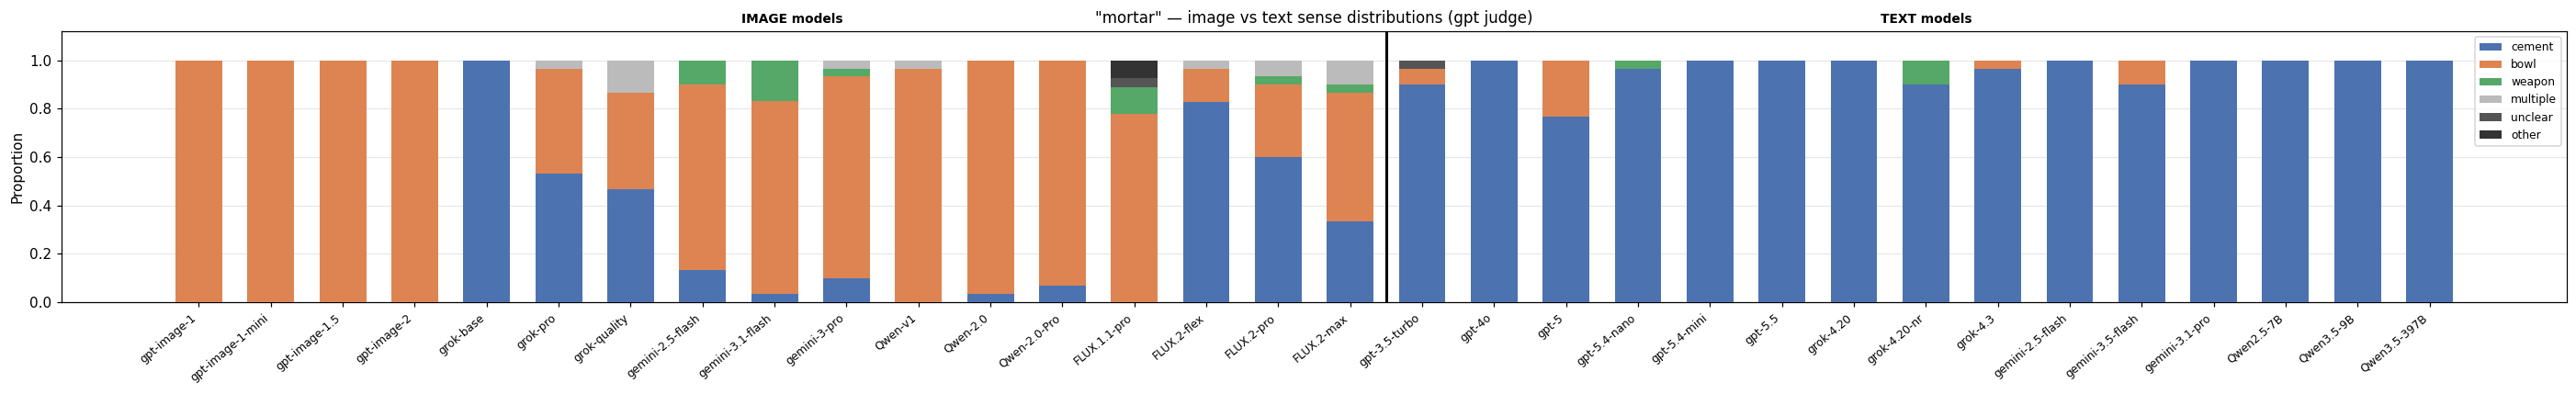

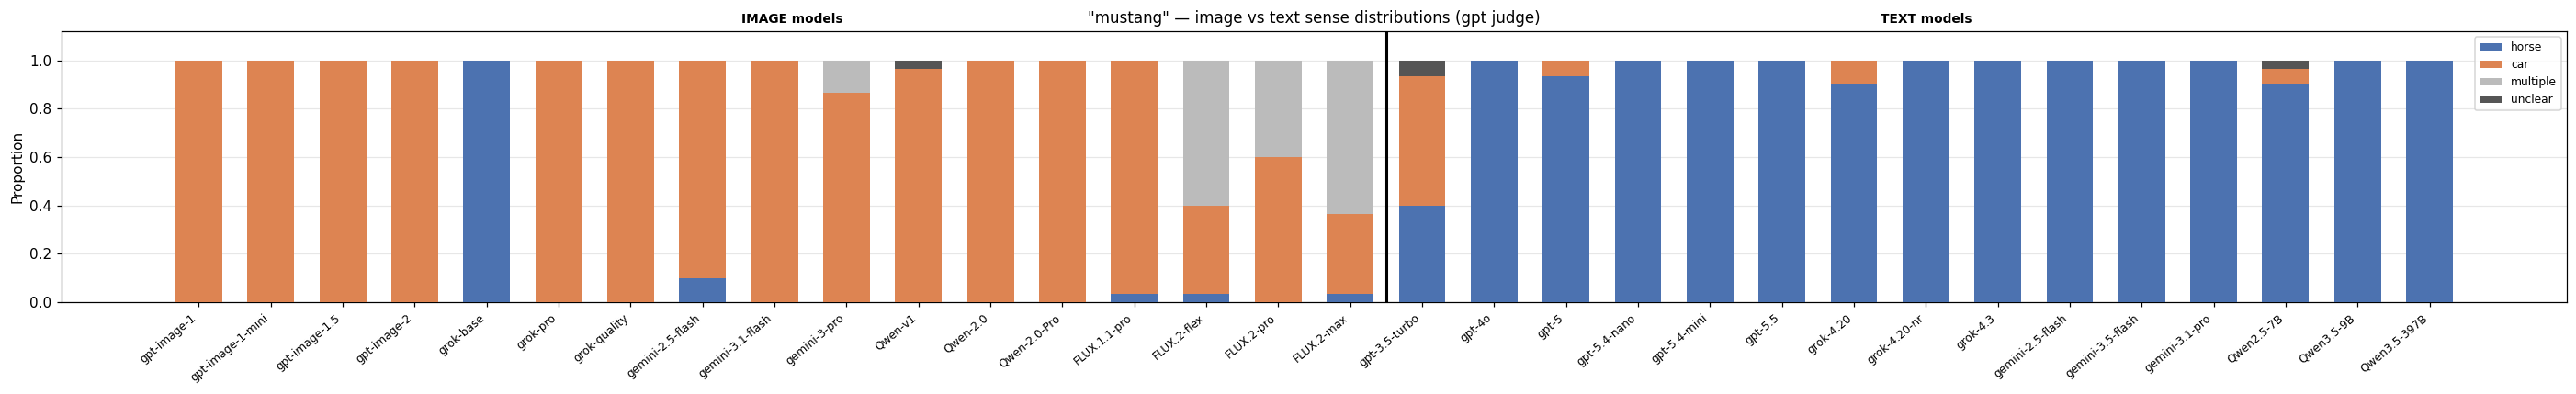

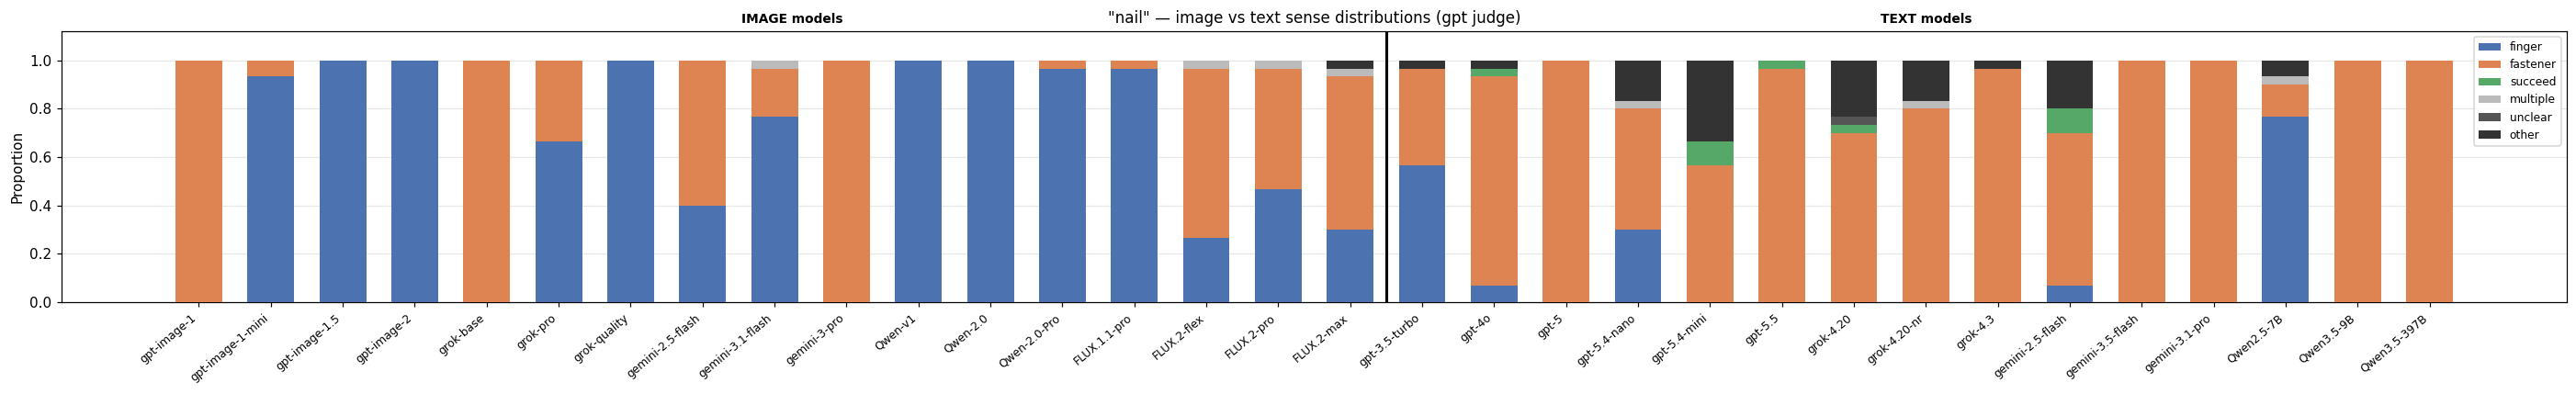

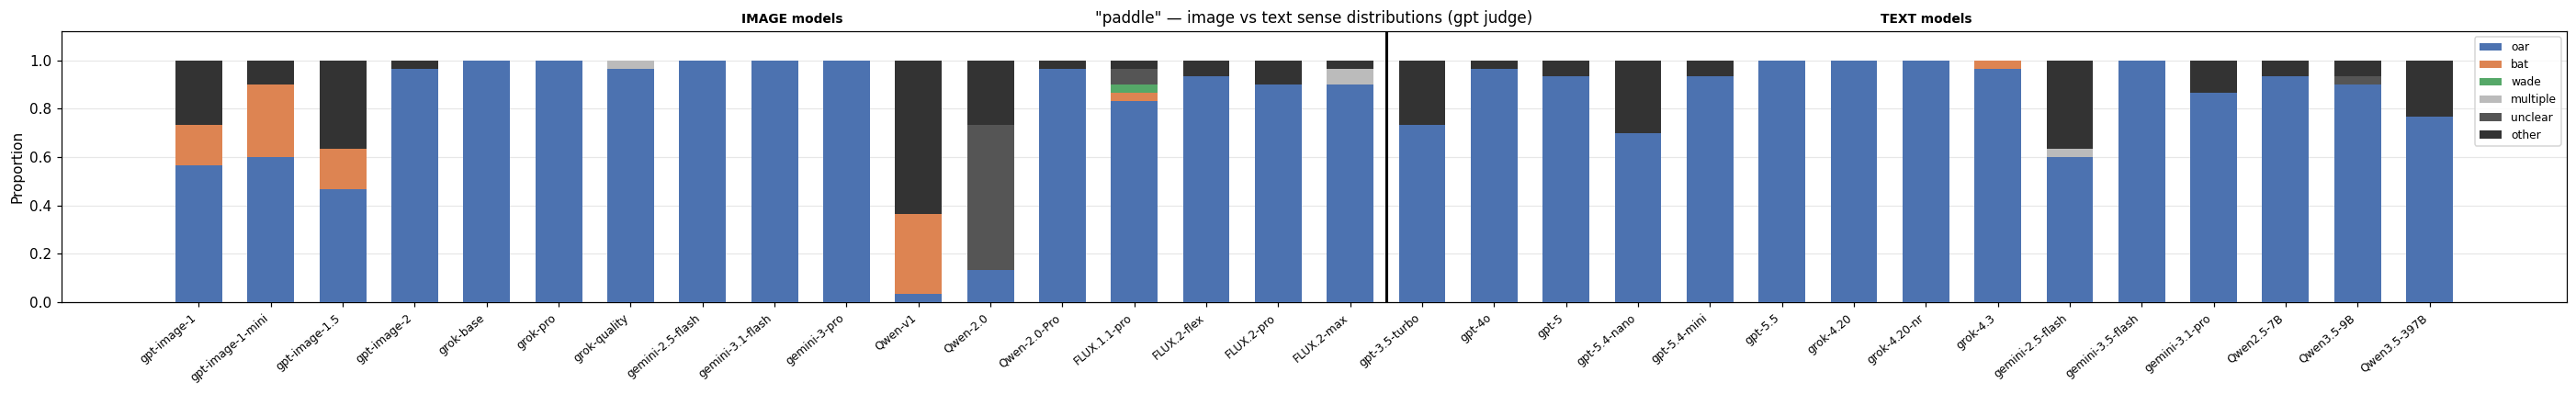

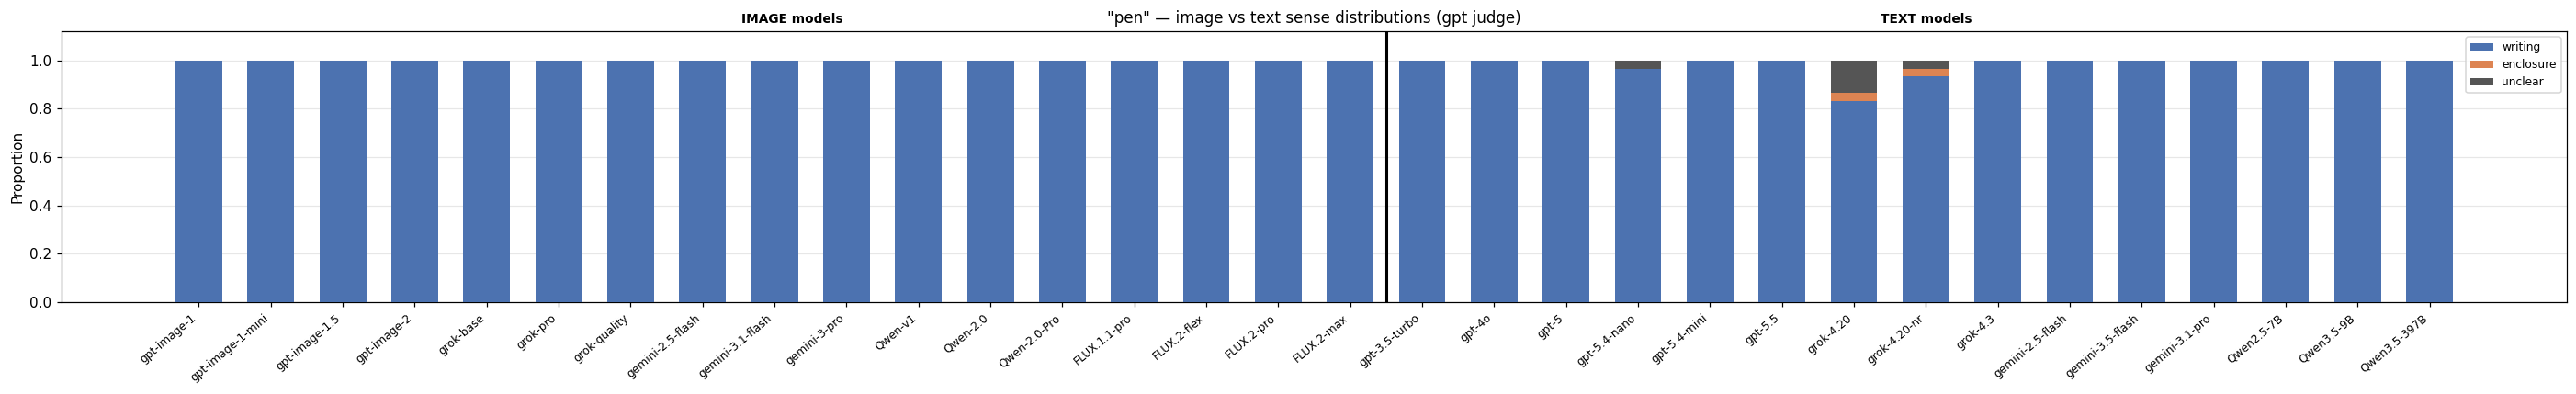

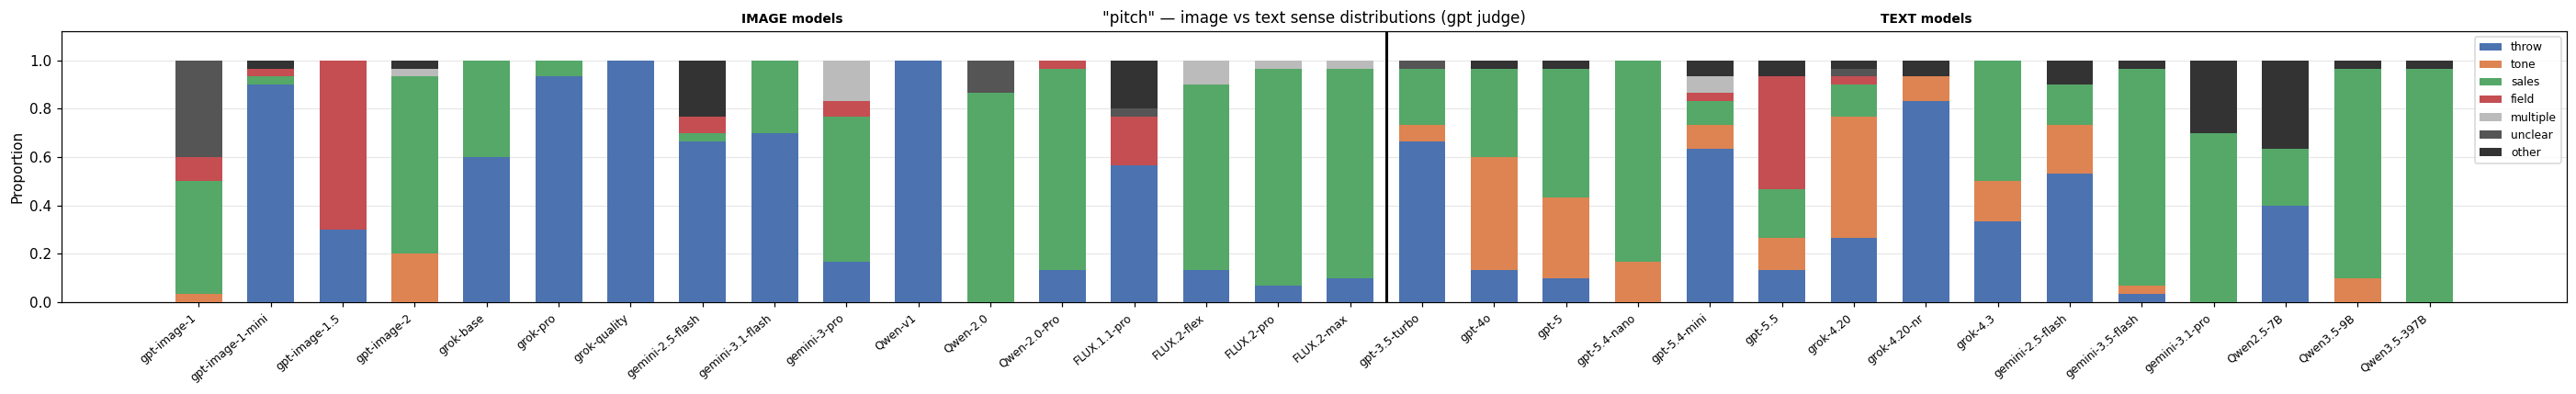

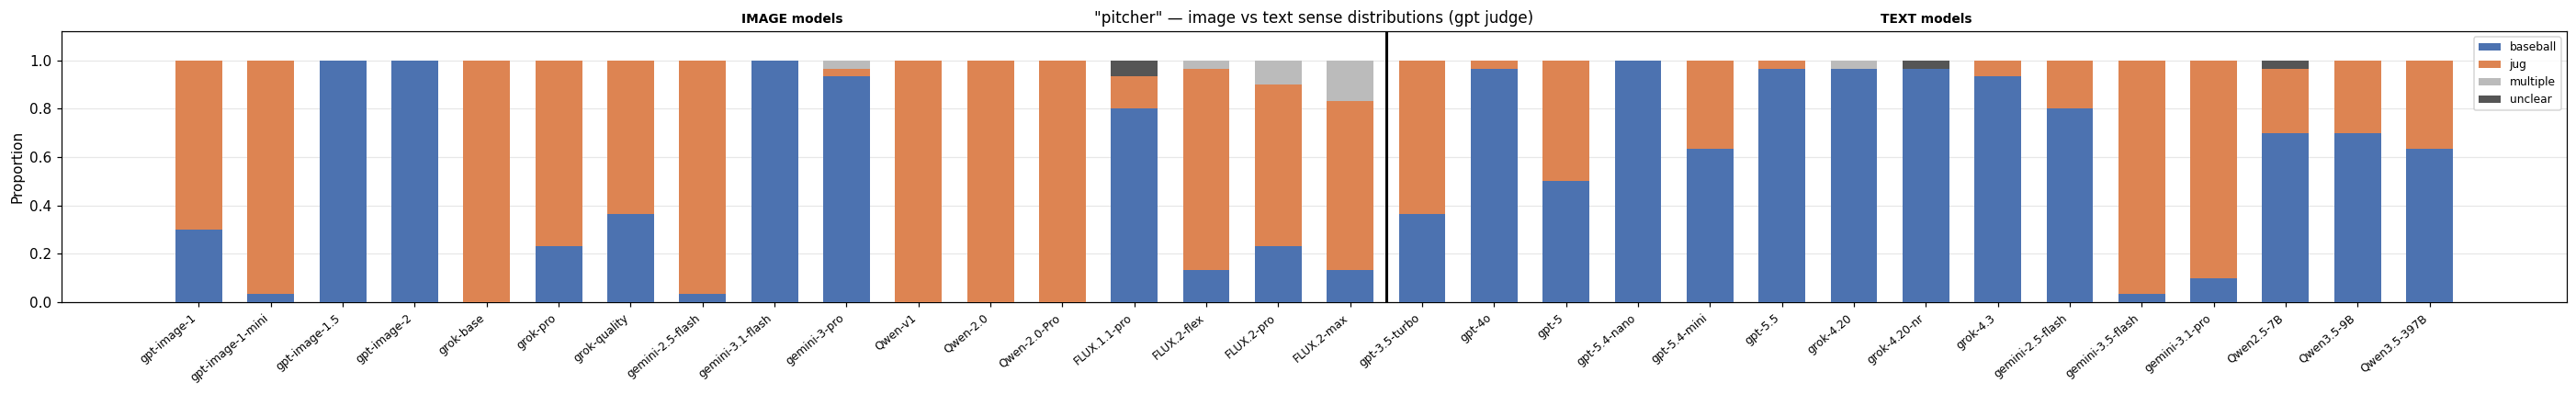

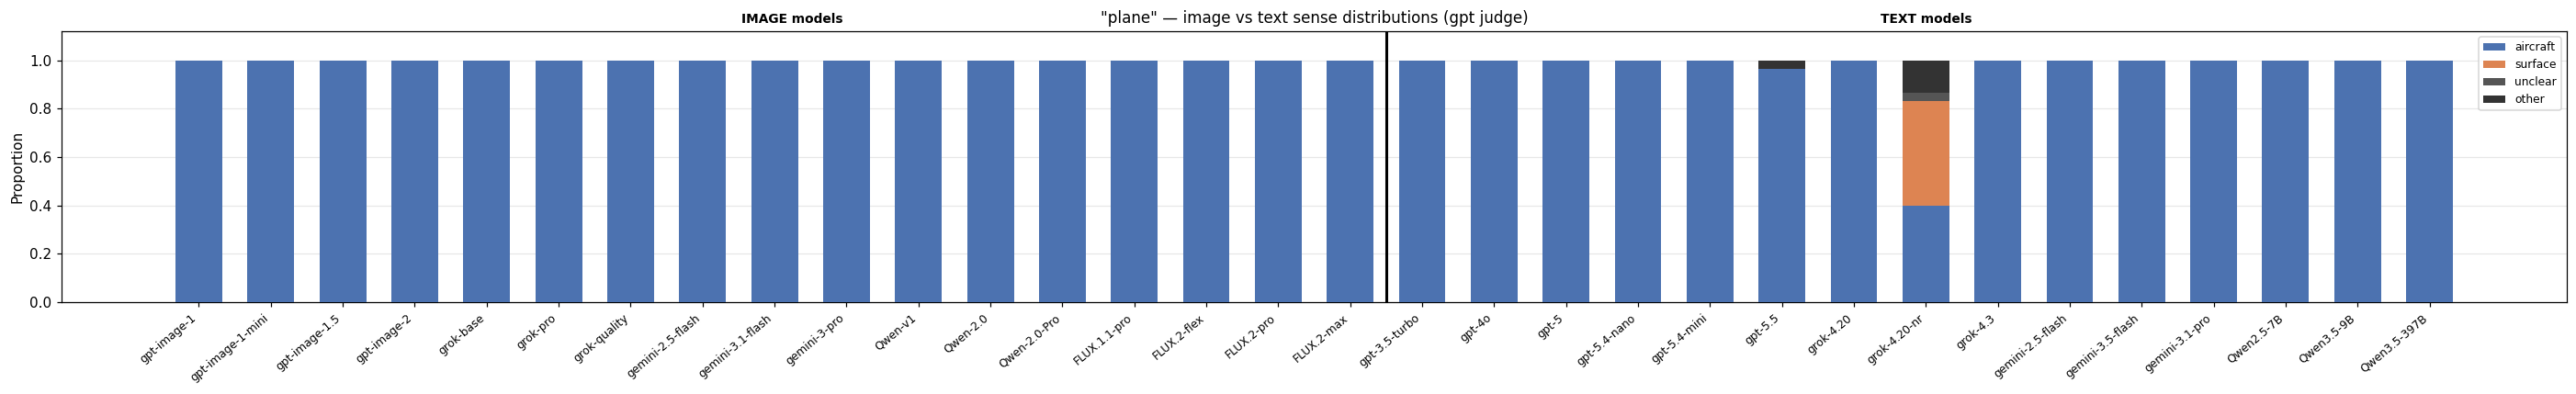

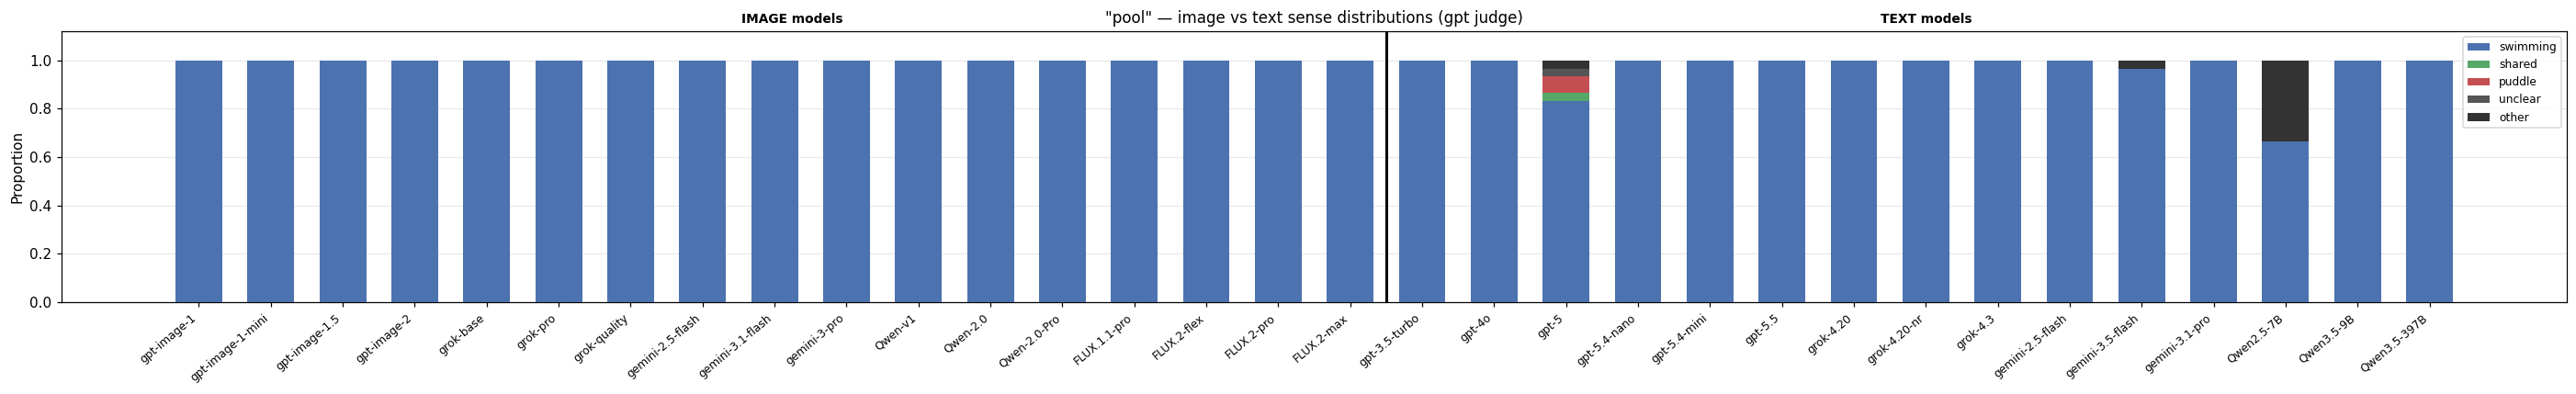

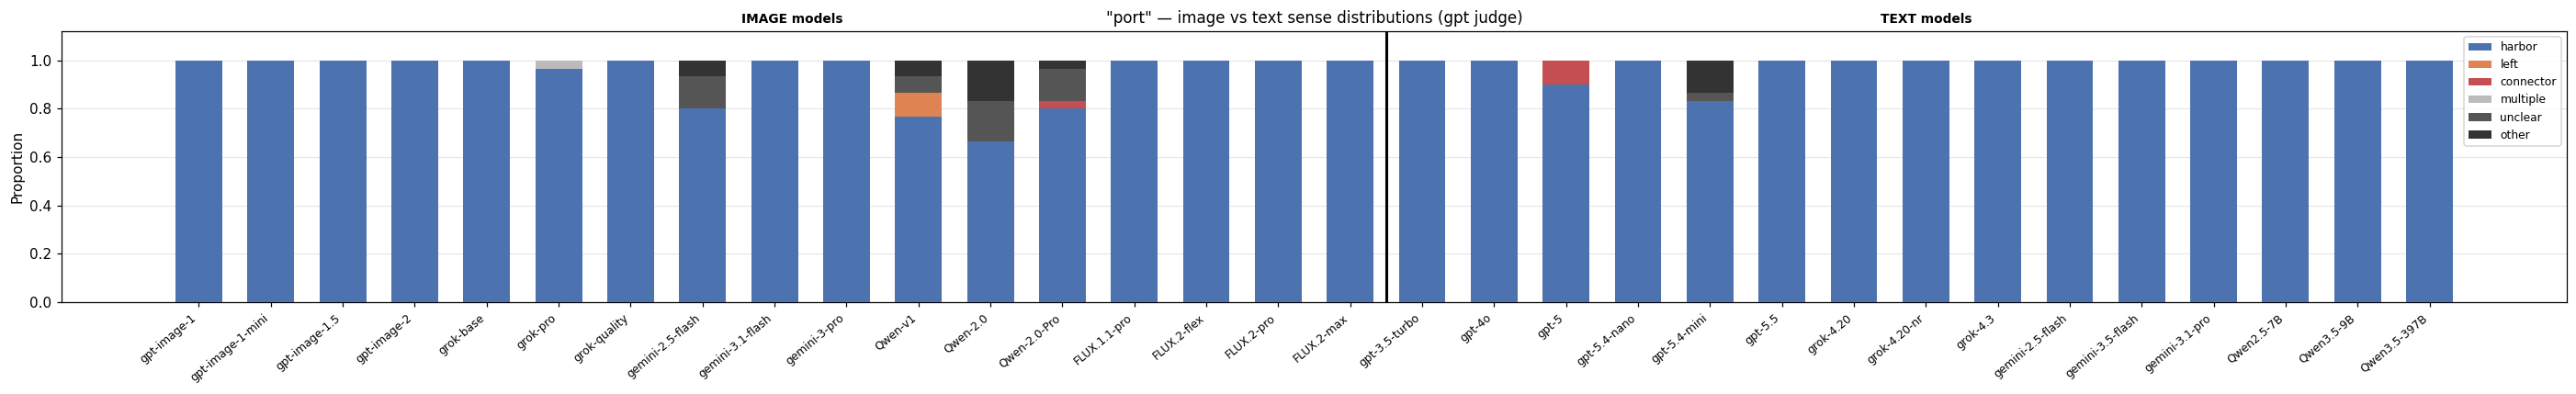

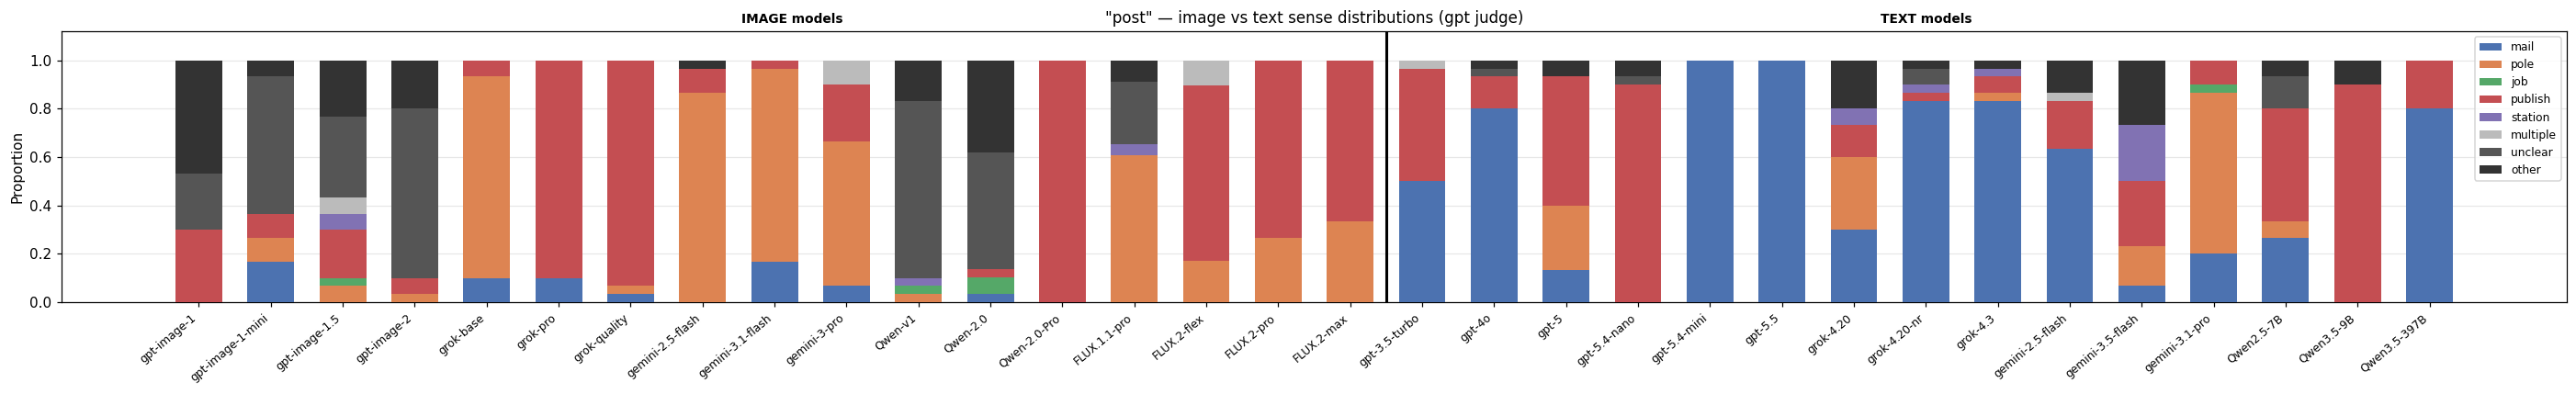

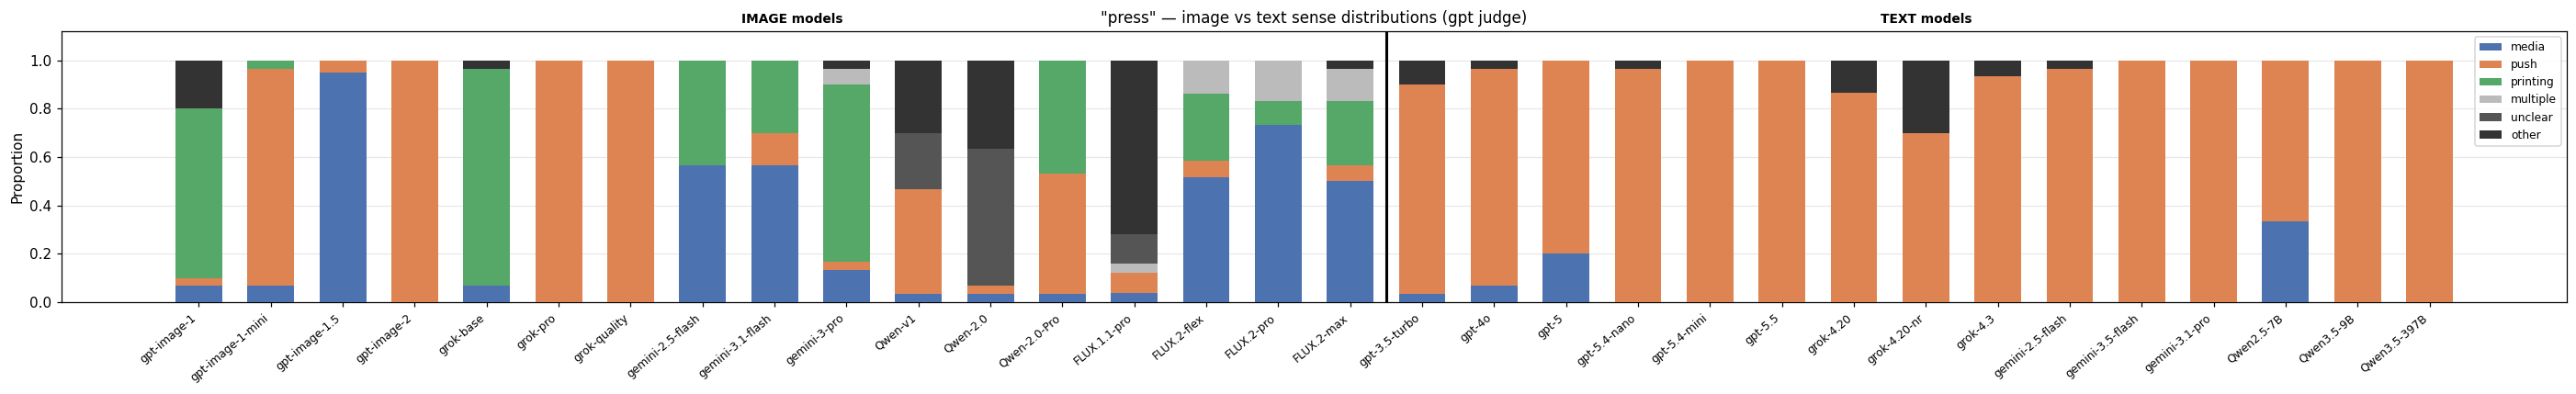

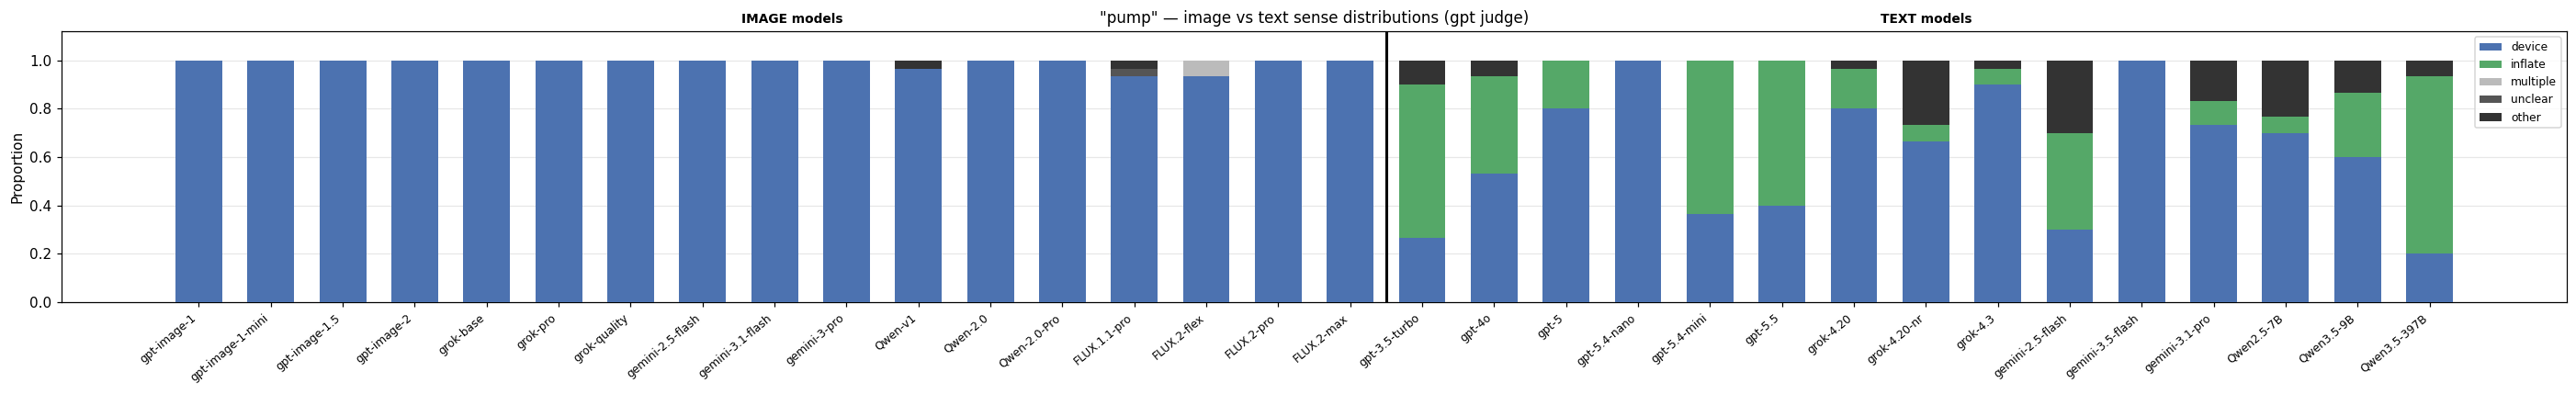

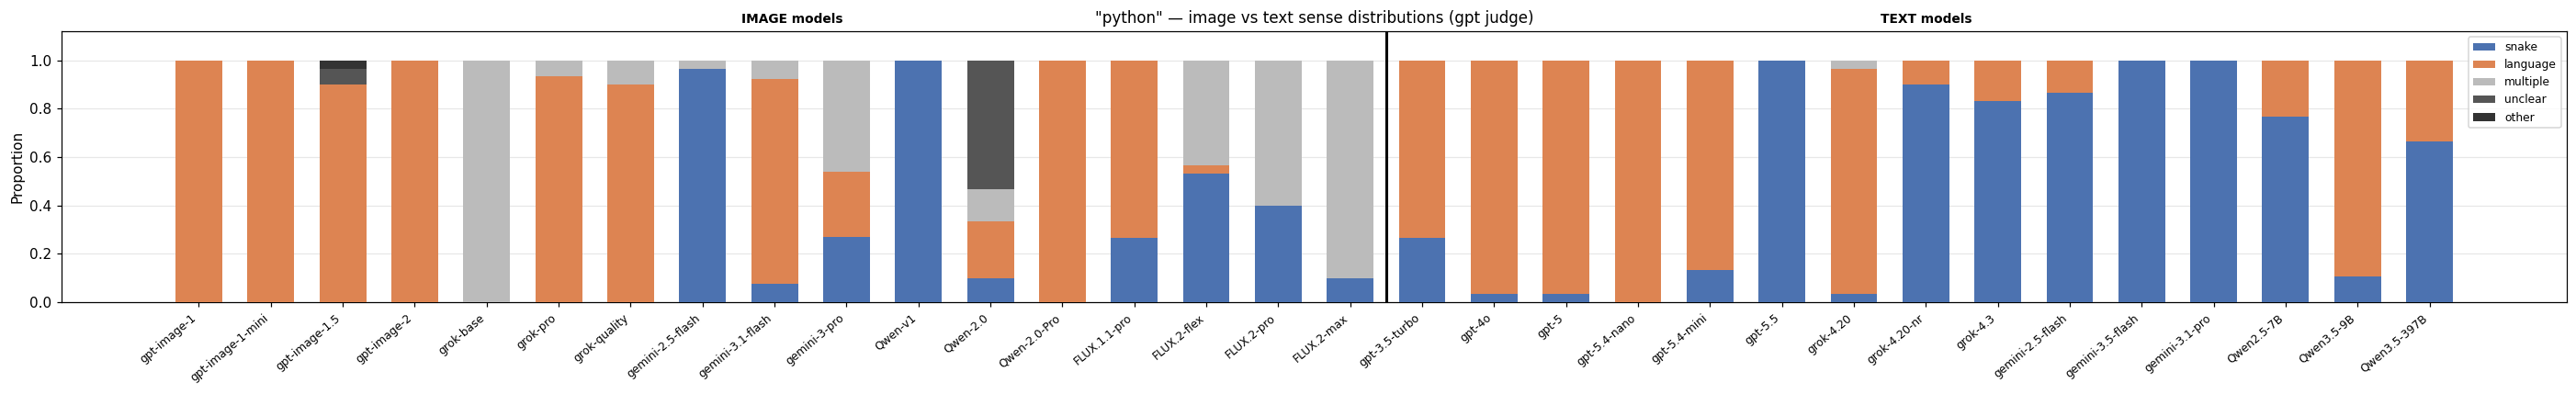

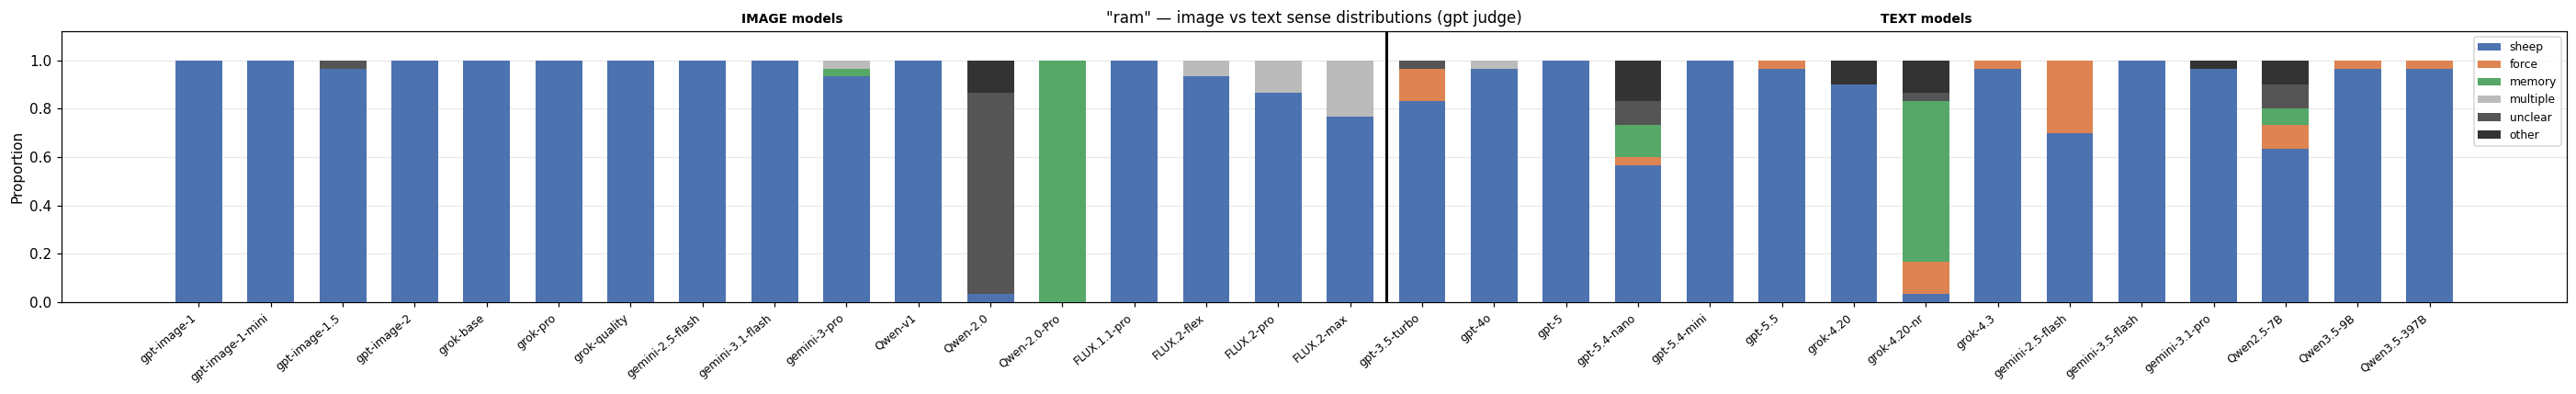

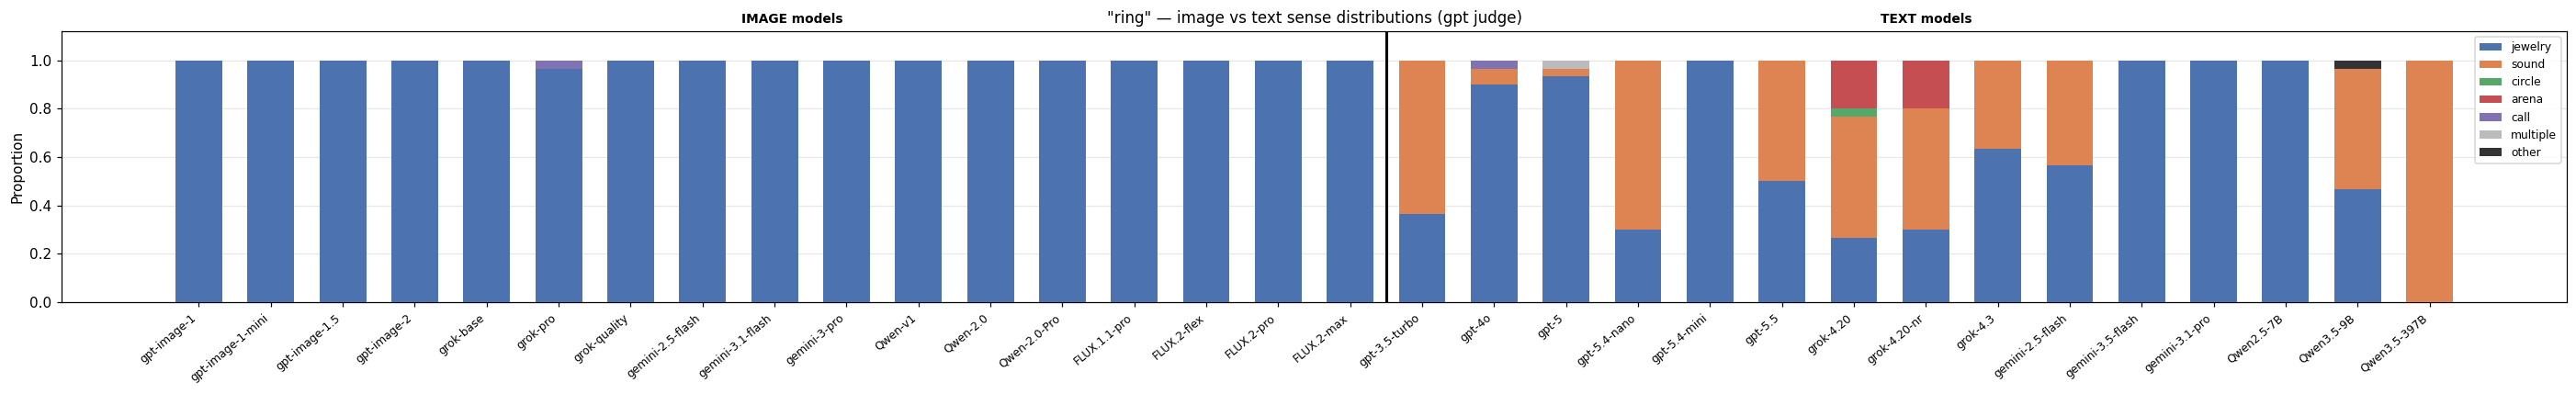

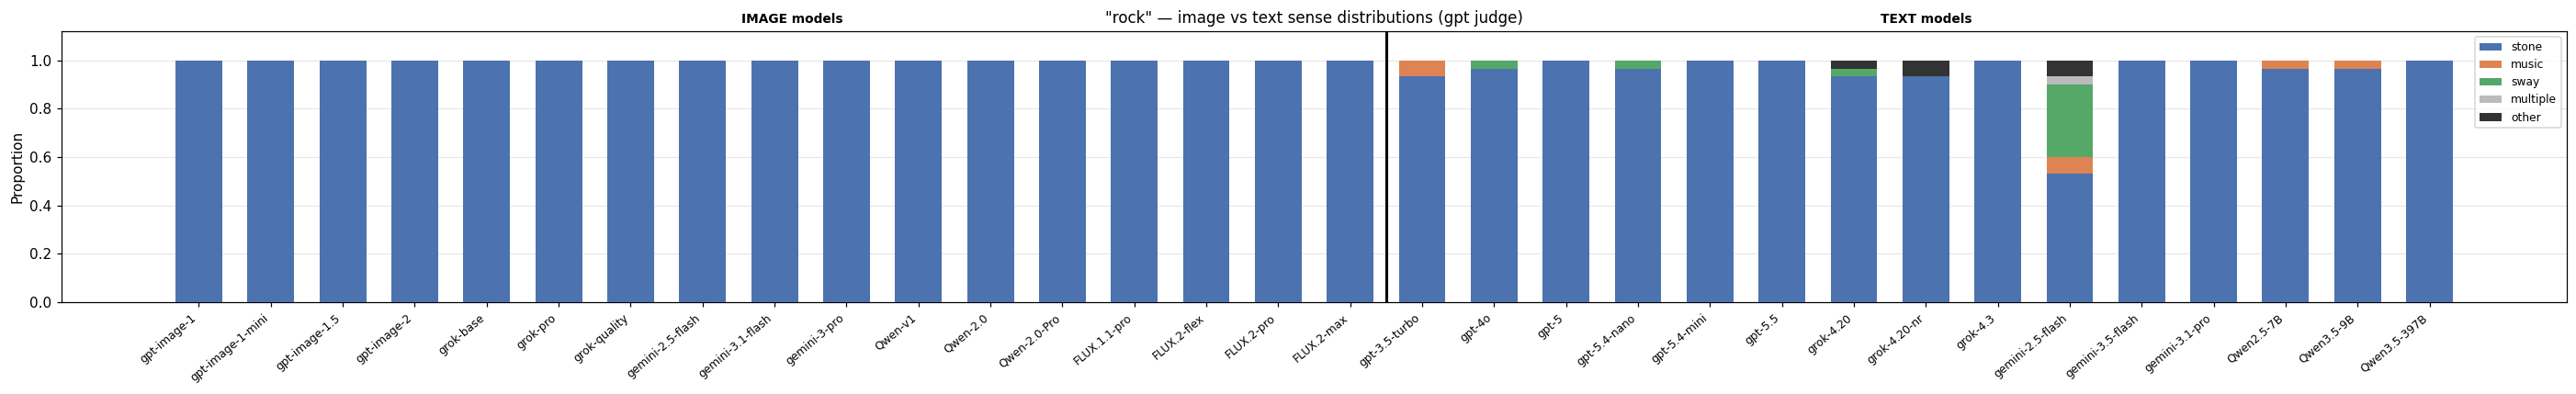

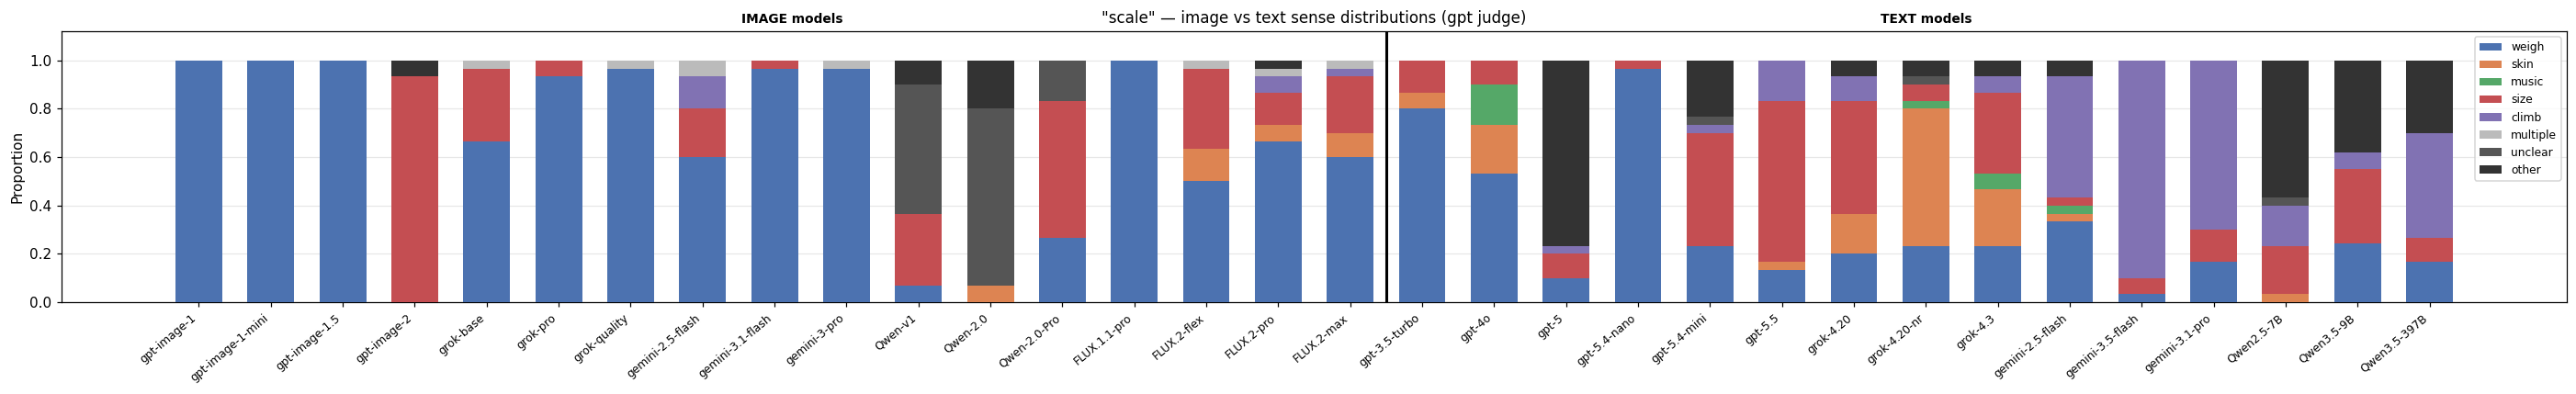

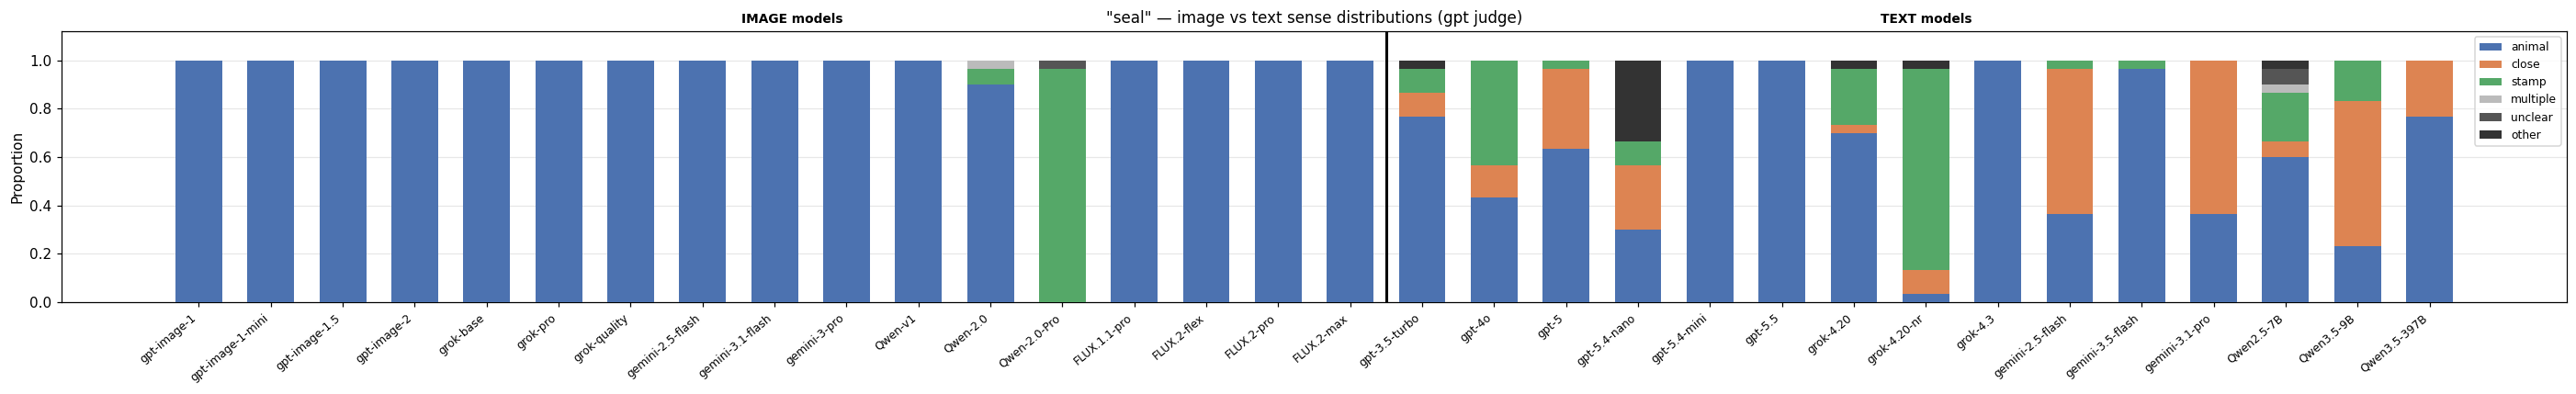

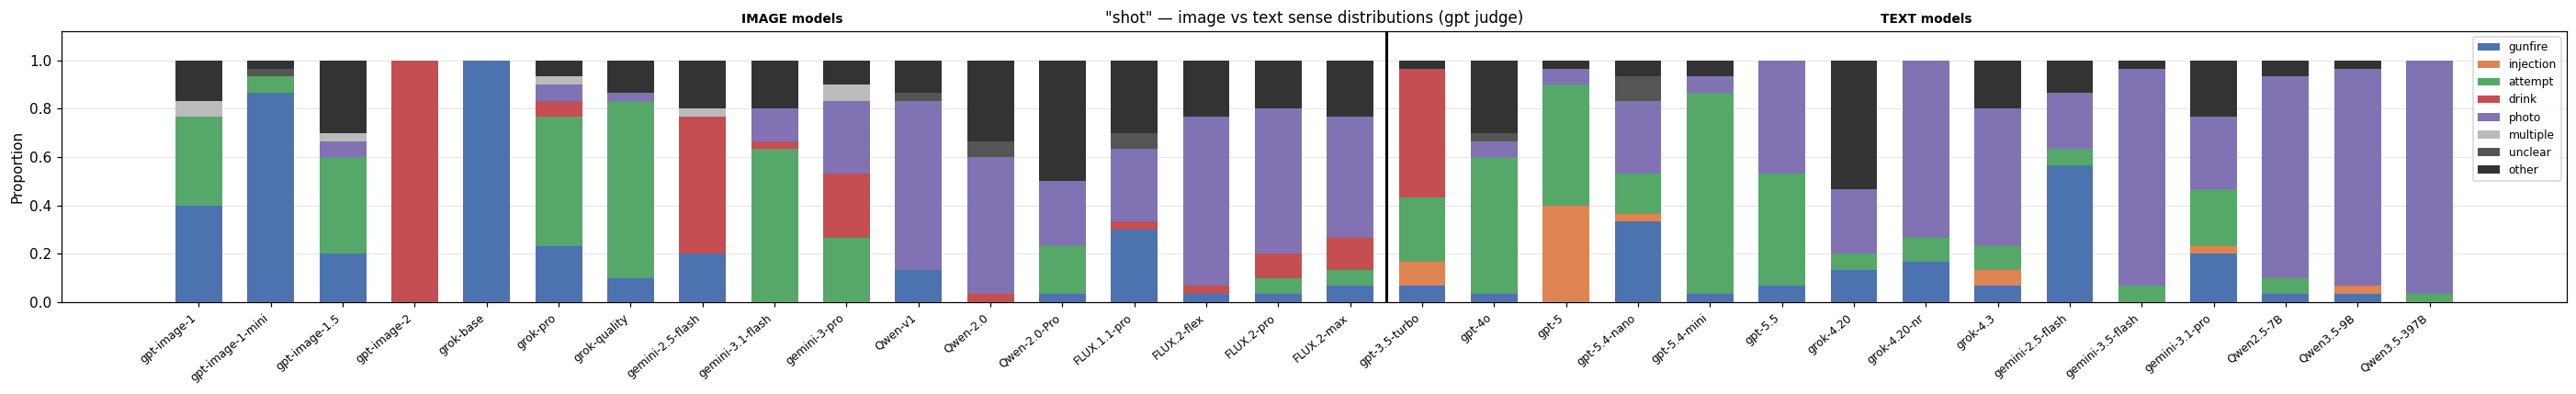

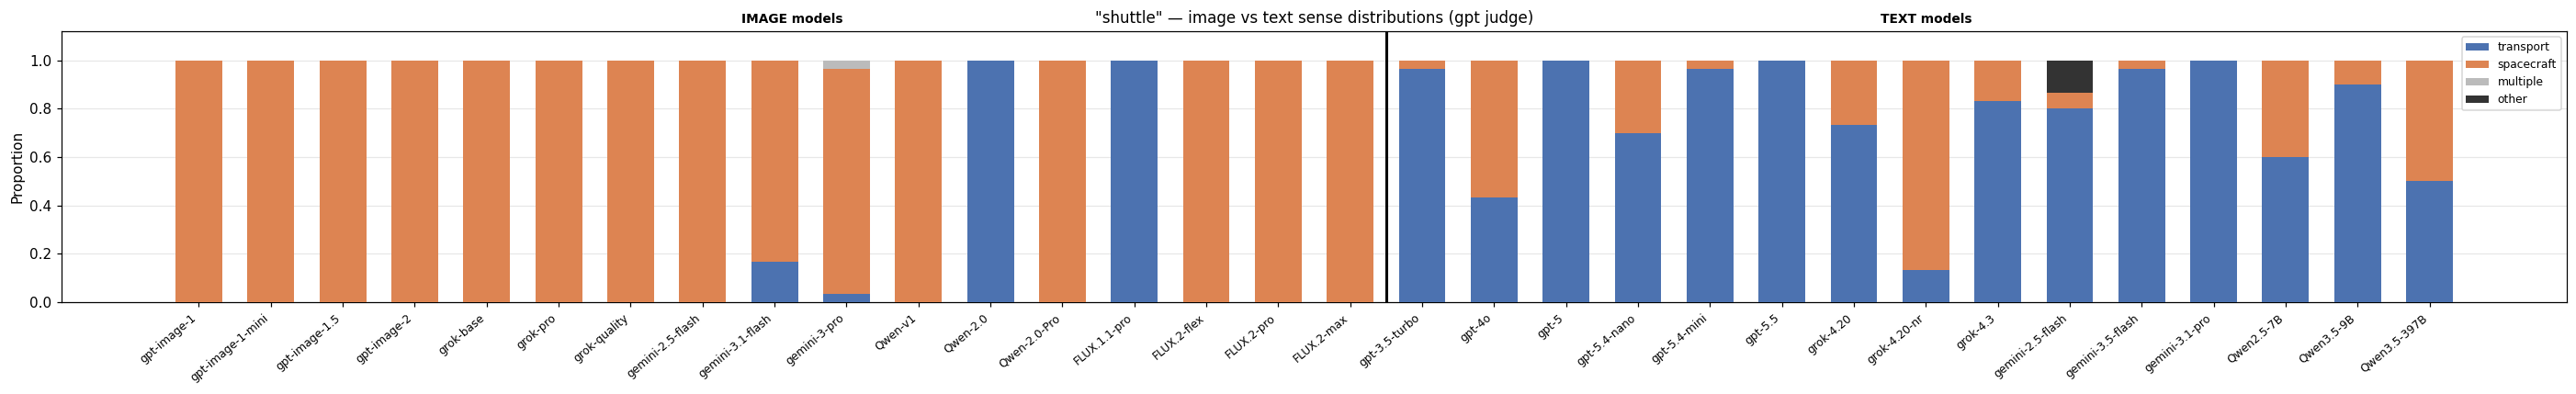

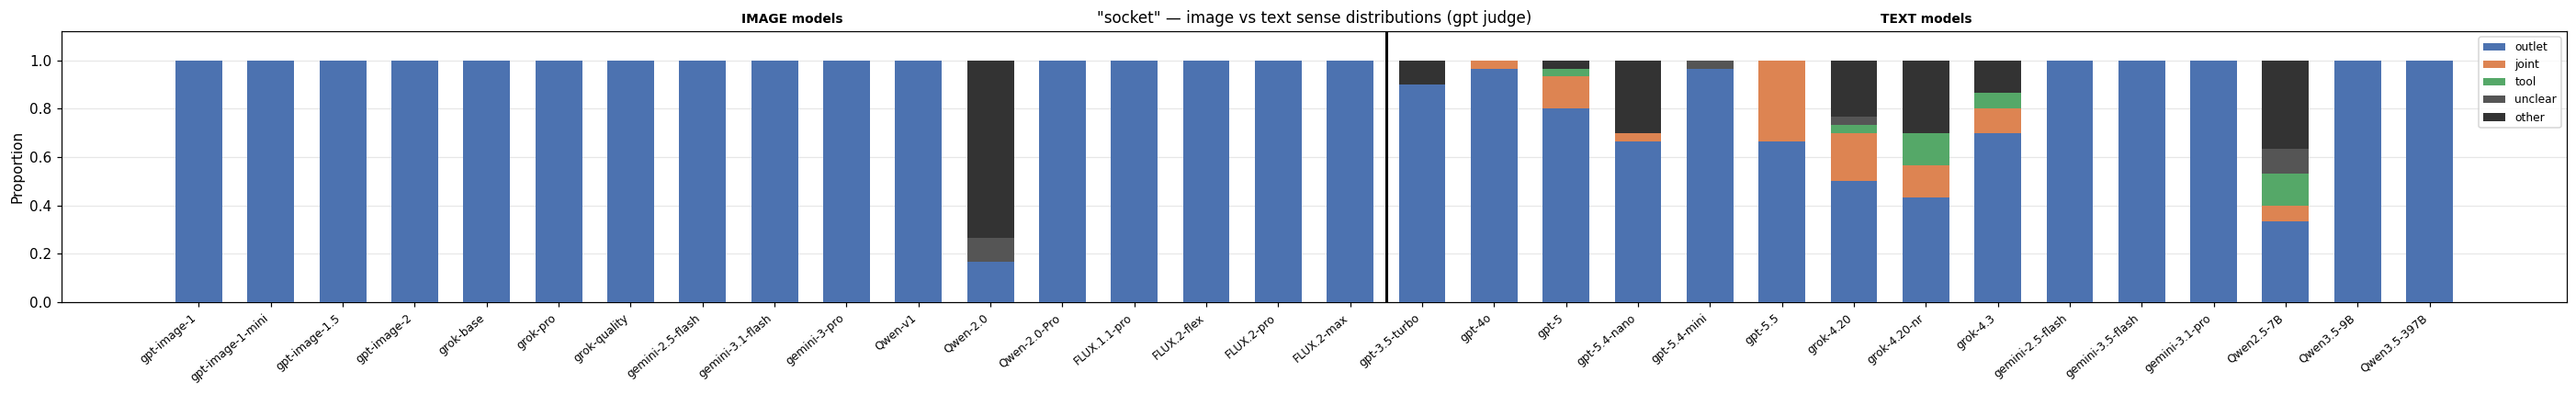

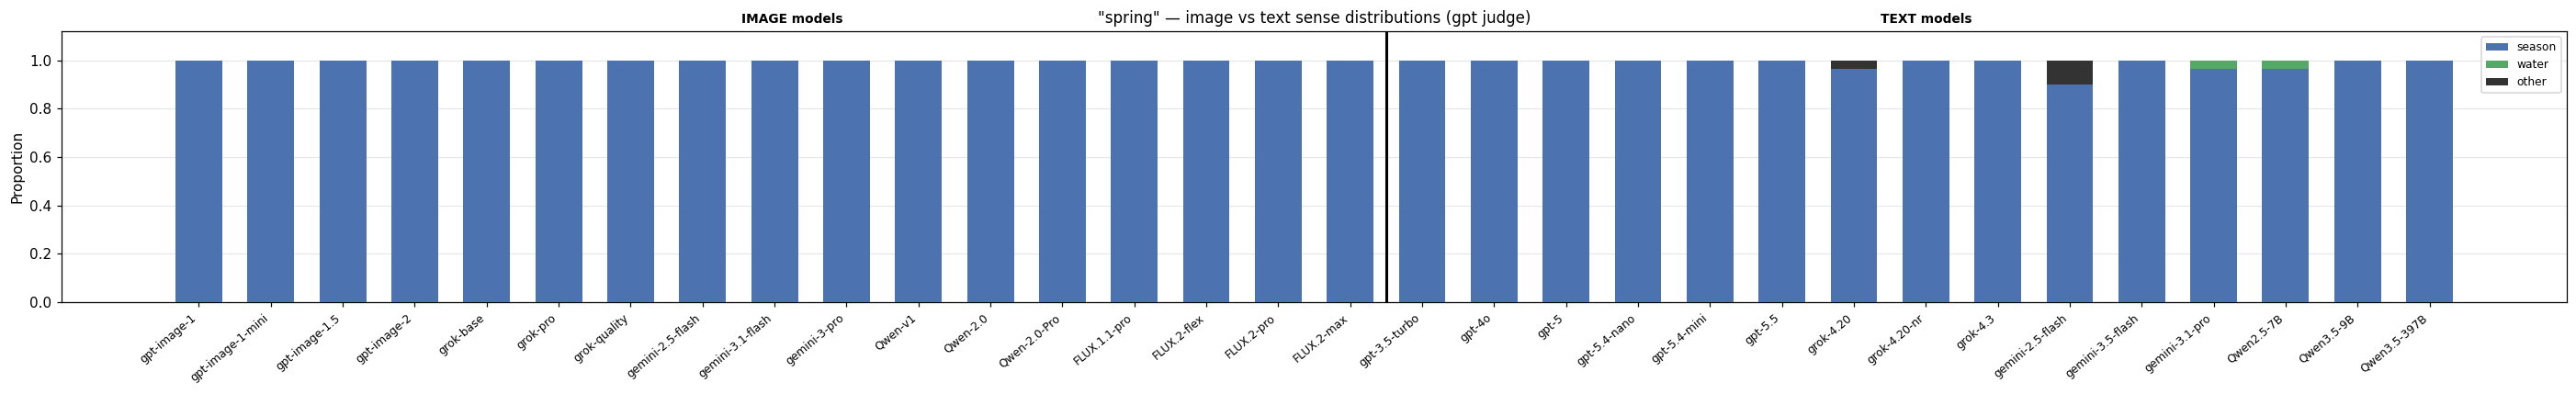

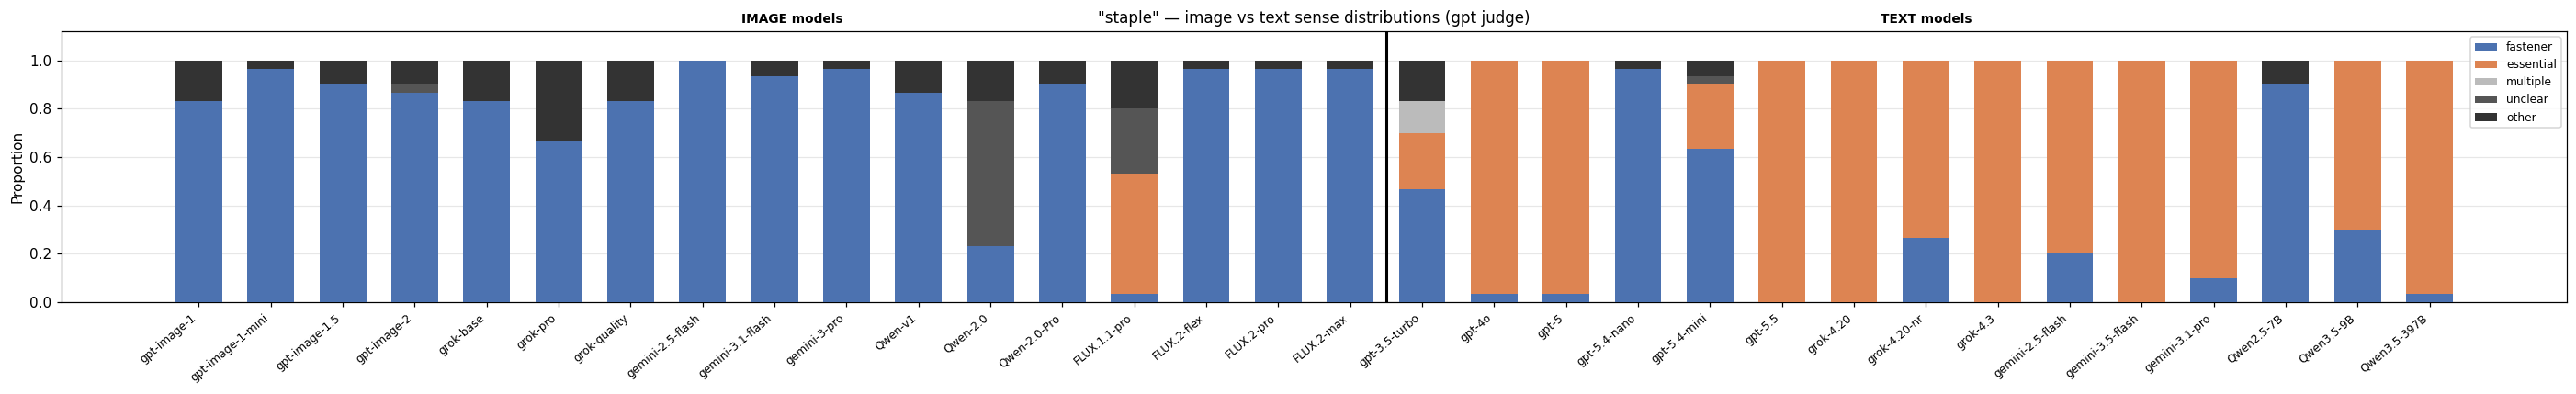

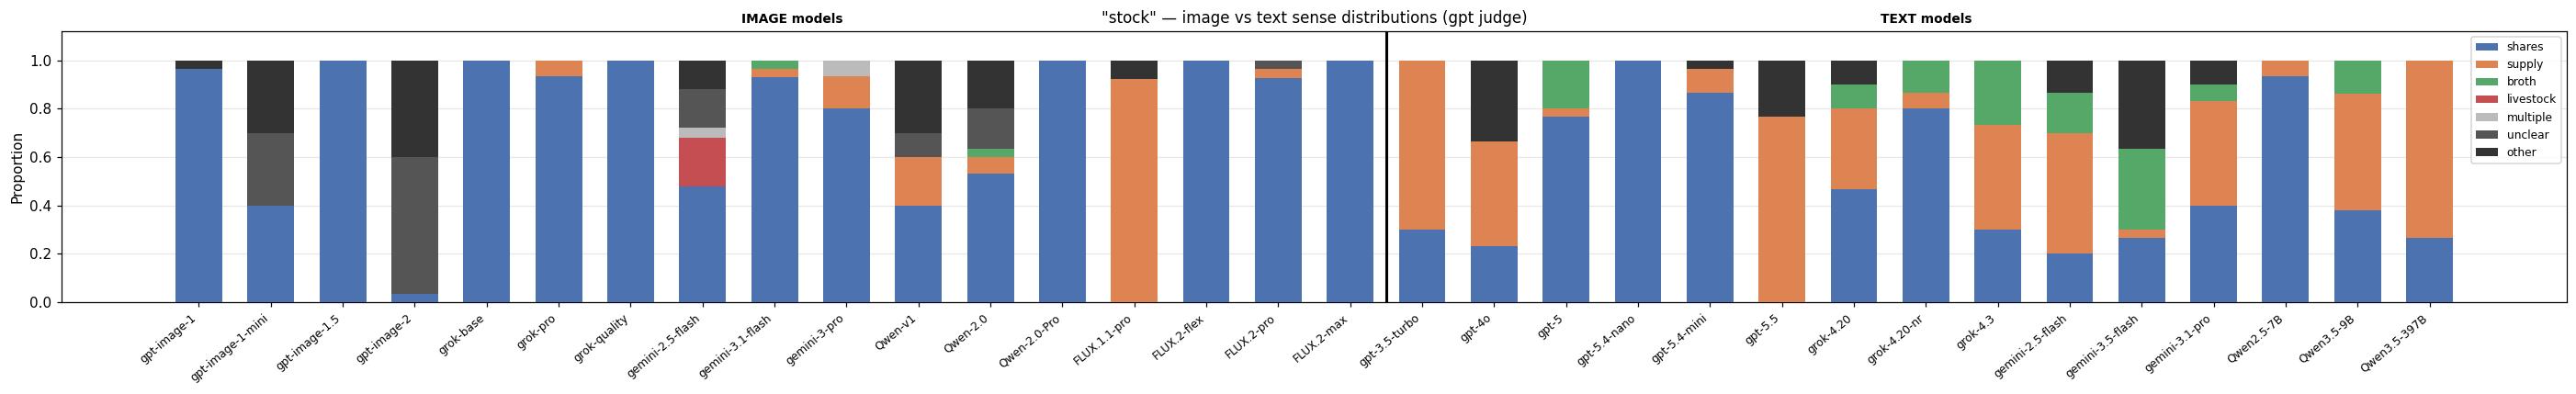

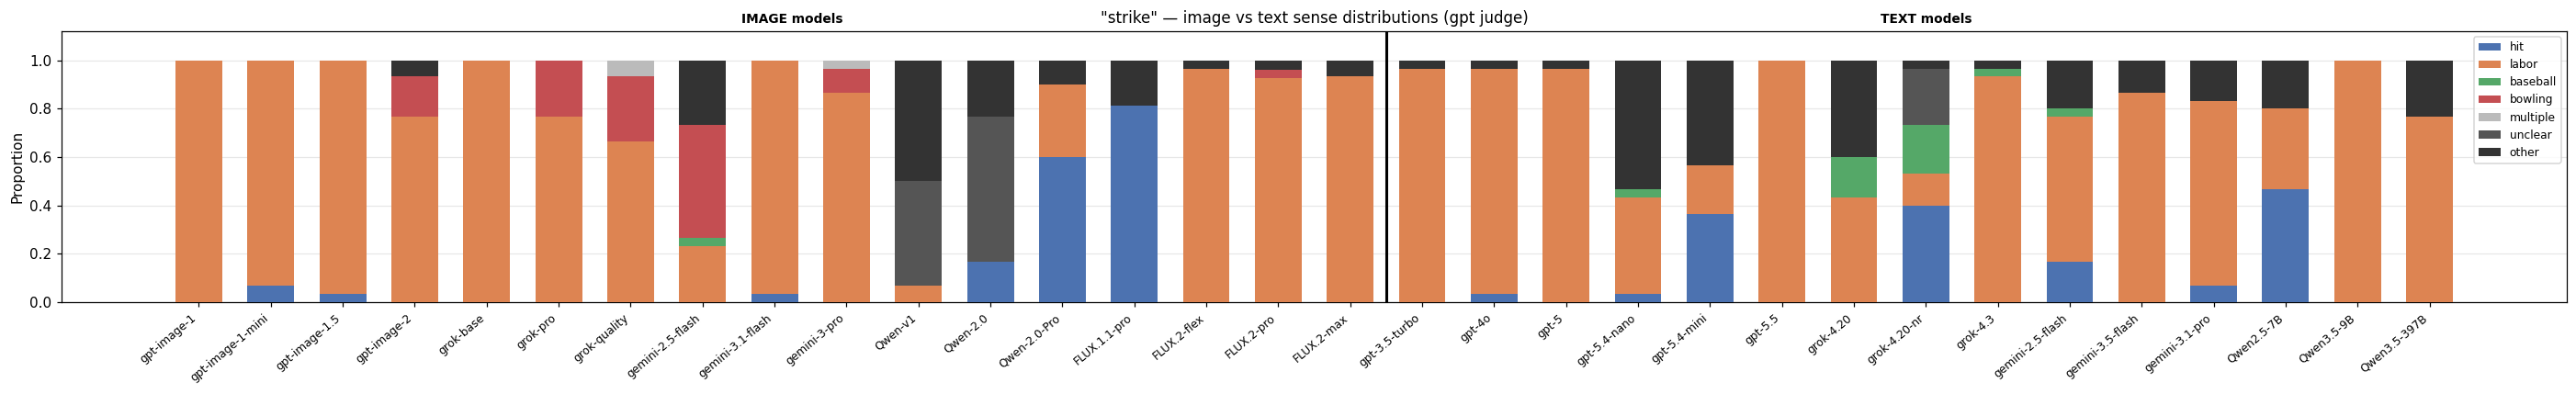

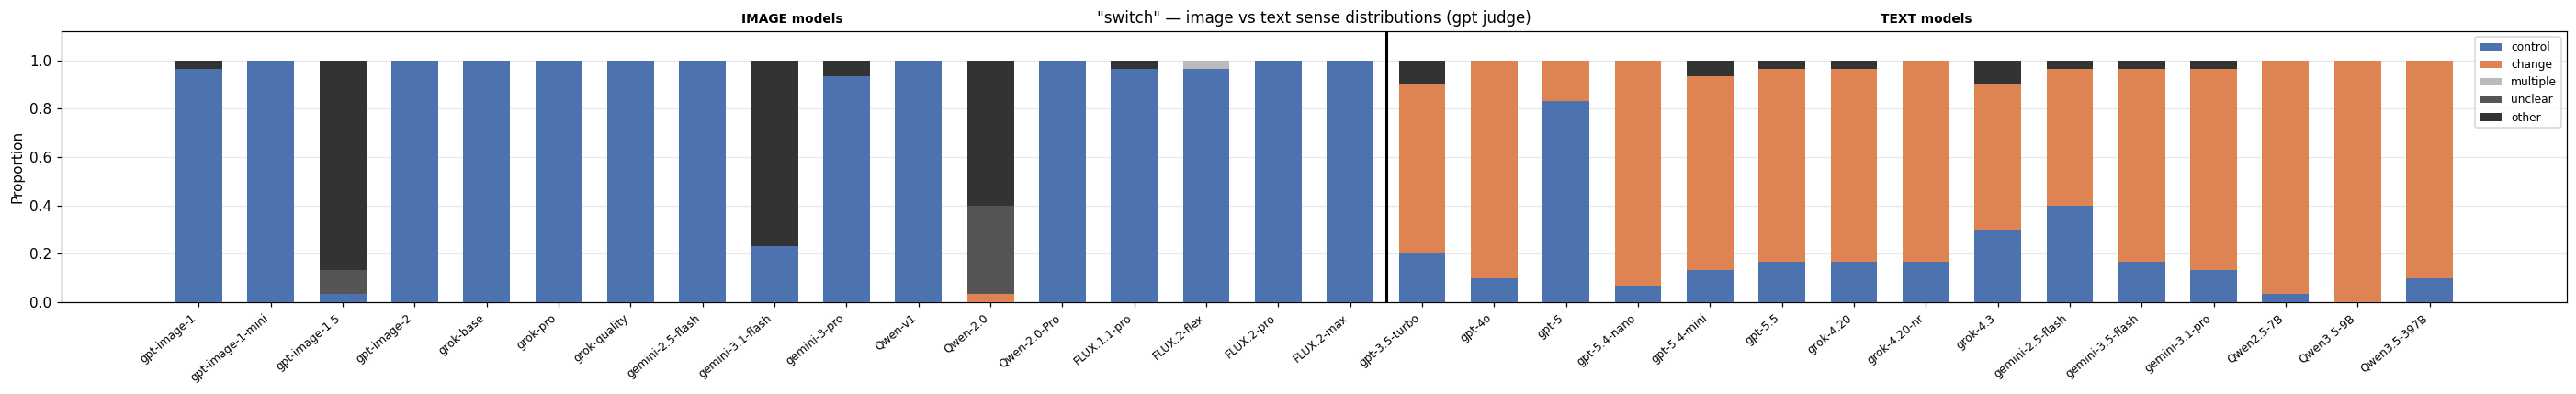

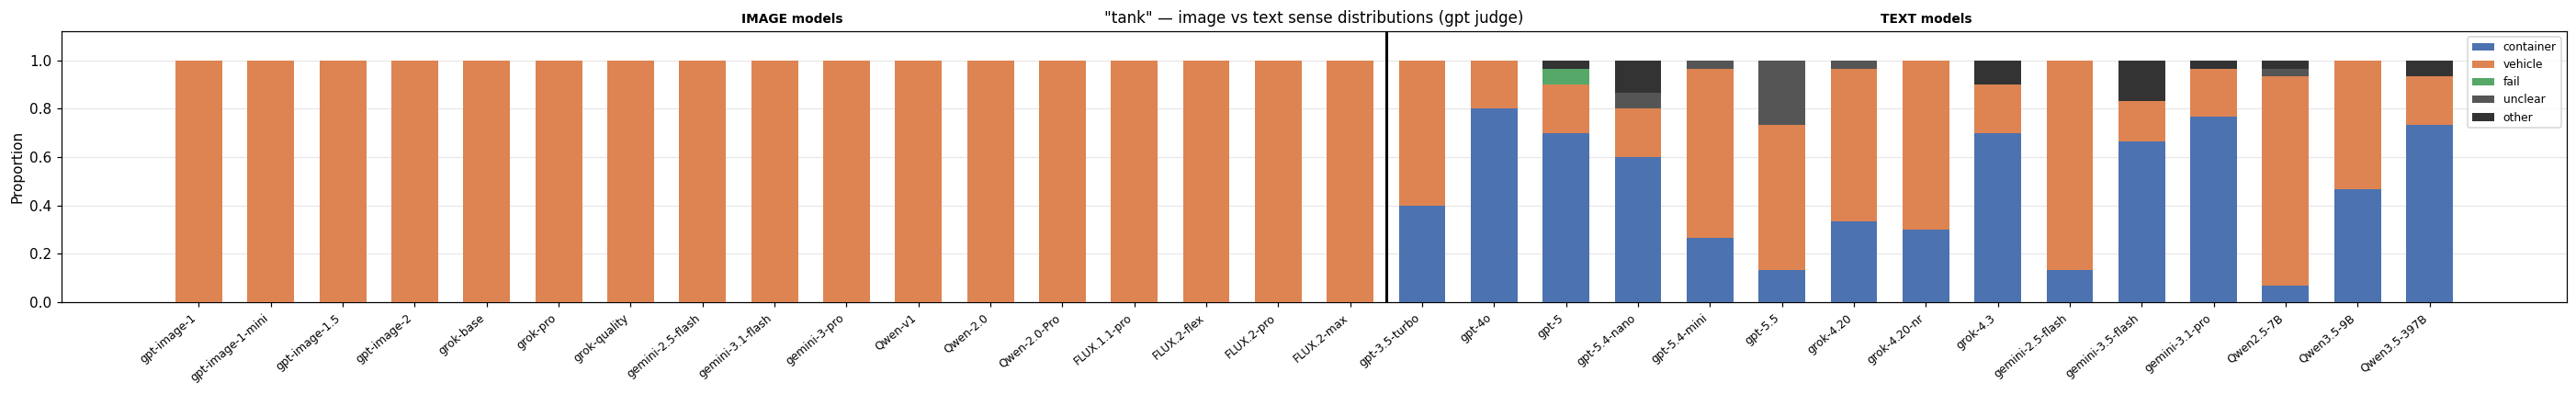

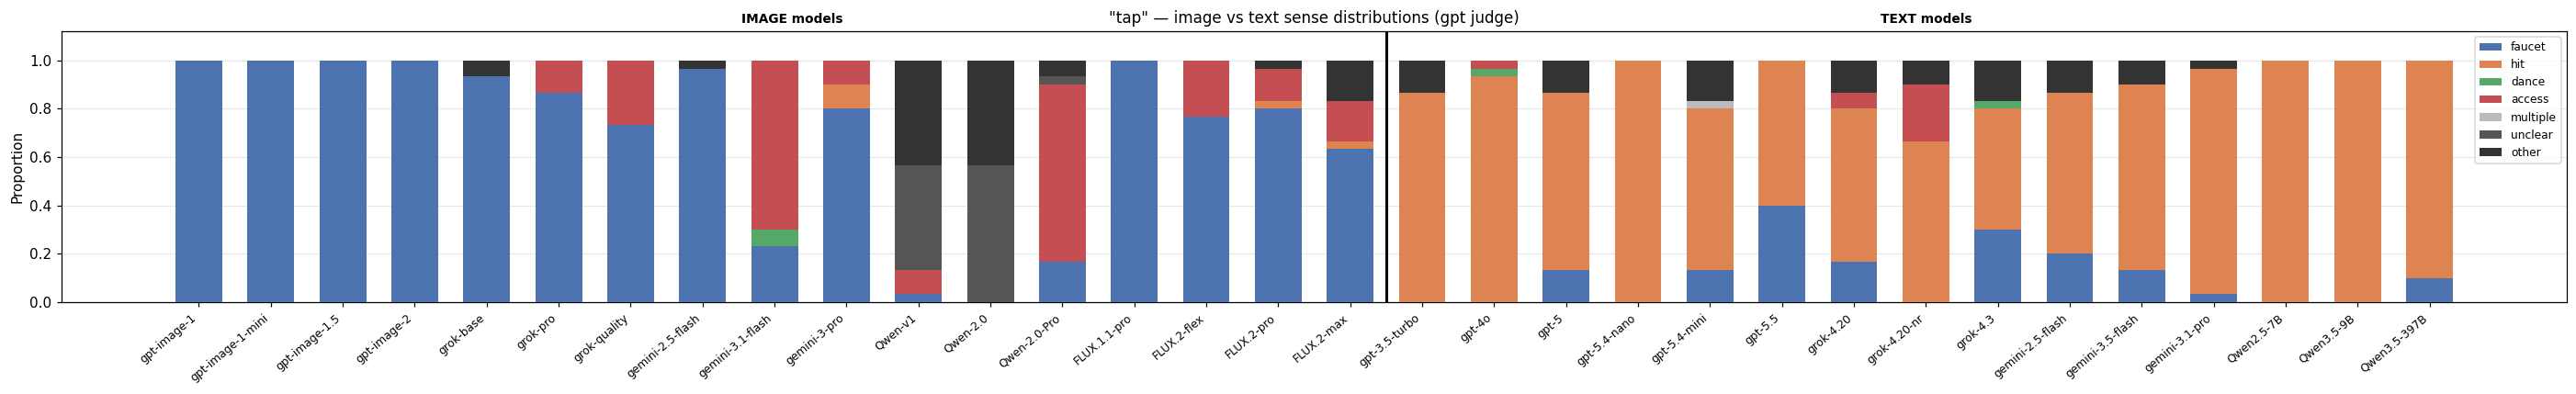

In [ ]:
def cross_modality_analysis(judge='gpt', agg='mean'):
    if not BOTH_WORDS:
        print('No words with data in both modalities.'); return

    img_groups = registry.family_groups('image')
    txt_groups = registry.family_groups('text')
    fams = [f for f in registry.families('image') if f in registry.families('text')]

    def _agg(word_data, keys, vocab, mode):
        present = [k for k in keys if k in word_data]
        if not present: return None
        if mode == 'latest':
            for k in reversed(present):
                d = dist_for(word_data[k], vocab, judge)
                if d is not None: return d
            return None
        dists = [d for k in present if (d := dist_for(word_data[k], vocab, judge)) is not None]
        if not dists: return None
        m = np.mean(dists, axis=0); s = m.sum()
        return m / s if s > 0 else None

    per_family = {f: [] for f in fams}
    per_word   = {w: [] for w in BOTH_WORDS}

    for word in BOTH_WORDS:
        merged = {**hist_image[word], **hist_text[word]}
        vocab  = get_vocab(word, merged, judge)
        for f in fams:
            img = _agg(hist_image[word], img_groups.get(f, []), vocab, agg)
            txt = _agg(hist_text[word],  txt_groups.get(f, []), vocab, agg)
            if img is None or txt is None: continue
            v = js(img, txt)
            if not np.isnan(v):
                per_family[f].append(v)
                per_word[word].append(v)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Panel 1: per-family
    fam_means = [(f, float(np.mean(v))) for f, v in per_family.items() if v]
    fam_means.sort(key=lambda x: x[1])
    ax = axes[0]
    y = np.arange(len(fam_means))
    ax.barh(y, [m for _, m in fam_means], color=[fcolor(f) for f, _ in fam_means], alpha=0.85)
    ax.set_yticks(y); ax.set_yticklabels([flabel(f) for f, _ in fam_means], fontsize=11)
    ax.set_xlabel('Mean JS(image ‖ text) over words (log₂)')
    ax.set_title(f'Per-family image-vs-text divergence ({agg} aggregate)\n'
                 'higher = image & text models resolve polysemy differently', fontsize=10)
    for i, (f, m) in enumerate(fam_means):
        ax.text(m + 0.003, i, f'{m:.3f}', va='center', fontsize=9)

    # Panel 2: per-word
    word_means = sorted(((w, float(np.mean(v))) for w, v in per_word.items() if v),
                        key=lambda x: x[1])
    ax2 = axes[1]
    y2 = np.arange(len(word_means))
    ax2.barh(y2, [m for _, m in word_means], color='#8E44AD', alpha=0.8)
    ax2.set_yticks(y2); ax2.set_yticklabels([w for w, _ in word_means], fontsize=11)
    ax2.set_xlabel('Mean cross-modality JS across families (log₂)')
    ax2.set_title('Per-word: how much does seeing vs reading differ?', fontsize=10)
    for i, (w, m) in enumerate(word_means):
        ax2.text(m + 0.003, i, f'{m:.3f}', va='center', fontsize=9)

    plt.suptitle(f'Image vs text sense resolution ({judge} judge, {len(BOTH_WORDS)} words in common)',
                 fontsize=12, y=1.02)
    plt.tight_layout(); plt.show()

    # Side-by-side per-word histograms for each BOTH_WORDS word
    print('\n── Per-word side-by-side comparison (image vs text) ──')
    for word in BOTH_WORDS:
        merged = {**hist_image[word], **hist_text[word]}
        vocab = get_vocab(word, merged, judge)
        senses = get_senses(word)
        all_labels = senses + [l for l in ['multiple', 'unclear', 'other'] if l in vocab]
        color_map = sense_colors(senses)

        img_cols = [m for m in IMAGE_MODELS if m in hist_image.get(word, {})]
        txt_cols = [m for m in TEXT_MODELS  if m in hist_text.get(word, {})]
        if not img_cols or not txt_cols: continue

        all_cols = img_cols + txt_cols
        n_img, n_txt = len(img_cols), len(txt_cols)
        x = np.arange(len(all_cols))
        fig, ax = plt.subplots(figsize=(max(12, len(all_cols) * 0.8), 4))
        bottoms = np.zeros(len(all_cols))
        for lbl in all_labels:
            idx = vocab.index(lbl) if lbl in vocab else -1
            vals = []
            for m, hist_d in [(m, hist_image) for m in img_cols] + [(m, hist_text) for m in txt_cols]:
                d = dist_for(hist_d[word][m], vocab, judge)
                vals.append(float(d[idx]) if d is not None and idx >= 0 else 0.0)
            vals = np.array(vals)
            if vals.sum() == 0: continue
            ax.bar(x, vals, 0.65, bottom=bottoms,
                   color=color_map.get(lbl, '#999'), label=lbl, zorder=3)
            bottoms += vals

        split = n_img - 0.5
        ax.axvline(split, color='black', lw=2, ls='-')
        ax.text(split / 2, 1.03, 'IMAGE models', ha='center', fontsize=9,
                fontweight='bold', transform=ax.get_xaxis_transform())
        ax.text((split + len(all_cols) - 0.5) / 2, 1.03, 'TEXT models',
                ha='center', fontsize=9, fontweight='bold',
                transform=ax.get_xaxis_transform())
        tick_labels = [dlabel(m) for m in img_cols] + [dlabel(m) for m in txt_cols]
        ax.set_xticks(x)
        ax.set_xticklabels(tick_labels, rotation=40, ha='right', fontsize=8)
        ax.set_ylim(0, 1.12); ax.set_ylabel('Proportion')
        ax.set_title(f'"{word}" — image vs text sense distributions ({judge} judge)', fontsize=11)
        ax.legend(loc='upper right', fontsize=8, framealpha=0.8)
        ax.grid(axis='y', alpha=0.3, zorder=0)
        plt.tight_layout(); plt.show()

cross_modality_analysis()

## 8. Model Geometry: PCA of Sense Distributions

Each model can be represented as a long feature vector: concatenate its per-word sense distributions across all words into a single vector. PCA then projects these high-dimensional vectors into 2D, preserving as much variance as possible.

Models that cluster together in the PCA biplot resolve polysemy similarly. Models that lie far apart have genuinely different 'views' of what ambiguous words mean.

Lines connect consecutive generations within each family, making generational drift visible as a trajectory in sense-space.

=== IMAGE PCA ===


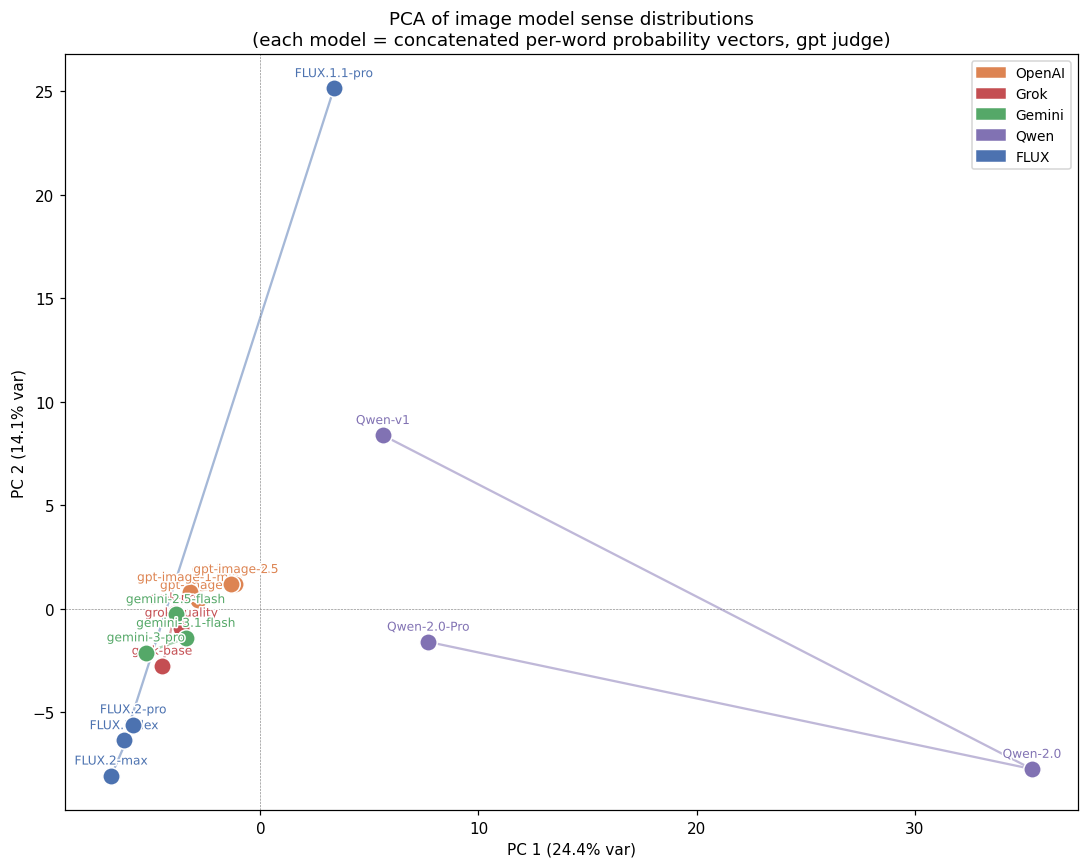

PCA variance explained: PC1=24.4%, PC2=14.1%


In [ ]:
def plot_pca(modality, judge='gpt'):
    hist = hist_image if modality == 'image' else hist_text
    models = IMAGE_MODELS if modality == 'image' else TEXT_MODELS
    words = list(hist)
    blocks = [(w, get_vocab(w, hist[w], judge)) for w in words]

    rows = []
    for m in models:
        vec = []
        for word, vocab in blocks:
            d = dist_for(hist[word][m], vocab, judge) if m in hist[word] else None
            vec.extend(d if d is not None else np.zeros(len(vocab)))
        rows.append(vec)
    X = np.array(rows)

    X_sc = StandardScaler().fit_transform(X)
    pca  = PCA(n_components=2, random_state=42)
    X2   = pca.fit_transform(X_sc)
    var  = pca.explained_variance_ratio_

    groups = registry.family_groups(modality)
    idx    = {m: i for i, m in enumerate(models)}

    fig, ax = plt.subplots(figsize=(10, 8))
    for m in models:
        color = fcolor(family_of(m))
        ax.scatter(X2[idx[m], 0], X2[idx[m], 1], color=color, s=130, zorder=3,
                   edgecolors='white', linewidths=1)
        txt = ax.text(X2[idx[m], 0], X2[idx[m], 1] + 0.012 * np.ptp(X2[:, 1]),
                      dlabel(m), fontsize=8, ha='center', va='bottom', color=color)
        txt.set_path_effects([pe.withStroke(linewidth=2, foreground='white')])

    for fam, keys in groups.items():
        color = fcolor(fam)
        ax.plot([X2[idx[m], 0] for m in keys],
                [X2[idx[m], 1] for m in keys],
                color=color, lw=1.5, alpha=0.5, zorder=2)

    fams = registry.families(modality)
    ax.legend(handles=[Patch(color=fcolor(f), label=flabel(f)) for f in fams],
              fontsize=9, loc='best')
    ax.set_xlabel(f'PC 1 ({var[0]:.1%} var)'); ax.set_ylabel(f'PC 2 ({var[1]:.1%} var)')
    ax.set_title(f'PCA of {modality} model sense distributions\n'
                 f'(each model = concatenated per-word probability vectors, {judge} judge)',
                 fontsize=12)
    ax.axhline(0, color='gray', lw=0.4, ls='--')
    ax.axvline(0, color='gray', lw=0.4, ls='--')
    plt.tight_layout(); plt.show()
    print(f'PCA variance explained: PC1={var[0]:.1%}, PC2={var[1]:.1%}')

print('=== IMAGE PCA ===')
plot_pca('image')

In [ ]:
print('=== TEXT PCA ===')
plot_pca('text')

## 9. Summary Statistics

Aggregated numbers across all words and models, useful for quick comparisons and for reporting headline results.

In [1]:
def summary_stats(judge='gpt', prior_name='manual'):
    freq = freq_manual if prior_name == 'manual' else freq_wiki
    rows = []
    for modality, hist, models in [('image', hist_image, IMAGE_MODELS),
                                    ('text',  hist_text,  TEXT_MODELS)]:
        for m in models:
            js_prior_vals, pairwise_vals = [], []
            for word, word_data in hist.items():
                if m not in word_data: continue
                vocab = get_vocab(word, word_data, judge)
                d     = dist_for(word_data[m], vocab, judge)
                if d is None: continue
                # JS from prior
                tf = text_dist(word, vocab, freq)
                if tf is not None:
                    v = js(tf, d)
                    if not np.isnan(v): js_prior_vals.append(v)
                # max sense probability (dominance)
                pairwise_vals.append(float(d.max()))

            if not pairwise_vals: continue
            rows.append({
                'Modality':       modality,
                'Model':          dlabel(m),
                'Family':         flabel(family_of(m)),
                'Words covered':  len(pairwise_vals),
                'Mean JS (prior)':f'{np.mean(js_prior_vals):.4f}' if js_prior_vals else 'n/a',
                'Mean dominance': f'{np.mean(pairwise_vals):.3f}',
            })

    df = pd.DataFrame(rows)
    display(df.sort_values(['Modality', 'Family', 'Model']).reset_index(drop=True))
    return df

df_summary = summary_stats()
print("\n'Mean dominance' = average probability mass on the top sense (1.0 = always picks the same sense)")

NameError: name 'freq_manual' is not defined

## 10. Key Findings & Next Steps

### What this benchmark reveals

1. **Models are not neutral** — every model exhibits a measurable bias toward certain senses of polysemous words even when given no context. These biases are systematic and reproducible.

2. **Family clustering is real** — the similarity matrix and PCA consistently show that models from the same provider cluster more tightly than cross-family pairs. Training data and RLHF pipelines leave a 'house style' imprint on semantic representations.

3. **Image and text modalities diverge** — across all 100 words, image models and text models from the same family often resolve polysemy differently, suggesting that visual and verbal 'meaning' are not fully unified even within a single lab.

4. **Newer is not always 'more natural'** — the generation trend plots show mixed evidence. Some families' newer models converge toward text-frequency priors; others diverge further.

5. **Some words are universal battlegrounds** — the inter-model disagreement chart identifies words where no model agrees with any other. These are the hardest polysemy cases and may serve as diagnostic probes for model behaviour.

### Limitations

- 13 text words are each missing 1–33 samples (out of 450 total per word) due to API errors during generation. Results for those words are based on slightly fewer samples but are still reliable.
- Judges (GPT and Gemini) may carry their own biases when classifying sense — inter-judge agreement should be reported alongside results.
- Words were chosen partly for clear senses and partly for being culturally salient brand names (e.g. Amazon, Jordan, Jaguar), which may skew results toward those associations.

### To extend this analysis

```bash
# Add a new model (one line in registry.py, then re-run eval + classify)
python -m llm_polysemy.eval --modality text --model <new_key>
python -m llm_polysemy.classify --modality text
python -m llm_polysemy.classify --modality text --histograms

# Regenerate all static figures
python -m llm_polysemy.plots.similarity --modality text
python -m llm_polysemy.plots.vs_textfreq --modality text
python -m llm_polysemy.plots.generation_trend --modality text
python -m llm_polysemy.plots.pca_tsne --modality text
python -m llm_polysemy.plots.word_disagreement --modality text
```
